# Step 3 of the PW: Present value of the top firms

| Question to answer (Presentation deck, Step 3) | How we measure it in this notebook |
|---|---|
| Which firms do we score, and why these? | The firms with the most mature families in the sector, above a minimum portfolio, plus the players that the press or Electrolux would name; and why some known players are missing (Section 2) |
| Who builds on the sector's patents, and how? | The citations of the sector, publication by publication: who adds them (applicant or examiner), their category (X, Y, A), how soon they arrive, links to science, and the citations between the top firms (Section 3, from Tutorial 3, notebook 30) |
| How much does the portfolio of a firm weigh in the sector? | **Volume**: its families divided by all the families of the sector, and how its share changes over time (Section 5.2) |
| Are its patents cited more than comparable patents? | **Influence**: citations received within five years, divided by the mean of the same CPC subclass and priority year in all of PATSTAT (Sections 4 and 5.5) |
| Are its applications granted? | **Success**: granted divided by filed applications, on filings old enough to have been decided (Section 5.3) |
| How international is it? | **Globalization**: mean number of jurisdictions per family, and the quadrilateral families of the Clarivate ranking (Section 5.4) |
| Where do the top firms invent? | Countries and European regions of their inventors, and whether citations stay local (Section 6, from Tutorial 3, notebook 31) |
| What is the present score of each firm? | The four indicators made comparable (ratio to the mean, or ranks), weighted for our sector and combined, then tested for robustness (Sections 7 to 9, from Tutorial 4, notebook 40) |

**Contents**

1. Setup and configuration
2. The firms
3. The citations of the sector (Tutorial 3, notebook 30)
4. The benchmark for Influence: citations of all of PATSTAT
5. The four indicators (Tutorial 4, notebook 40, Sections 4 to 7)
6. Where the top firms invent (Tutorial 3, notebook 31)
7. One score from four indicators (notebook 40, Section 8)
8. Is the ranking robust? (notebook 40, Section 9)
9. A refinement in the score (notebook 40, Section 10)
10. Answer for the deck, and the files for Step 5

## 1. Setup and configuration

Every choice that changes the results is set once, in the second cell, and explained next to it.

In [1]:
import hashlib
import json
import re
import textwrap
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats                      # Kendall's tau and Spearman's rho of the robustness checks (Section 8)
from sqlalchemy import and_, distinct, func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,                 # applications: DOCDB family, priority year, office, filing date, grant
    TLS202_APPLN_TITLE,           # titles (Section 2.4: the players our rule misses)
    TLS206_PERSON,                # persons: names, country, NUTS region, sector
    TLS207_PERS_APPLN,            # who is applicant or inventor of which application
    TLS209_APPLN_IPC,             # IPC classification (Section 2.4)
    TLS211_PAT_PUBLN,             # publications (Section 3)
    TLS212_CITATION,              # citations between publications, with their origin (Section 3)
    TLS214_NPL_PUBLN,             # non-patent literature: citations to science (Section 3)
    TLS215_CITN_CATEG,            # category of each citation: X, Y, A, I... (Section 3)
    TLS224_APPLN_CPC,             # CPC classification
    TLS228_DOCDB_FAM_CITN,        # citations between DOCDB families (Sections 2 and 4)
    TLS231_INPADOC_LEGAL_EVENT,   # legal events: EP validations (Section 5.4)
)

In [2]:
# ---------------------------------------------------------------- environment
ENV = "PROD"                                       # the tables that Step 0 v2 saved on PROD (on TEST the numbers mean nothing)

# the tables of our sector, saved by Step 0 v2 (Section 7): we look where Step 2 finds them, then next to this notebook
DATA_DIR = next((p for p in (Path("..") / "tutorial_0" / "data" / ENV / "humanoid_robots_v2",
                             Path("data") / ENV / "humanoid_robots_v2")
                 if (p / "dataset_metadata.json").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("dataset_metadata.json not found: the tables of Step 0 v2 (data/PROD/humanoid_robots_v2) "
                            "are neither in ../tutorial_0 nor here")
OUTPUT_DIR = Path("outputs/step3")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- our sector
SECTOR_NAME = "Humanoid robots"                    # the 2,907 families of Step 0 v2 (version 3 of the rule)

# ---------------------------------------------------------------- time window: we read it from Step 0, so the notebooks always agree
meta = json.loads((DATA_DIR / "dataset_metadata.json").read_text())
YEAR_MIN, YEAR_MAX = meta["window"]                # 2000-2025: earliest priority year of the family
LAST_COMPLETE_YEAR = meta["last_complete_year"]    # 2022: the later years are still being published

# ---------------------------------------------------------------- our choices for Step 3
HORIZON = 5                                        # years: citations are counted for this long after the priority year
INFLUENCE_LAST_YEAR = LAST_COMPLETE_YEAR - HORIZON       # last priority year with five complete years of citations
SUCCESS_LAST_YEAR = LAST_COMPLETE_YEAR - 2               # applications filed up to this year have mostly been decided (checked in Section 5.1)
GLOBALIZATION_LAST_YEAR = LAST_COMPLETE_YEAR - 1         # families up to this priority year have had time to enter the national phases (Section 5.1)
SPLIT_YEAR = 2015                                  # incumbent = first family in the sector before this year (same as Step 2)
N_FIRMS = 10                                       # how many firms we score at most (notebook 40, Section 3.2)
MIN_FAMILIES = 10                                  # the volume gate of notebook 40: a firm needs this many mature families to be scored
MIN_COHORT = 30                                    # a CPC subclass x priority year cohort needs this many families to be a benchmark
MIN_MATURE = 10                                    # an indicator resting on fewer mature families (applications for Success) is left empty

print(f"Sector: {SECTOR_NAME} | env: {ENV} | years {YEAR_MIN}-{YEAR_MAX} | complete years up to {LAST_COMPLETE_YEAR}")
print(f"Influence: priority years up to {INFLUENCE_LAST_YEAR} | Success: filings up to {SUCCESS_LAST_YEAR} | "
      f"Globalization: priority years up to {GLOBALIZATION_LAST_YEAR}")

Sector: Humanoid robots | env: PROD | years 2000-2025 | complete years up to 2022
Influence: priority years up to 2017 | Success: filings up to 2020 | Globalization: priority years up to 2021


In [3]:
patstat = PatstatClient(env=ENV)
db = patstat.orm()

DUMMY_APPLN_ID = 900_000_000         # PATSTAT creates dummy applications to keep the family structure: they are not real filings (same rule as Step 0)
REAL_APPLN = and_(TLS201_APPLN.appln_id > 0, TLS201_APPLN.appln_id < DUMMY_APPLN_ID)

# names of universities, institutes, labs and hospitals (the same words as Step 0, Section 7.2, and Step 2)
INSTITUTION_PATTERN = r"\b(?:UNIV\w*|INST\w*|ACADEM\w*|COLLEGE|SCHOOL|HOSPITAL|LAB\w*|CENT(?:ER|RE)|DAXUE|XUEYUAN)\b"

# the rule of Step 0 v2 (version 3): a humanoid term that names the robot in the title (Step 0, Section 5.19)
TERM_ROBOT = re.compile(
    r"(?<![a-z0-9])(?:humanoid|biped|bipedal|android|anthropomorphic|human-like|humanlike|human like|"
    r"human-shaped|human shaped|human-type|human type|human-form|two-legged|two legged)"
    r"\s+(?:[a-z0-9-]+\s+)?robots?(?![a-z0-9])"
    r"|人形机器人|人形機器人|仿人机器人|仿人機器人|类人机器人|類人機器人|双足机器人|雙足機器人|拟人机器人"
    r"|人型ロボット|人形ロボット|人間型ロボット|인간형 로봇|휴머노이드 로봇")


def answer_box(question, headline, detail=""):
    "Print the answer to one question of the deck, built from the numbers above (plain text, so that it also survives the PDF export)."
    print("-" * 80)
    print(f"ANSWER · {question}")
    for text in (headline, detail):
        if text:
            print(textwrap.fill(text, width=80))
    print("-" * 80)


def load_table(name):
    """A table saved by Step 0: parquet, or pickle if pyarrow was missing there."""
    for suffix, reader in ((".parquet", pd.read_parquet), (".pkl", pd.read_pickle)):
        if (DATA_DIR / f"{name}{suffix}").exists():
            return reader(DATA_DIR / f"{name}{suffix}")
    raise FileNotFoundError(f"{name} is not in {DATA_DIR}: run Step 0 v2 (Section 7) on {ENV} first")


def applicant_type(psn_sector):
    "Translate the PATSTAT psn_sector into the types used in the deck (same function as Step 2)."
    s = str(psn_sector).upper()
    if "UNIVERSITY" in s:
        return "university"
    if "COMPANY" in s:
        return "firm"
    if "GOV" in s:
        return "government / non-profit"
    if "HOSPITAL" in s:
        return "hospital"
    if "INDIVIDUAL" in s:
        return "individual"
    return "unknown"


def query_forward_citations(family_ids):
    """Every citing family of each family in `family_ids`, with the first priority year of the citing family.
    The same rule as the benchmark of Section 4: a family citing itself is dropped, dummy applications are ignored."""
    q = (db.query(TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.label("docdb_family_id"),
                  TLS228_DOCDB_FAM_CITN.docdb_family_id.label("citing_family"),
                  func.min(TLS201_APPLN.earliest_filing_year).label("citing_year"))
         .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == TLS228_DOCDB_FAM_CITN.docdb_family_id)
         .filter(REAL_APPLN,
                 TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.in_(family_ids),
                 TLS228_DOCDB_FAM_CITN.docdb_family_id != TLS228_DOCDB_FAM_CITN.cited_docdb_family_id)
         .group_by(TLS228_DOCDB_FAM_CITN.cited_docdb_family_id, TLS228_DOCDB_FAM_CITN.docdb_family_id))
    out = patstat.df(q)
    return out if len(out) else pd.DataFrame(columns=["docdb_family_id", "citing_family", "citing_year"])

## 2. The firms

### 2.1 Data of Step 0

Step 0 v2 saved the 2,907 families of the sector, their applications, their applicants (with the names already harmonised by the brand key, Section 7.2) and their CPC and IPC symbols. Three columns that Step 3 needs are computed here, so that every number of this step is counted with one rule:

- **`main_cpc_subclass`**: the CPC subclass that appears most often among the technology symbols of the family (Y tags excluded; the IPC subclass for the families without CPC, as in Step 1). It is the field of the family for the benchmark of Influence;
- **`n_fwd_cites_5y`**: the families that cite the family with a priority year up to its own priority year plus five, each citing family counted once. This is exactly what the benchmark of Section 4 counts for all of PATSTAT;
- **`fwd5_complete`**: the five years of citations are complete only for the priority years up to the last complete year minus five.

In [4]:
families = load_table("families")                                   # one row per family of the sector
applications = load_table("applications")                           # one row per application (patents of invention only)
family_applicants = load_table("family_applicants_grouped")         # one row per family and applicant (brand key, Step 0 v2 Section 7.2)
applicant_names = load_table("applicant_names")                     # one row per name as printed, with the applicant it was merged into
family_cpc = load_table("family_cpc")                               # the CPC symbols of the families
family_ipc = load_table("family_ipc")                               # the IPC subclasses, for the families without CPC

families = families[families["priority_year"].between(YEAR_MIN, YEAR_MAX)].copy()
SECTOR_IDS = [int(f) for f in families["docdb_family_id"]]

# 1. main CPC subclass: the most frequent subclass among the technology symbols (ties: alphabetical), IPC if no CPC
tech = family_cpc.loc[~family_cpc["is_tagging"], ["docdb_family_id", "subclass"]]
with_cpc = set(tech["docdb_family_id"])
tech = pd.concat([tech, family_ipc.loc[~family_ipc["docdb_family_id"].isin(with_cpc), ["docdb_family_id", "subclass"]]])
main_sub = (tech.groupby(["docdb_family_id", "subclass"]).size().rename("n").reset_index()
                .sort_values(["docdb_family_id", "n", "subclass"], ascending=[True, False, True])
                .drop_duplicates("docdb_family_id").set_index("docdb_family_id")["subclass"])
families["main_cpc_subclass"] = families["docdb_family_id"].map(main_sub).fillna("")

# 2. forward citations within HORIZON years of the priority year (all offices, as the benchmark)
fwd_pairs = query_forward_citations(SECTOR_IDS)
fwd_pairs = fwd_pairs.merge(families[["docdb_family_id", "priority_year"]], on="docdb_family_id")
fwd_pairs["lag"] = fwd_pairs["citing_year"] - fwd_pairs["priority_year"]      # years between the two priority years
within = fwd_pairs[fwd_pairs["citing_year"] <= fwd_pairs["priority_year"] + HORIZON]
families["n_fwd_cites_5y"] = families["docdb_family_id"].map(within.groupby("docdb_family_id")["citing_family"].nunique()).fillna(0).astype(int)
families["fwd5_complete"] = families["priority_year"] <= LAST_COMPLETE_YEAR - HORIZON
fwd_pairs.to_csv(OUTPUT_DIR / "forward_citation_pairs.csv", index=False)      # kept for the other windows (Section 5.5)

print(f"{SECTOR_NAME}: {len(families):,} families, {len(applications):,} applications, "
      f"{family_applicants['applicant'].nunique():,} applicants (brand key)")
print(f"main subclass found for {(families['main_cpc_subclass'] != '').sum():,} families "
      f"({families['docdb_family_id'].isin(with_cpc).sum():,} from CPC, the others from IPC)")
print(f"citing families: {fwd_pairs['citing_family'].nunique():,} | pairs within {HORIZON} years: {len(within):,} | "
      f"families with five complete years of citations: {int(families['fwd5_complete'].sum()):,}")
print("most frequent main subclasses:", families["main_cpc_subclass"].value_counts().head(6).to_dict())

Humanoid robots: 2,907 families, 3,714 applications, 1,239 applicants (brand key)
main subclass found for 2,902 families (2,099 from CPC, the others from IPC)
citing families: 8,409 | pairs within 5 years: 7,790 | families with five complete years of citations: 755
most frequent main subclasses: {'B25J': 1603, 'B62D': 388, 'G05D': 160, 'G05B': 141, 'G06F': 81, 'G06N': 46}


### 2.2 One firm, one name

Step 0 already merged the spellings of each applicant with the brand key and a few certain aliases (Step 0, Section 7.2): for example UBTECH with its Chinese name YOUBIXUAN, Unitree with YUSHU, and Aldebaran with SoftBank Robotics Europe. Notebook 40 asks us to check this once more before comparing firms, because a firm split in two looks half as big.

The cell lists, for each firm that matters for the deck, every applicant of the sector whose name contains its key, with the names that Step 0 merged into it. Two names of the same firm that are still apart are a candidate for `MERGE`. We keep the rule of Step 0: the owner is the applicant named on the patent, so a parent group and its subsidiary with different names stay apart unless they are the same company (a change of name, a translation).

In [5]:
NAME_KEYS = ["UBTECH", "SOFTBANK", "ALDEBARAN", "HONDA", "TOYOTA", "SONY", "SAMSUNG", "FOURIER", "ZHUJI", "LIGONG",
             "FIGURE", "UNITREE", "XIAOMI", "AGIBOT", "ZHIYUAN", "BOSTON DYNAMICS", "GOOGLE", "TESLA", "HYUNDAI",
             "AGILITY", "APPTRONIK", "ELECTROLUX"]

per_applicant = family_applicants.groupby("applicant")["docdb_family_id"].nunique()
merged_names = applicant_names.groupby("applicant")["name_raw"].agg(lambda s: "; ".join(sorted(set(s))[:4]))
rows = []
for key in NAME_KEYS:
    hits = per_applicant.index[per_applicant.index.str.contains(key, regex=False)
                               | per_applicant.index.isin(applicant_names.loc[applicant_names["name_raw"].str.upper()
                                                                               .str.contains(key, regex=False), "applicant"])]
    if len(hits) == 0:
        rows.append({"search key": key, "applicant (brand key)": "(no family in the sector)", "families": 0, "names merged by Step 0": ""})
    for applicant in hits:
        rows.append({"search key": key, "applicant (brand key)": applicant, "families": per_applicant[applicant],
                     "names merged by Step 0": merged_names.get(applicant, "")})
name_check = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90)
name_check

,search key,applicant (brand key),families,names merged by Step 0
0,UBTECH,UBTECH ROBOTICS,94,"SHENZHEN UBTECH TECHNOLOOGY CO., LTD.; UBTECH EDUCATION (SHENZHEN) CO., LTD.; UBTECH R..."
1,SOFTBANK,ALDEBARAN ROBOTICS,31,ALDEBARAN ROBOTICS; ALDEBARAN ROBOTIKS; SOFTBANK GROUP CORP; SOFTBANK GROUP CORP.
2,ALDEBARAN,ALDEBARAN ROBOTICS,31,ALDEBARAN ROBOTICS; ALDEBARAN ROBOTIKS; SOFTBANK GROUP CORP; SOFTBANK GROUP CORP.
3,HONDA,HONDA MOTOR,41,HONDA GIKEN KOGYO CO LTD ALSO TRADING AS HONDA MOTOR CO LTD; HONDA GIKEN KOGYO K. K.; ...
4,HONDA,HONDA RESEARCH INST EUROPE,1,HONDA RESEARCH INST EUROPE GMBH
5,HONDA,HONDA RESEARCH INSTITUTE EUROPE,1,HONDA RESEARCH INSTITUTE EUROPE GMBH
6,TOYOTA,TOYOTA CENTRAL R D LABS,1,TOYOTA CENTRAL R&D LABS INC
7,TOYOTA,TOYOTA MOTOR,25,"TOYOTA JIDOSHA CO LTD; TOYOTA MOTOR CO., LTD.; TOYOTA MOTOR CORP; Toyota Jidosha Kabus..."
8,SONY,SONY,2,SONY CORP
9,SAMSUNG,SAMSUNG ELECT,24,"SAMSUNG ELECT CO LTD; SAMSUNG ELECTRONICS CO LTD; SAMSUNG ELECTRONICS CO., LTD.; Samsu..."


In [6]:
# Merges that Step 0 did not make, checked by hand on the table above, for this step only. Leave it empty if the table
# shows no firm split in two. Form: "label shown in the deck": ["applicant as in the table", ...]
MERGE = {
    "UNITREE": ["HANGZHOU YUSHU TECH"],                         # Hangzhou Yushu Technology is Unitree's legal name in China
    "AGIBOT": ["SHANGHAI ZHIYUAN XINCHUANG TECHNOLOGY"],        # Zhiyuan Xinchuang (Shanghai) is AgiBot's legal name in China
    "XIAOMI ROBOT": ["BEIJING XIAOMI ROBOT TECH"],              # the robot company of the Xiaomi group, under its own name
    "HONDA RESEARCH INSTITUTE EUROPE": ["HONDA RESEARCH INST EUROPE", "HONDA RESEARCH INSTITUTE EUROPE"],   # one company, two spellings
    "ALDEBARAN ROBOTICS": ["ALDEBARAN ROBOTICS", "软银机器人欧洲公司"],      # the Chinese name of SoftBank Robotics Europe (formerly Aldebaran) on its CN filings
}

name_to_firm = {name: firm for firm, names in MERGE.items() for name in names}
missing = [n for names in MERGE.values() for n in names if n not in set(family_applicants["applicant"])]
print("names of MERGE that are not applicants of the sector (a typo):", missing or "none")

fam_firm = family_applicants[["docdb_family_id", "applicant", "applicant_type"]].copy()
fam_firm["firm"] = fam_firm["applicant"].map(name_to_firm).fillna(fam_firm["applicant"])
fam_firm = fam_firm.merge(families[["docdb_family_id", "priority_year"]], on="docdb_family_id")

# the type of each firm, with the rule of Step 2: the most frequent known type among its records; a name without
# university or institute words and without any type in PATSTAT (many recent Chinese filers) is read as a firm
fam_firm["type"] = fam_firm["applicant_type"].map(applicant_type)
known = fam_firm[fam_firm["type"] != "unknown"].groupby("firm")["type"].agg(lambda t: t.value_counts().index[0])
fam_firm["type"] = fam_firm["firm"].map(known).fillna("unknown")
no_type = fam_firm["type"].eq("unknown") & ~fam_firm["firm"].str.contains(INSTITUTION_PATTERN, regex=True)
fam_firm.loc[no_type, "type"] = "firm"
fam_firm = fam_firm.drop_duplicates(["docdb_family_id", "firm"])
print(f"{fam_firm['firm'].nunique():,} applicants after the merges; by type:",
      fam_firm.drop_duplicates("firm")["type"].value_counts().to_dict())

names of MERGE that are not applicants of the sector (a typo): none
1,237 applicants after the merges; by type: {'firm': 624, 'individual': 271, 'university': 239, 'unknown': 60, 'government / non-profit': 42, 'hospital': 1}


### 2.3 Which firms we score

Notebook 40 scores the firms with the most families, above a **minimum portfolio** (`MIN_FAMILIES`): with three families, one citation or one refusal changes a rate completely, and the indicator is noise. It is the same idea as the volume gate of the Clarivate ranking, scaled to one sector.

Our rule, written before looking at any score:

- only **firms** are scored: universities, institutes and individuals are not targets for an investment bank or for Electrolux (they appear in Steps 1 and 2);
- the portfolio is counted on the **mature families**, those with a priority year up to the limit of Globalization: a firm whose families all arrived in 2023-2025 cannot be measured on Influence, Success or Globalization, and a score built on Volume alone would only repeat its size. These firms are listed, and Step 4 scores them with forward-looking signals;
- we score the `N_FIRMS` firms with the most mature families, if they have at least `MIN_FAMILIES`;
- the **players that the press or Electrolux would name** are always shown, with their families in the sector: Section 2.4 explains why several of them have none.

In [7]:
NAMED_FIRMS = ["FIGURE AI", "UNITREE", "AGIBOT", "XIAOMI ROBOT", "BOSTON DYNAMICS", "TESLA", "HYUNDAI MOTOR", "1X TECHNOLOGIES",
               "AGILITY ROBOTICS", "APPTRONIK", "ELECTROLUX"]          # as written in the deck; Section 2.4 looks them up in all of PATSTAT

by_firm = fam_firm.groupby("firm")
mature_fam = fam_firm[fam_firm["priority_year"] <= GLOBALIZATION_LAST_YEAR]
firm_table = pd.DataFrame({
    "type": by_firm["type"].first(),
    "families": by_firm["docdb_family_id"].nunique(),
    "mature families": mature_fam.groupby("firm")["docdb_family_id"].nunique(),
    f"families since {SPLIT_YEAR}": fam_firm[fam_firm["priority_year"] >= SPLIT_YEAR].groupby("firm")["docdb_family_id"].nunique(),
    "mature for Influence": fam_firm[fam_firm["priority_year"] <= INFLUENCE_LAST_YEAR].groupby("firm")["docdb_family_id"].nunique(),
    "first year in the sector": by_firm["priority_year"].min(),
    "last year in the sector": by_firm["priority_year"].max(),
})
# a readable name for the deck: the most frequent spelling in Latin letters among the names merged into the firm
# (a few Japanese and Korean firms are labelled by Step 0 with their name in their own script)
latin = applicant_names[applicant_names["name_raw"].str.contains(r"[A-Za-z]", regex=True)].copy()
latin["firm"] = latin["applicant"].map(name_to_firm).fillna(latin["applicant"])
latin_name = latin.groupby("firm")["name_raw"].agg(lambda s: s.value_counts().index[0])
firm_table.insert(1, "name in Latin letters", firm_table.index.map(latin_name).fillna(""))
firm_table.insert(2, "example family", by_firm["docdb_family_id"].min())      # to look the firm up on Espacenet if needed

count_columns = ["families", "mature families", f"families since {SPLIT_YEAR}", "mature for Influence"]
firm_table[count_columns] = firm_table[count_columns].fillna(0).astype(int)
firm_table["status"] = np.where(firm_table["first year in the sector"] < SPLIT_YEAR, "incumbent", "entrant")   # same rule as Step 2

firms_only = firm_table[firm_table["type"] == "firm"].drop(columns="type").sort_values(["mature families", "families"], ascending=False)
eligible = firms_only[firms_only["mature families"] >= MIN_FAMILIES]
SELECTED = eligible.head(N_FIRMS).index.tolist()
print(f"{len(firms_only):,} firms in the sector; {len(eligible)} have at least {MIN_FAMILIES} mature families "
      f"(priority year up to {GLOBALIZATION_LAST_YEAR}); we score {len(SELECTED)}")
print("\nThe firms that we score")
display(firms_only.loc[SELECTED])

recent = firms_only[firms_only["mature families"] < MIN_FAMILIES].sort_values("families", ascending=False)
print(f"\nThe largest firms that we cannot score yet (fewer than {MIN_FAMILIES} mature families): Step 4 scores them")
display(recent.head(10))

named = pd.DataFrame({"families in the sector": [int(firms_only["families"].get(f, 0)) for f in NAMED_FIRMS],
                      "mature families": [int(firms_only["mature families"].get(f, 0)) for f in NAMED_FIRMS],
                      "scored here": [f in SELECTED for f in NAMED_FIRMS]}, index=NAMED_FIRMS)
print("\nThe players that the press or Electrolux would name")
named

624 firms in the sector; 8 have at least 10 mature families (priority year up to 2021); we score 8

The firms that we score


,name in Latin letters,example family,families,mature families,families since 2015,mature for Influence,first year in the sector,last year in the sector,status
firm,,,,,,,,,
UBTECH ROBOTICS,UBTECH ROBOTICS CORP.,58928263,94,59,94,9,2016,2025,entrant
HONDA MOTOR,HONDA MOTOR CO LTD,18782100,41,41,1,40,2000,2019,incumbent
ALDEBARAN ROBOTICS,ALDEBARAN ROBOTICS,39642951,31,28,7,28,2008,2023,incumbent
TOYOTA MOTOR,TOYOTA MOTOR CORP,32704934,25,25,1,25,2002,2017,incumbent
SAMSUNG ELECT,SAMSUNG ELECT CO LTD,32464598,24,22,2,22,2002,2024,incumbent
KAWADA KOGYO,KAWADA KOGYO KK,34644550,13,13,2,12,2003,2018,incumbent
TMSUK,TMSUK CO LTD,29244128,13,13,0,13,2002,2006,incumbent
LEJU SHENZHEN ROBOT TECHNOLOGY,"LEJU (SHENZHEN) ROBOT TECHNOLOGY CO., LTD.",59477149,14,10,14,1,2017,2024,entrant



The largest firms that we cannot score yet (fewer than 10 mature families): Step 4 scores them


,name in Latin letters,example family,families,mature families,families since 2015,mature for Influence,first year in the sector,last year in the sector,status
firm,,,,,,,,,
GUANGZHOU LIGONG INDUSTRIAL,"GUANGZHOU LIGONG INDUSTRIAL CO., LTD.",93579829,92,0,92,0,2024,2025,entrant
SHANGHAI FOURIER INTELLIGENT TECHNOLOGY,"SHANGHAI FOURIER INTELLIGENT TECHNOLOGY CO., LTD.",87404742,91,0,91,0,2023,2025,entrant
SHENZHEN ZHUJI POWER TECHNOLOGY,"SHENZHEN ZHUJI POWER TECHNOLOGY CO., LTD.",88011926,59,0,59,0,2023,2025,entrant
FIGURE AI,FIGURE AI INC,94976972,44,0,44,0,2023,2024,entrant
RENXING ROBOT SHANGHAI,"RENXING ROBOT (SHANGHAI) CO., LTD.",94568590,31,0,31,0,2025,2025,entrant
JIANGSU YUNMU ZHIZAO TECHNOLOGY,"JIANGSU YUNMU ZHIZAO TECHNOLOGY CO., LTD.",88897145,26,0,26,0,2023,2025,entrant
JINGSHI TECHNOLOGY SHANGHAI,"JINGSHI TECHNOLOGY (SHANGHAI) CO., LTD.",94184596,15,0,15,0,2024,2025,entrant
NANJING TETRA ELECTRONIC TECHNOLOGY,"NANJING TETRA ELECTRONIC TECHNOLOGY CO., LTD.",94016947,15,0,15,0,2024,2025,entrant
SHANGHAI KEPLER ROBOT,"SHANGHAI KEPLER ROBOT CO., LTD.",88379201,15,0,15,0,2023,2025,entrant



The players that the press or Electrolux would name


,families in the sector,mature families,scored here
FIGURE AI,44,0,False
UNITREE,5,0,False
AGIBOT,6,0,False
XIAOMI ROBOT,2,0,False
BOSTON DYNAMICS,0,0,False
TESLA,0,0,False
HYUNDAI MOTOR,0,0,False
1X TECHNOLOGIES,0,0,False
AGILITY ROBOTICS,1,0,False
APPTRONIK,6,1,False


**Our reading of the firms we score.** 624 of the 1,237 applicants are firms, but only 8 have at least 10 mature families (priority year up to 2021), so we score 8, not 10. Six are incumbents from Japan, Korea and France that filed most of their humanoid families before 2015: Honda (41 families, 2000-2019, one since 2015), Aldebaran / SoftBank Robotics Europe (31), Toyota (25), Samsung Electronics (24), Kawada Industries (13) and Tmsuk (13). Two are Chinese entrants: UBTECH (94 families, 59 mature, all from 2016) and Leju Robotics (14, 10 mature). The other largest firms of Step 2, Guangzhou Ligong (92 families), Shanghai Fourier (91), Shenzhen Zhuji (59) and Figure AI (44), filed all their families from 2023 on: they cannot be measured yet on Influence, Success or Globalization, and Step 4 scores them. The present score is therefore the score of the generation that built the first humanoids, plus UBTECH and Leju. This is what a present value can measure in a sector whose patenting exploded after 2022, and the deck must say it.

The check of the names found one more merge: the firm that PATSTAT names only in Chinese, 软银机器人欧洲公司 (SoftBank Robotics Europe), is Aldebaran itself on its Chinese filings. Its 12 families were all already counted under Aldebaran, so the merge removes a duplicate and leaves Aldebaran at 31 families.

### 2.4 The players our rule misses

Several of the best-known humanoid makers have no family, or almost none, in our sector (Step 2, Section 5.2). Before we score the firms, we check why, because the answer changes how the deck reads the ranking. There are two possible reasons:

- they **file patents that our rule does not catch**: the rule of Step 0 needs a humanoid term that names the robot in the title, and a firm may title its patents "legged robot", "robot" or "mobile robot";
- they **file few patents, or none**, in PATSTAT: a start-up can protect its technology with secrecy, or its applications may still be unpublished (18 months).

The query looks up each player by name among the applicants of all of PATSTAT (patents of invention, priority years of our window), and the table counts its families in robotics (IPC B25J manipulators, B62D57 legged and walking vehicles, G05D control of moving robots), how many of them have a humanoid term that names the robot in the title (our rule), how many have "legged", "walking" or "biped" in the title, and how many are in our sector. A name pattern can catch another firm with a similar name: the second table shows the names found, to check them.

In [8]:
PLAYERS = {                                       # name patterns, upper case, as in the applicant names of PATSTAT
    "BOSTON DYNAMICS": ["BOSTON DYNAMICS"],
    "TESLA": ["TESLA INC", "TESLA MOTORS"],
    "UNITREE": ["UNITREE", "HANGZHOU YUSHU"],
    "HYUNDAI MOTOR": ["HYUNDAI MOTOR"],
    "1X TECHNOLOGIES": ["1X TECHNOLOGIES", "HALODI ROBOTICS"],           # Halodi Robotics was the former name of 1X
    "AGILITY ROBOTICS": ["AGILITY ROBOTICS"],
    "APPTRONIK": ["APPTRONIK"],
    "FIGURE AI": ["FIGURE AI"],
    "AGIBOT": ["AGIBOT", "ZHIYUAN XINCHUANG"],
    "XIAOMI": ["XIAOMI"],
    "ELECTROLUX": ["ELECTROLUX"],
}
ROBOT_IPC = ("B25J", "B62D57", "G05D")             # manipulators, legged and walking vehicles, control of moving robots
LEGGED_WORDS = re.compile(r"(?<![a-z])(?:legged|walking|biped|quadruped|humanoid)")
PLAYERS_FILE = OUTPUT_DIR / "players_in_patstat.csv"     # saved, so that the long query runs only once


def query_players(players):
    "Applications of the players (real, patents of invention, priority years of the window), with the name that matched."
    patterns = [p for names in players.values() for p in names]
    name_match = or_(*[TLS206_PERSON.psn_name.like(f"%{p}%") for p in patterns])
    q = (db.query(TLS201_APPLN.appln_id, TLS201_APPLN.docdb_family_id, TLS201_APPLN.earliest_filing_year,
                  TLS206_PERSON.psn_name)
         .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
         .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
         .filter(REAL_APPLN, TLS201_APPLN.ipr_type == "PI", TLS207_PERS_APPLN.applt_seq_nr > 0,
                 TLS201_APPLN.earliest_filing_year.between(YEAR_MIN, YEAR_MAX), name_match)
         .distinct())
    return patstat.df(q)


def query_titles_and_ipc(appln_ids, chunk=5000):
    "The titles and the IPC subclasses of a list of applications."
    titles, ipc = [], []
    for start in range(0, len(appln_ids), chunk):
        part = appln_ids[start:start + chunk]
        titles.append(patstat.df(db.query(TLS202_APPLN_TITLE.appln_id, TLS202_APPLN_TITLE.appln_title)
                                 .filter(TLS202_APPLN_TITLE.appln_id.in_(part))))
        ipc.append(patstat.df(db.query(TLS209_APPLN_IPC.appln_id, TLS209_APPLN_IPC.ipc_class_symbol)
                              .filter(TLS209_APPLN_IPC.appln_id.in_(part))))
    return pd.concat(titles, ignore_index=True), pd.concat(ipc, ignore_index=True)


if PLAYERS_FILE.exists():
    player_apps = pd.read_csv(PLAYERS_FILE).fillna({"title": "", "ipc": ""})     # empty titles come back from the csv as NaN
else:
    t0 = time.time()
    player_apps = query_players(PLAYERS)
    titles, ipc = query_titles_and_ipc([int(a) for a in player_apps["appln_id"].unique()])
    titles["appln_title"] = titles["appln_title"].fillna("").astype(str).str.lower()
    ipc["code"] = ipc["ipc_class_symbol"].astype(str).str.replace(" ", "", regex=False)
    player_apps = (player_apps
                   .merge(titles.groupby("appln_id")["appln_title"].agg(" | ".join).rename("title"), on="appln_id", how="left")
                   .merge(ipc.groupby("appln_id")["code"].agg(" ".join).rename("ipc"), on="appln_id", how="left")
                   .fillna({"title": "", "ipc": ""}))
    player_apps.to_csv(PLAYERS_FILE, index=False)
    print(f"query: {len(player_apps):,} applications in {time.time() - t0:.0f} s")

# each application goes to the player whose pattern matches its applicant name as whole words: the database query
# looks for the pattern anywhere, so it also returns AN XIAOMING (a person) or CHANGZHOU YUSHUO (a car-parts firm)
PLAYER_RE = {p: re.compile(r"\b(?:" + "|".join(map(re.escape, pats)) + r")\b") for p, pats in PLAYERS.items()}


def player_of(name):
    name = str(name).upper()
    return next((p for p, rx in PLAYER_RE.items() if rx.search(name)), None)


player_apps["player"] = player_apps["psn_name"].map(player_of)
player_apps = player_apps[player_apps["player"].notna()]
fam = (player_apps.groupby(["player", "docdb_family_id"])
       .agg(title=("title", " | ".join), ipc=("ipc", " ".join), year=("earliest_filing_year", "min")).reset_index())
fam["robotics"] = fam["ipc"].apply(lambda s: any(c.startswith(ROBOT_IPC) for c in s.split()))
fam["names the humanoid robot"] = fam["title"].str.contains(TERM_ROBOT)
fam["legged words in the title"] = fam["title"].str.contains(LEGGED_WORDS)
fam["in our sector"] = fam["docdb_family_id"].isin(SECTOR_IDS)
rob = fam[fam["robotics"]]
players_table = pd.DataFrame({
    "families (all fields)": fam.groupby("player")["docdb_family_id"].nunique(),
    "in robotics": rob.groupby("player")["docdb_family_id"].nunique(),
    "robotics since 2015": rob[rob["year"] >= 2015].groupby("player")["docdb_family_id"].nunique(),
    "title names a humanoid robot": fam[fam["names the humanoid robot"]].groupby("player")["docdb_family_id"].nunique(),
    "legged / walking / biped in the title": rob[rob["legged words in the title"]].groupby("player")["docdb_family_id"].nunique(),
    "in our sector": fam[fam["in our sector"]].groupby("player")["docdb_family_id"].nunique(),
}).reindex(list(PLAYERS)).fillna(0).astype(int)
display(players_table)
print("\nNames found for each player (check that the pattern caught the right firm):")
player_apps.groupby("player")["psn_name"].agg(lambda s: "; ".join(sorted(set(s))[:5])).to_frame("names found")

,families (all fields),in robotics,robotics since 2015,title names a humanoid robot,legged / walking / biped in the title,in our sector
player,,,,,,
BOSTON DYNAMICS,210,186,161,0,15,0
TESLA,288,9,1,0,0,0
UNITREE,85,39,39,4,22,4
HYUNDAI MOTOR,80224,1639,1285,1,30,0
1X TECHNOLOGIES,2,2,2,0,0,0
AGILITY ROBOTICS,13,10,10,1,3,1
APPTRONIK,16,14,14,6,5,6
FIGURE AI,47,47,47,39,40,40
AGIBOT,241,131,131,5,5,5



Names found for each player (check that the pattern caught the right firm):


,names found
player,
1X TECHNOLOGIES,HALODI ROBOTICS; HALODI ROBOTICS AS
AGIBOT,"AGIBOT INNOVATION (SHANGHAI) TECHNOLOGY CO., LTD.; AGIBOT MEDTECH (SUZHOU) CO., LTD.; ..."
AGILITY ROBOTICS,AGILITY ROBOTICS
APPTRONIK,"APPTRONIK; APPTRONIK, INC"
BOSTON DYNAMICS,"BOSTON DYNAMICS; BOSTON DYNAMICS INC; BOSTON DYNAMICS, INC."
ELECTROLUX,AKTIEBOLAGET ELECTROLUX; ELECTROLUX; ELECTROLUX (CHINA) ELECTRIC APPLIANCE COMPANY; EL...
FIGURE AI,FIGURE AI; FIGURE AI INC.
HYUNDAI MOTOR,BEIJING HYUNDAI MOTOR COMPANY; HYUNDAI MOTOR; HYUNDAI MOTOR AMERICA; HYUNDAI MOTOR CO;...
TESLA,TESLA INC; TESLA INC.; TESLA MOTORS; TESLA MOTORS CANADA ULC


In [9]:
# Robotics titles of the players that are NOT in our sector: what do they call their robots? (five per player)
examples = (rob[~rob["in our sector"]].sort_values("year", ascending=False)
            .groupby("player").head(5)[["player", "year", "title"]])
examples["title"] = examples["title"].str.split(" | ", regex=False).str[0].str.slice(0, 110)
examples

,player,year,title
175,AGIBOT,2025,"dexterous hand finger, dexterous hand and robot"
176,AGIBOT,2025,"task arrangement method, robot control method and robot control system"
148,AGIBOT,2025,joint module and robot
120594,XIAOMI,2025,"robot control method and device, electronic equipment and storage medium"
120351,XIAOMI,2025,control method of mobile equipment and related device
119926,XIAOMI,2025,"task action generation method and device, robot, electronic equipment and medium"
119560,XIAOMI,2025,"temperature determination method and device, temperature control equipment, electronic..."
119472,XIAOMI,2025,"robot control method, system, device, equipment and medium"
199,AGIBOT,2025,joint module and robot
197,AGIBOT,2025,dexterous hand and robot


**Our reading of the players our rule misses.** They are missing for two different reasons.

- **They patent robots, but their titles do not name a humanoid.** Boston Dynamics has 186 robotics families (161 since 2015) and not one title names a humanoid robot: they are about mobile and legged robots, and the firm also makes the quadruped Spot and the warehouse robot Stretch, so its robotics patents are not all about humanoids. Hyundai Motor has 1,639 robotics families and one humanoid title; Xiaomi 432 and one; Unitree 39, of which 22 have "legged", "walking" or "biped" in the title and 4 are in our sector. AgiBot has 131 robotics families since 2015, and only 5 name the humanoid: the others are titled "wrist structure and robot", "dexterous hand and robot", "joint module and robot".
- **They patent little, or not yet.** Tesla has 9 robotics families in our window, one since 2015; 1X has 2 (under its former name, Halodi Robotics); Agility Robotics 10.

From the title alone, no rule can tell that "dexterous hand and robot" by AgiBot belongs to a humanoid while the same words from another firm describe an industrial gripper. Step 0 tried wider rules, and their precision fell below 70% (blocks B and C, R, W). What is missing is information about the firm, not about the patent. For the present score this changes little: the firms that make only humanoids (Figure AI, Apptronik, Agility Robotics, 1X, AgiBot) are young, and most of their families are too recent to be measured here. It matters for Step 4, where these firms can be followed through all their robotics families after a check by reading a sample.

Electrolux, our client, has 4,494 families in our window and 66 in robotics: robotic cleaners and a "robot arm for a domestic appliance, in particular for a kitchen appliance" (2020). None names a humanoid.

## 3. The citations of the sector (Tutorial 3, notebook 30)

Section 2 counted the citations between **families** (TLS228): it covers all the offices, but it does not say who added a citation or why. Notebook 30 goes one level down, to the **publications** (TLS211) and their citations (TLS212), where each citation has an **origin** (the applicant `APP`, or the examiner: `SEA` search, `ISR` international search, `EXA` examination, ...) and a **category** given by the search examiner (TLS215: `X` and `I` relevant on their own, `Y` in combination, `A` background). We follow its path through the schema for the families of our sector, and answer four questions for the deck:

1. who adds the citations of our sector, and how close is the prior art (3.1);
2. do the firms of the sector build on each other's patents (3.2);
3. who builds on the sector, and how soon (3.3);
4. how much does the sector rely on science (3.4).

As in notebook 30, we keep the **EP publications** whenever the origin or the category matters: at the USPTO applicants must disclose all the prior art they know, so their citations follow another practice, and the Chinese office records few applicant citations. This has a price for our sector: only a minority of its families has an EP application (the next cell counts them), so every share of this section rests on fewer families than Sections 4 and 5. Each table says how many citations it is based on, and we do not read much into shares computed on a few dozen citations.

In [10]:
def in_chunks(ids, make_query, chunk=10_000):
    "Run make_query(list_of_ids) on chunks of ids, so that no query carries a list too long, and stack the results."
    ids = [int(i) for i in pd.unique(pd.Series(ids))]
    parts = [patstat.df(make_query(ids[start:start + chunk])) for start in range(0, len(ids), chunk)]
    parts = [p for p in parts if len(p)]
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()


# the firm of each family, to name the families in the tables: when a family has several applicants, the one with
# the most families in the sector (universities and individuals keep their own name)
size_in_sector = fam_firm.groupby("firm")["docdb_family_id"].nunique()
main_firm = (fam_firm.assign(size=fam_firm["firm"].map(size_in_sector))
             .sort_values(["docdb_family_id", "size"], ascending=[True, False])
             .drop_duplicates("docdb_family_id").set_index("docdb_family_id")["firm"])
year_of_family = families.set_index("docdb_family_id")["priority_year"]          # priority year of each family of the sector

appln_family = applications.set_index("appln_id")["docdb_family_id"]
ep_apps = applications[applications["appln_auth"] == "EP"]
print(f"applications of the sector: {len(applications):,} | EP applications: {len(ep_apps):,}, "
      f"in {ep_apps['docdb_family_id'].nunique():,} of {len(families):,} families "
      f"({ep_apps['docdb_family_id'].nunique() / len(families):.1%})")

# 1. all the publications of the applications of the sector, any office (TLS211)
pubs = in_chunks(applications["appln_id"], lambda part: db.query(
    TLS211_PAT_PUBLN.pat_publn_id, TLS211_PAT_PUBLN.appln_id, TLS211_PAT_PUBLN.publn_auth,
    TLS211_PAT_PUBLN.publn_kind, TLS211_PAT_PUBLN.publn_date).filter(TLS211_PAT_PUBLN.appln_id.in_(part)))
pubs["docdb_family_id"] = pubs["appln_id"].map(appln_family)
print(f"publications: {len(pubs):,} ({pubs['publn_auth'].value_counts().head(5).to_dict()})")

applications of the sector: 3,714 | EP applications: 83, in 76 of 2,907 families (2.6%)
publications: 5,470 ({'CN': 3547, 'US': 450, 'JP': 409, 'KR': 307, 'WO': 186})


### 3.1 Who adds the citations of our sector, and how close is the prior art?

The citations **made** by the EP publications of the sector (backward citations). One application has several publications (A1 with the search report, B1 when granted...), and each can carry citations, so we take them all and count each cited document once per application (notebook 30, Section 5.2).

In [11]:
ep_pubs = pubs.loc[pubs["publn_auth"] == "EP", "pat_publn_id"]

# 2. the citations made by the EP publications of the sector (TLS212), patents and non-patent literature
back = in_chunks(ep_pubs, lambda part: db.query(
    TLS212_CITATION.pat_publn_id, TLS212_CITATION.citn_replenished, TLS212_CITATION.citn_id, TLS212_CITATION.citn_origin,
    TLS212_CITATION.cited_pat_publn_id, TLS212_CITATION.cited_npl_publn_id).filter(TLS212_CITATION.pat_publn_id.in_(part)))
back["citn_origin"] = back["citn_origin"].astype(str).str.strip()
back["citing_appln_id"] = back["pat_publn_id"].map(pubs.set_index("pat_publn_id")["appln_id"])
back["citing_family"] = back["citing_appln_id"].map(appln_family)

# 3. the category of each citation (TLS215): one citation can have several letters, we keep them all once
categ = in_chunks(ep_pubs, lambda part: db.query(
    TLS215_CITN_CATEG.pat_publn_id, TLS215_CITN_CATEG.citn_replenished, TLS215_CITN_CATEG.citn_id,
    TLS215_CITN_CATEG.citn_categ).filter(TLS215_CITN_CATEG.pat_publn_id.in_(part)))
KEYS = ["pat_publn_id", "citn_replenished", "citn_id"]
if len(categ):
    categ["letter"] = categ["citn_categ"].astype(str).str.strip().apply(list)
    letters = categ.explode("letter").groupby(KEYS)["letter"].agg(lambda s: "".join(sorted(set(s)))).rename("letters")
    back = back.merge(letters.reset_index(), on=KEYS, how="left")
else:
    back["letters"] = np.nan

# 4. the cited patent publications: their office and their family
pat = back[back["cited_pat_publn_id"] > 0].copy()
cited = in_chunks(pat["cited_pat_publn_id"], lambda part: db.query(
    TLS211_PAT_PUBLN.pat_publn_id.label("cited_pat_publn_id"), TLS211_PAT_PUBLN.publn_auth.label("cited_office"),
    TLS201_APPLN.docdb_family_id.label("cited_family"))
    .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS211_PAT_PUBLN.pat_publn_id.in_(part)))
pat = pat.merge(cited, on="cited_pat_publn_id", how="left")
pat = pat[pat["citing_family"] != pat["cited_family"]]
print(f"EP publications of the sector: {ep_pubs.nunique():,} | citations they make: {len(back):,} "
      f"({len(pat):,} to patents, {(back['cited_pat_publn_id'] <= 0).sum():,} to non-patent literature)")

# who adds the citations: the share of each origin, counting each (application, cited document, origin) once
who = pat.drop_duplicates(["citing_appln_id", "cited_pat_publn_id", "citn_origin"])["citn_origin"].value_counts()
origin_table = pd.DataFrame({"citations": who, "share (%)": (who / who.sum() * 100).round(1)})
display(origin_table)

# how close is the prior art: the letters of the search citations
with_letter = pat["letters"].notna()
letter_counts = pat.loc[with_letter, "letters"].str.split("").explode().loc[lambda s: s != ""].value_counts()
print(f"citations to patents with a category: {with_letter.mean():.0%} "
      f"(the categories come from the search: origins {sorted(pat.loc[with_letter, 'citn_origin'].unique())})")
print(f"share of categorised citations that are X or I (prior art that alone threatens novelty or inventive step): "
      f"{pat.loc[with_letter, 'letters'].str.contains('[XI]').mean():.0%}")
letter_counts.rename("citations").to_frame()

EP publications of the sector: 162 | citations they make: 576 (443 to patents, 132 to non-patent literature)


,citations,share (%)
citn_origin,,
ISR,208,47.0
SEA,147,33.2
APP,80,18.1
EXA,8,1.8


citations to patents with a category: 80% (the categories come from the search: origins ['ISR', 'SEA'])
share of categorised citations that are X or I (prior art that alone threatens novelty or inventive step): 21%


,citations
letters,
A,228
Y,87
X,71
I,26
P,17
D,3
E,2


**Our reading of the citations made by the sector.** Only 76 of the 2,907 families (2.6%) have an EP application: the sector files in China, Japan, Korea and the United States, and rarely through the European Patent Office. For Electrolux, a European group, this is a finding in itself. It also means that every EP-based number of this section rests on few documents. The 162 EP publications of the sector cite 443 patent documents and 132 non-patent ones. Most citations come from the examiners, the international search report (47%) and the European search (33%); the applicants add 18%, as is usual at the EPO. Of the categorised citations, 21% are X or I, prior art that alone questions novelty or inventive step; most are background (A, 228 citations) or relevant in combination (Y, 87). The course gives two readings of backward citations: much prior art passed (a sign of quality) or very close prior art (a weaker patent). We take the second one only for the X and I citations, and otherwise read backward citations as a description of the prior art, not as a quality indicator: none of them enters the score.

### 3.2 Do the firms of the sector build on each other's patents?

A citation **inside** the sector (both the citing and the cited family are in our 2,907) links two applicants. Notebook 30 draws the network of these links between the largest firms, keeping only the citations added by the **applicants**: an examiner citation says that the cited patent is relevant prior art, not that the citing firm knew it, so it is not a trace of a knowledge flow.

With only the EP publications, our sector may have very few applicant citations inside it. If the largest firms have fewer than `MIN_EDGES` such links, we draw instead the citations between **families** of Step 0 (TLS228: all offices, applicant and examiner citations together), and the title of the picture says which one it is. Read it then as "whose patents are relevant prior art for whom", not as a proof that one firm learned from the other.

applicant citations inside the sector: 11; between the 12 largest firms: 4
too few: we use the citations between families instead (2,750 pairs of families inside the sector)


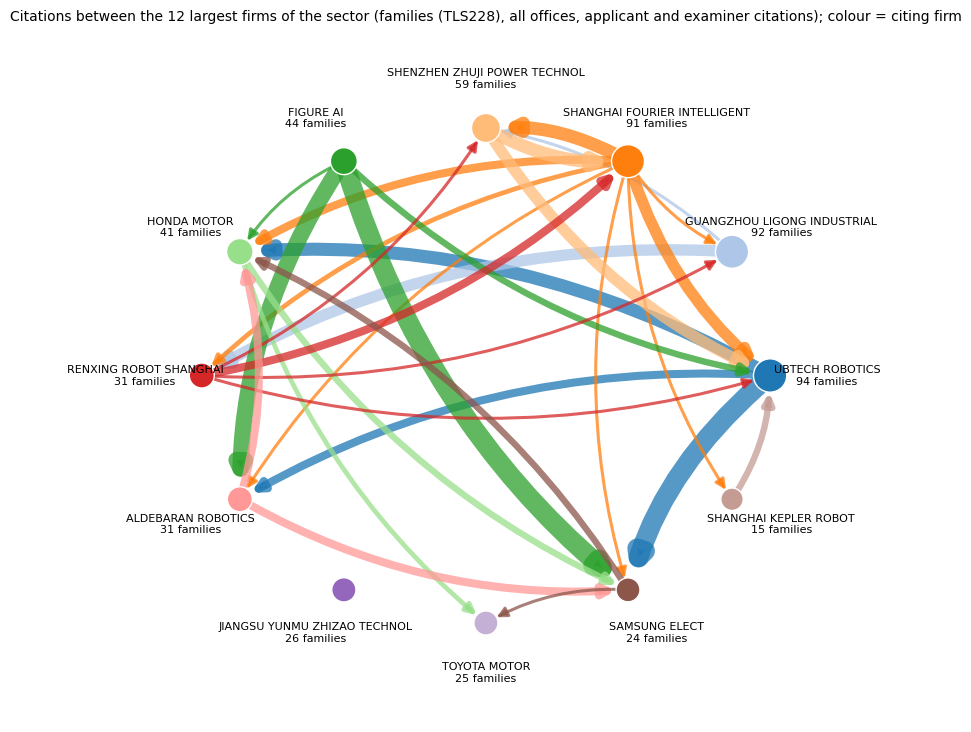

,first year in the sector,cites the others,is cited by the others,cites itself
UBTECH ROBOTICS,2016,22,19,43
GUANGZHOU LIGONG INDUSTRIAL,2024,7,2,29
SHANGHAI FOURIER INTELLIGENT TECHNOLOGY,2023,23,11,61
SHENZHEN ZHUJI POWER TECHNOLOGY,2023,13,9,35
FIGURE AI,2023,24,0,35
HONDA MOTOR,2000,5,19,12
RENXING ROBOT SHANGHAI,2025,7,8,0
ALDEBARAN ROBOTICS,2008,8,14,8
JIANGSU YUNMU ZHIZAO TECHNOLOGY,2023,0,0,1
TOYOTA MOTOR,2002,0,3,1


In [12]:
NET_FIRMS = 12                 # the firms with the most families in the sector (all years): incumbents and entrants
MIN_EDGES = 10                 # fewer applicant citations than this between them: we use the family citations instead
net_firms = firms_only.sort_values("families", ascending=False).head(NET_FIRMS).index.tolist()

def flows_between(edges, origin_label):
    "From family-to-family citations to firm-to-firm citations among net_firms, and the citations a firm makes to itself."
    f = edges.assign(citing=edges["citing_family"].map(main_firm), cited=edges["cited_family"].map(main_firm)).dropna()
    f = f[f["citing"].isin(net_firms) & f["cited"].isin(net_firms)].drop_duplicates(["citing_family", "cited_family"])
    self_cites = f[f["citing"] == f["cited"]].groupby("citing").size()
    flows = f[f["citing"] != f["cited"]].groupby(["citing", "cited"]).size().rename("citations").reset_index()
    return flows, self_cites, origin_label

inside_app = pat[pat["cited_family"].isin(SECTOR_IDS) & (pat["citn_origin"] == "APP")]
flows, self_cites, basis = flows_between(inside_app[["citing_family", "cited_family"]],
                                         "EP publications, citations added by the applicants")
print(f"applicant citations inside the sector: {inside_app[['citing_family', 'cited_family']].drop_duplicates().shape[0]:,}; "
      f"between the {NET_FIRMS} largest firms: {int(flows['citations'].sum()) + int(self_cites.sum())}")
if flows["citations"].sum() + self_cites.sum() < MIN_EDGES:
    family_citations = load_table("family_citations")            # saved by Step 0 v2: citations between families (TLS228)
    inside_fam = family_citations[family_citations["citing"].isin(SECTOR_IDS) & family_citations["cited"].isin(SECTOR_IDS)
                                  & (family_citations["citing"] != family_citations["cited"])]
    flows, self_cites, basis = flows_between(inside_fam.rename(columns={"citing": "citing_family", "cited": "cited_family"}),
                                             "families (TLS228), all offices, applicant and examiner citations")
    print(f"too few: we use the citations between families instead "
          f"({inside_fam[['citing', 'cited']].drop_duplicates().shape[0]:,} pairs of families inside the sector)")

F = nx.DiGraph()
F.add_nodes_from(net_firms)
F.add_weighted_edges_from(flows.itertuples(index=False, name=None))
pos = nx.circular_layout(F)
colour = {firm: plt.cm.tab20(k % 20) for k, firm in enumerate(net_firms)}
sizes = [200 + 4 * firms_only.loc[n, "families"] for n in net_firms]
fig, ax = plt.subplots(figsize=(11, 9))
for u, v, w in F.edges(data="weight"):
    nx.draw_networkx_edges(F, pos, ax=ax, edgelist=[(u, v)], nodelist=net_firms, node_size=sizes, width=1 + 1.2 * w,
                           edge_color=[colour[u]], alpha=0.75, arrowsize=15, connectionstyle="arc3,rad=0.15")
nx.draw_networkx_nodes(F, pos, ax=ax, nodelist=net_firms, node_size=sizes, node_color=[colour[n] for n in net_firms],
                       edgecolors="white")
for n, (x, y) in pos.items():
    ax.text(x * 1.2, y * 1.2, f"{n[:28]}\n{firms_only.loc[n, 'families']} families", ha="center", va="center", fontsize=8)
ax.set_title(f"Citations between the {NET_FIRMS} largest firms of the sector ({basis}); colour = citing firm", fontsize=10)
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.4, 1.4)
ax.axis("off")
plt.show()

balance = pd.DataFrame({
    "cites the others": flows.groupby("citing")["citations"].sum(),
    "is cited by the others": flows.groupby("cited")["citations"].sum(),
    "cites itself": self_cites,
}).reindex(net_firms).fillna(0).astype(int)
balance.insert(0, "first year in the sector", firms_only.loc[net_firms, "first year in the sector"])
balance

**Our reading of the network.** Between the 12 largest firms there are only 4 applicant citations on EP publications, too few for a network, so the picture uses the citations between families (all offices, applicants and examiners together). It shows whose patents are relevant prior art for whom, not who read whom. The pattern is clear: the recent entrants cite the older firms. Figure AI cites the others 24 times and is never cited by them; Shanghai Fourier cites them 23 times (cited 11) and Shenzhen Zhuji 13 times (cited 9). The firms that the others cite are Samsung Electronics (30 citations, while it cites them 4 times), UBTECH and Honda (19 each) and Aldebaran (14). Most firms also cite themselves heavily (Shanghai Fourier 61, UBTECH 43, Figure AI and Shenzhen Zhuji 35 each): they build on their own line of patents.

### 3.3 Who builds on the sector, and how soon?

Now the other direction: the **forward** citations, from any publication of the world to the publications of our families. We keep the citing publications of all the offices for the counts, and the **EP** ones for the origin, as in notebook 40 (Section 5.3). The **category** (X, I, Y, A) is written by the examiner in the search report, so for it we use every office whose search reports are in PATSTAT: the professor insisted in class on blocking patents (X citations) as a strong sign of value, and with the EP reports alone our sector would have almost none. The table is saved for the refinements of Influence (Section 5.5).

For each family of the sector we take the **first** EP publication that cites it and count the days from the first filing of the family, then summarise by priority year: the share of families cited at least once by an EP publication, and the median days to the first citation. The last years can only have been cited quickly, because there has not been time for slow citations yet (truncation): read them with the share.

citations with a category, by citing office: {'CN': 8275, 'WO': 812, 'EP': 296, 'JP': 257, 'US': 144, 'FR': 26}
citations received: 15,916 from 8,408 citing families; families of the sector cited at least once: 1,723 of 2,907
citing offices: {'CN': 8143, 'US': 2589, 'WO': 631, 'JP': 463, 'KR': 294, 'EP': 155}
EP citing publications: 323 (citing family, cited family) pairs; added by the applicant: 11%


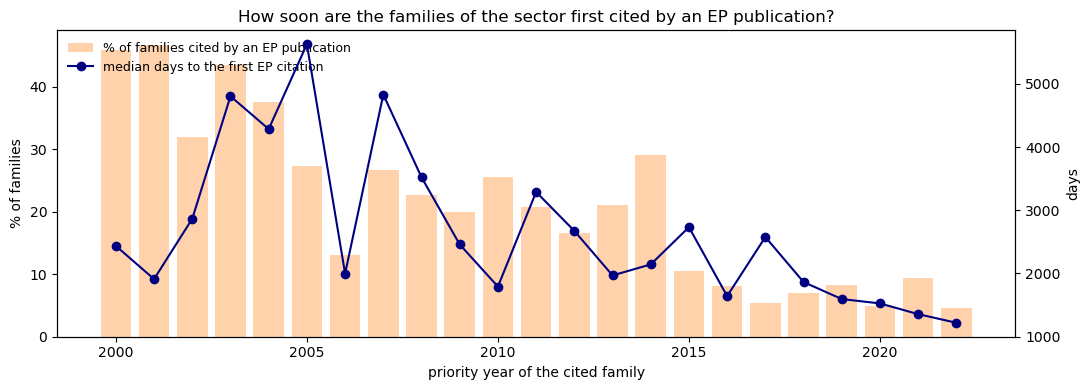

,families,share_cited_by_EP,median_days
priority_year,,,
2005,22,0.27,5626.0
2006,23,0.13,1997.0
2007,30,0.27,4830.0
2008,44,0.23,3521.5
2009,45,0.20,2458.0
2010,47,0.26,1791.5
2011,29,0.21,3288.5
2012,36,0.17,2673.0
2013,38,0.21,1968.0


In [13]:
# 1. the citations received by the publications of the sector, from any publication (TLS212)
fwd = in_chunks(pubs["pat_publn_id"], lambda part: db.query(
    TLS212_CITATION.pat_publn_id.label("citing_publn"), TLS212_CITATION.citn_replenished, TLS212_CITATION.citn_id,
    TLS212_CITATION.citn_origin, TLS212_CITATION.cited_pat_publn_id).filter(TLS212_CITATION.cited_pat_publn_id.in_(part)))
fwd["citn_origin"] = fwd["citn_origin"].astype(str).str.strip()
fwd["cited_family"] = fwd["cited_pat_publn_id"].map(pubs.set_index("pat_publn_id")["docdb_family_id"])

# 2. the citing publications: office, date and family
citing = in_chunks(fwd["citing_publn"], lambda part: db.query(
    TLS211_PAT_PUBLN.pat_publn_id.label("citing_publn"), TLS211_PAT_PUBLN.publn_auth.label("citing_office"),
    TLS211_PAT_PUBLN.publn_date.label("citing_date"), TLS201_APPLN.docdb_family_id.label("citing_family"))
    .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS211_PAT_PUBLN.pat_publn_id.in_(part)))
fwd = fwd.merge(citing, on="citing_publn")
fwd = fwd[fwd["citing_family"] != fwd["cited_family"]]
fwd["who"] = np.where(fwd["citn_origin"] == "APP", "applicant", "examiner or other")
fwd["citing_date"] = pd.to_datetime(fwd["citing_date"], errors="coerce")

# 3. the categories of the citations (TLS215), for the blocking patents of Section 5.5: categories are written in the
#    search reports, so we take them from every office that has them (EPO, PCT international searches, ...), not only EP
fwd_ep = fwd[fwd["citing_office"] == "EP"]
fcat = in_chunks(fwd["citing_publn"], lambda part: db.query(
    TLS215_CITN_CATEG.pat_publn_id.label("citing_publn"), TLS215_CITN_CATEG.citn_replenished, TLS215_CITN_CATEG.citn_id,
    TLS215_CITN_CATEG.citn_categ).filter(TLS215_CITN_CATEG.pat_publn_id.in_(part)))
FKEYS = ["citing_publn", "citn_replenished", "citn_id"]
xi_keys = (fcat[fcat["citn_categ"].astype(str).str.contains("X|I", regex=True)][FKEYS].drop_duplicates()
           if len(fcat) else pd.DataFrame(columns=FKEYS))
fwd["x_or_i"] = fwd.set_index(FKEYS).index.isin(pd.MultiIndex.from_frame(xi_keys)) if len(xi_keys) else False
fwd.to_csv(OUTPUT_DIR / "forward_citations_publications.csv", index=False)      # read again in Section 5.5
categorised = fwd.set_index(FKEYS).index.isin(pd.MultiIndex.from_frame(fcat[FKEYS].drop_duplicates())) if len(fcat) else np.zeros(len(fwd), bool)
print("citations with a category, by citing office:",
      fwd.assign(categorised=categorised).groupby("citing_office")["categorised"].sum().sort_values(ascending=False).head(6).astype(int).to_dict())

cited_fams = fwd["cited_family"].nunique()
print(f"citations received: {len(fwd):,} from {fwd['citing_family'].nunique():,} citing families; "
      f"families of the sector cited at least once: {cited_fams:,} of {len(families):,}")
print("citing offices:", fwd.drop_duplicates(["citing_family", "cited_family"])["citing_office"].value_counts().head(6).to_dict())
ep_pairs = fwd_ep.drop_duplicates(["citing_family", "cited_family", "who"]) if len(fwd_ep) else fwd_ep
print(f"EP citing publications: {len(ep_pairs):,} (citing family, cited family) pairs; "
      f"added by the applicant: {(ep_pairs['who'] == 'applicant').mean():.0%}" if len(ep_pairs) else "no EP citing publication")

# 4. how soon: days from the first filing of the family to the first EP publication that cites it
first_filing = pd.to_datetime(applications["appln_filing_date"], errors="coerce")
first_filing = first_filing.where(first_filing.dt.year < 9000).groupby(applications["docdb_family_id"]).min()
first_cite = fwd[fwd["citing_office"] == "EP"].groupby("cited_family")["citing_date"].min()
lag = families.set_index("docdb_family_id")[["priority_year"]].assign(first_filing=first_filing, first_ep_citation=first_cite)
PLOT_FROM_CITES = 2005                                          # the table starts here: before, a few families per year
lag["days"] = (lag["first_ep_citation"] - lag["first_filing"]).dt.days
lag.loc[lag["days"] < 0, "days"] = np.nan                       # cited before filing: a data error
by_year = lag[lag["priority_year"] <= LAST_COMPLETE_YEAR].groupby("priority_year").agg(
    families=("first_filing", "size"),
    share_cited_by_EP=("first_ep_citation", lambda s: s.notna().mean()),
    median_days=("days", "median"))

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(by_year.index, by_year["share_cited_by_EP"] * 100, color="tab:orange", alpha=0.35, label="% of families cited by an EP publication")
ax1.set_ylabel("% of families")
ax1.set_xlabel("priority year of the cited family")
ax2 = ax1.twinx()
ax2.plot(by_year.index, by_year["median_days"], marker="o", color="navy", label="median days to the first EP citation")
ax2.set_ylabel("days")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9, frameon=False)
ax1.set_title("How soon are the families of the sector first cited by an EP publication?")
plt.tight_layout()
plt.show()
by_year.loc[PLOT_FROM_CITES:].round(2)

**Our reading of who builds on the sector.** The families of the sector received 15,916 citations from 8,408 citing families, and 1,723 of the 2,907 families (59%) are cited at least once. Of the citing pairs, 8,143 come through a Chinese publication, 2,589 through a US one and only 155 through an EP one: the sector is built upon in China and the United States. The few EP citations come mostly from examiners; applicants added 11% of them. EP citations also arrive late: for the families of 2010-2016 the median time from the first filing to the first EP citation is between 1,600 and 3,300 days (4 to 9 years); it is shorter for the later families only because there has not been time for slow citations yet. The share of families cited by an EP publication falls from 13-29% for 2005-2014 to 5-11% for 2015-2022: the recent families have had less time, and they are filed less often in Europe.

**The most cited family of the sector, and who cites it** (notebook 30, Section 8.1). One example makes the counts concrete: the family of the sector cited by the most families in the world, its title, and the technology of the families that cite it (the first three characters of their main CPC class, or IPC when they have no CPC). Many classes mean that the invention is used outside humanoid robots.

In [14]:
cited_by = fwd.groupby("cited_family")["citing_family"].nunique().sort_values(ascending=False)
TOP_CITED = int(cited_by.index[0])
top_apps = applications.loc[applications["docdb_family_id"] == TOP_CITED, "appln_id"].astype(int).tolist()
top_titles = patstat.df(db.query(TLS202_APPLN_TITLE.appln_id, TLS202_APPLN_TITLE.appln_title_lg, TLS202_APPLN_TITLE.appln_title)
                        .filter(TLS202_APPLN_TITLE.appln_id.in_(top_apps)))
english = top_titles[top_titles["appln_title_lg"].astype(str).str.strip() == "en"]
title = (english if len(english) else top_titles)["appln_title"].astype(str).iloc[0] if len(top_titles) else "(no title)"
print(f"family {TOP_CITED} ({main_firm.get(TOP_CITED, 'unknown owner')}, priority {int(year_of_family[TOP_CITED])}): "
      f"cited by {cited_by.iloc[0]} families\n  title: {title}")

# the technology of the citing families: CPC first, IPC for the families without CPC
citers_top = fwd.loc[fwd["cited_family"] == TOP_CITED, "citing_family"].unique().tolist()
cpc_c = patstat.df(db.query(TLS201_APPLN.docdb_family_id, TLS224_APPLN_CPC.cpc_class_symbol)
                   .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
                   .filter(TLS201_APPLN.docdb_family_id.in_(citers_top)))
ipc_c = patstat.df(db.query(TLS201_APPLN.docdb_family_id, TLS209_APPLN_IPC.ipc_class_symbol)
                   .join(TLS209_APPLN_IPC, TLS209_APPLN_IPC.appln_id == TLS201_APPLN.appln_id)
                   .filter(TLS201_APPLN.docdb_family_id.in_(citers_top)))
codes_c = pd.concat([cpc_c.rename(columns={"cpc_class_symbol": "symbol"}).assign(src=0),
                     ipc_c.rename(columns={"ipc_class_symbol": "symbol"}).assign(src=1)])
codes_c["symbol"] = codes_c["symbol"].astype(str).str.replace(" ", "")
codes_c = codes_c[~codes_c["symbol"].str.startswith("Y") & (codes_c["symbol"].str.len() >= 3)]
codes_c = codes_c[codes_c["src"] == codes_c.groupby("docdb_family_id")["src"].transform("min")]      # CPC when the family has it
main_class = codes_c.assign(cls=codes_c["symbol"].str[:3]).groupby("docdb_family_id")["cls"].agg(lambda s: s.value_counts().index[0])
print(f"citing families: {len(citers_top)}, with a class: {len(main_class)}")
main_class.value_counts().rename("citing families").to_frame().head(10)

family 43757332 (GM GLOBAL TECHNOLOGY OPERATIONS, priority 2009): cited by 157 families
  title: Visual perception system and method for a humanoid robot
citing families: 157, with a class: 157


,citing families
cls,
B25,42
A61,27
G06,26
H04,18
G05,16
G16,12
G01,4
A63,4
H05,2


**Our reading of the most cited family.** The most cited family of the sector is not from one of our scored firms: it belongs to GM Global Technology Operations (priority 2009, "Visual perception system and method for a humanoid robot"), from the years of GM's humanoid work with NASA on Robonaut 2. It is cited by 157 families, and they come from many fields: manipulators (B25, 42 families), medical technology (A61, 27), computing (G06, 26), communication (H04, 18), control (G05, 16) and health informatics (G16, 12). A vision system made for a humanoid became prior art for hospitals, computers and networks: humanoid technology travels well beyond robots.

**A network between families** (notebook 30, Section 6). Section 3.2 drew the citations between firms; here each node is one family of the sector and each arrow a citation from a later family of the sector to an earlier one. We use the publication-level citations of Section 3.3, so that every arrow keeps its origin: the applicant's citations are the closest trace of a flow of knowledge, the examiner's say that the cited family is relevant prior art. We draw the largest connected group of families, coloured by owner.

families linked by a citation inside the sector: 1,494; links: 2,750 (9% with an applicant citation); groups: 75; largest group: 1308 families


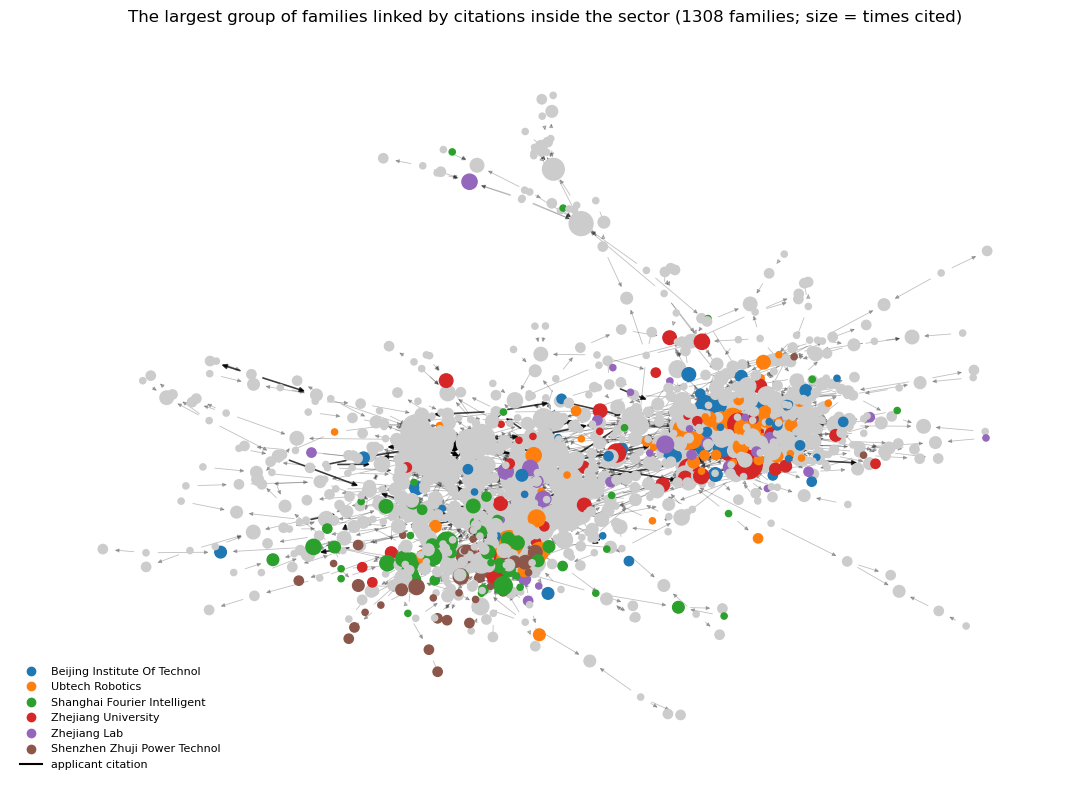

,cited by (families of the group),owner,priority year
55719526,31,GOERTEK,2015
48548074,22,NANJING UNIVERSITY OF POSTS AND TELECOMMUNICATIONS,2013
32464598,19,SAMSUNG ELECT,2002
52405827,18,BEIJING INSTITUTE OF TECHNOLOGY,2014
67058181,17,UBTECH ROBOTICS,2017
43030719,16,GM GLOBAL TECHNOLOGY OPERATIONS,2009
73458982,16,ZHEJIANG UNIVERSITY,2019
43755470,15,GM GLOBAL TECHNOLOGY OPERATIONS,2009


In [15]:
inside_pub = fwd[fwd["citing_family"].isin(SECTOR_IDS) & fwd["cited_family"].isin(SECTOR_IDS)]
edges = inside_pub.groupby(["citing_family", "cited_family"])["who"].agg(lambda s: "applicant" if (s == "applicant").any() else "examiner or other").reset_index()
G = nx.DiGraph()
G.add_edges_from(zip(edges["citing_family"], edges["cited_family"]))
components = sorted(nx.weakly_connected_components(G), key=len, reverse=True) if len(G) else []
print(f"families linked by a citation inside the sector: {G.number_of_nodes():,}; links: {G.number_of_edges():,} "
      f"({(edges['who'] == 'applicant').mean():.0%} with an applicant citation); groups: {len(components)}; "
      f"largest group: {len(components[0]) if components else 0} families")
if components:
    core = G.subgraph(components[0]).copy()
    owners = {n: main_firm.get(n, "other") for n in core}
    top_owners = pd.Series(owners).value_counts().head(6).index.tolist()
    palette = dict(zip(top_owners, plt.cm.tab10.colors))
    pos = nx.spring_layout(core, seed=34, k=0.35)
    fig, ax = plt.subplots(figsize=(11, 8))
    who_of = dict(zip(zip(edges["citing_family"], edges["cited_family"]), edges["who"]))
    app_edges = [(u, v) for u, v in core.edges if who_of.get((u, v)) == "applicant"]
    nx.draw_networkx_edges(core, pos, ax=ax, alpha=0.25, arrowsize=6, width=0.6)
    nx.draw_networkx_edges(core, pos, ax=ax, edgelist=app_edges, edge_color="black", alpha=0.7, arrowsize=7, width=1.2)
    nx.draw_networkx_nodes(core, pos, ax=ax, node_size=[20 + 25 * core.in_degree(n) for n in core],
                           node_color=[palette.get(owners[n], (0.8, 0.8, 0.8)) for n in core])
    handles = [plt.Line2D([0], [0], marker="o", ls="", color=c, label=str(f).title()[:28]) for f, c in palette.items()]
    ax.legend(handles=handles + [plt.Line2D([0], [0], color="black", label="applicant citation")], fontsize=8, frameon=False, loc="lower left")
    ax.set_title(f"The largest group of families linked by citations inside the sector ({core.number_of_nodes()} families; size = times cited)")
    ax.axis("off")
    plt.tight_layout()
    plt.show()
    hubs = pd.Series(dict(core.in_degree())).sort_values(ascending=False).head(8)
    display(pd.DataFrame({"cited by (families of the group)": hubs, "owner": [main_firm.get(n, "") for n in hubs.index],
                          "priority year": [int(year_of_family.get(n, 0)) for n in hubs.index]}))

**Our reading of the network.** Half of the sector's families (1,494 of 2,907) are linked by at least one citation to another family of the sector, and 1,308 of them form one connected group: the sector is one body of prior art, not separate islands. Only 9% of the 2,750 links carry an applicant citation; the rest were added by examiners. The most cited families inside the group are not all from the scored firms: Goertek (2015, cited by 31 families of the group), Nanjing University of Posts and Telecommunications (2013, 22), Samsung (2002, 19), Beijing Institute of Technology (2014, 18), UBTECH (2017, 17), GM (2009, 16 and 15) and Zhejiang University (2019, 16). Chinese universities and an electronics maker sit at the centre next to the incumbents: for Electrolux, part of the knowledge of the sector is in universities that our firm ranking does not score.

### 3.4 How much does the sector rely on science?

Patents also cite **non-patent literature** (TLS214): journal articles, books, standards, web pages. It is our window on the flow of knowledge from science to technology. Humanoid robots join mechanics with control and learning, so we expect more science than in a purely mechanical sector such as the coffee capsules of notebook 30. We count, by priority year of the citing family, the share of the sector's EP applications that cite at least one non-patent document, the share of journal articles among them, and the median **age** of what they cite (priority year of the family minus the year of the cited document; the year comes from `npl_publn_date` or, when it is empty, from the bibliographic string, as in notebook 30).

In [16]:
npl_ids = back.loc[~back["cited_npl_publn_id"].astype(str).str.strip().isin(["", "0", "None", "nan"]), "cited_npl_publn_id"]
npl_ids = npl_ids.astype(str).str.strip().unique().tolist()
npl = pd.concat([patstat.df(db.query(TLS214_NPL_PUBLN.npl_publn_id, TLS214_NPL_PUBLN.npl_type, TLS214_NPL_PUBLN.npl_doi,
                                     TLS214_NPL_PUBLN.npl_publn_date, TLS214_NPL_PUBLN.npl_biblio)
                            .filter(TLS214_NPL_PUBLN.npl_publn_id.in_(npl_ids[s:s + 10_000])))
                 for s in range(0, max(len(npl_ids), 1), 10_000)], ignore_index=True) if npl_ids else pd.DataFrame()
links = back.assign(npl_publn_id=back["cited_npl_publn_id"].astype(str).str.strip())[["citing_family", "citing_appln_id", "npl_publn_id"]]
if len(npl):
    npl["npl_publn_id"] = npl["npl_publn_id"].astype(str).str.strip()
    npl = npl.merge(links.drop_duplicates(), on="npl_publn_id")
    year_field = pd.to_numeric(npl["npl_publn_date"].astype(str).str.strip().str[:4], errors="coerce")
    year_field = year_field.where(year_field.between(1900, 2030))
    year_biblio = pd.to_numeric(npl["npl_biblio"].astype(str).str.extract(r"\((19\d{2}|20\d{2})-\d{2}-\d{2}\)")[0], errors="coerce")
    year_any = pd.to_numeric(npl["npl_biblio"].astype(str).str.extract(r"\b(19\d{2}|20[0-2]\d)\b")[0], errors="coerce")
    npl["npl_year"] = year_field.fillna(year_biblio).fillna(year_any)
    npl = npl.merge(families[["docdb_family_id", "priority_year"]], left_on="citing_family", right_on="docdb_family_id")
    npl["age_years"] = npl["priority_year"] - npl["npl_year"]
    print(f"non-patent citations: {len(npl):,}, made by {npl['citing_appln_id'].nunique():,} of {len(ep_apps):,} EP applications; "
          f"with a DOI: {(npl['npl_doi'].fillna('').astype(str).str.strip() != '').mean():.0%}")
    print("types:", npl["npl_type"].value_counts().to_dict(), "(s = journal article, b = book, w = web, a = abstract)")
    ep_year = ep_apps.merge(families[["docdb_family_id", "priority_year"]], on="docdb_family_id")
    period = pd.cut(ep_year["priority_year"], bins=[YEAR_MIN - 1, 2009, 2016, LAST_COMPLETE_YEAR, YEAR_MAX],
                    labels=["2000-2009", "2010-2016", f"2017-{LAST_COMPLETE_YEAR}", f"{LAST_COMPLETE_YEAR + 1}-{YEAR_MAX}"])
    npl["period"] = pd.cut(npl["priority_year"], bins=[YEAR_MIN - 1, 2009, 2016, LAST_COMPLETE_YEAR, YEAR_MAX],
                           labels=period.cat.categories)
    science = pd.DataFrame({
        "EP applications": ep_year.groupby(period, observed=False)["appln_id"].size(),
        "share citing science (%)": ep_year.groupby(period, observed=False)["appln_id"].apply(lambda s: s.isin(npl["citing_appln_id"]).mean() * 100),
        "non-patent citations": npl.groupby("period", observed=False).size(),
        "journal articles (%)": npl.groupby("period", observed=False)["npl_type"].apply(lambda s: (s == "s").mean() * 100),
        "median age (years)": npl.groupby("period", observed=False)["age_years"].median(),
    })
    display(science.round(1))
else:
    print("no non-patent citation in the EP publications of the sector")

non-patent citations: 134, made by 44 of 83 EP applications; with a DOI: 28%
types: {'s': 99, 'w': 19, 'b': 9, 'j': 6, 'a': 1} (s = journal article, b = book, w = web, a = abstract)


,EP applications,share citing science (%),non-patent citations,journal articles (%),median age (years)
2000-2009,31,61.3,52,73.1,2.0
2010-2016,33,45.5,50,86.0,6.0
2017-2022,14,57.1,25,68.0,4.0
2023-2025,5,40.0,7,14.3,3.0


**Our reading of the science.** Of the 83 EP applications of the sector, 44 cite non-patent literature (134 citations), and 74% of these are journal articles; 28% have a DOI. The sector relies on science far more than the mechanical example of notebook 30, and on recent science: the median age of the cited documents is between 2 and 6 years. The base is small, 83 applications, so we do not read the differences between periods.

## 4. The benchmark for Influence: citations of all of PATSTAT

Influence compares the citations of a family with those of comparable families. Following Hall, Jaffe and Trajtenberg (2001), comparable means the same **CPC subclass** and the same **priority year**: a patent of 2005 has had more time to be cited than one of 2015, and a patent on robot arms is cited more than one on toys. Notebook 40 compares each family with the families of the **same priority year inside the sector**; we compare it with all the families of PATSTAT of the same subclass and year, because our sector is small (one cohort of the sector can have a handful of families) and spread over several subclasses (B25J, B62D, G05D, G05B...). The benchmark of a cohort is the **mean number of citations received within five years** by all the families of PATSTAT in the cohort.

The query counts exactly what Section 2.1 counted in `n_fwd_cites_5y`: the citing families with a first priority year up to the priority year of the cited family plus five, each counted once, a family citing itself excluded. The families of the sector without CPC (old Asian filings, 28% of the sector) take their IPC subclass, which has the same four characters; the benchmark itself is built on the CPC families of PATSTAT.

The query returns one row for each priority year, CPC subclass and **office of first filing**. The office is there for a check: the course says that citations should not be compared across offices, and Chinese applicants hold 65% of the families of the sector (Step 1, Section 9.2). The main benchmark adds up the offices; Section 8 repeats the score with the benchmark of the same office.

The query runs once for each priority year and the result is saved after each year. The first run takes a while; the following ones read the file.

In [17]:
def benchmark_for_year(year, subclasses):
    """All PATSTAT families of one priority year that carry one of our CPC subclasses: how many they are and how many
    citations they received in total from families with a priority year up to year + HORIZON (the same rule as
    n_fwd_cites_5y, Section 2.1). One row per CPC subclass and office of first filing."""
    symbol = func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "")
    subclass = func.substr(symbol, 1, 4).label("subclass")

    # (family, subclass) pairs of the cohort
    fam_sub = (
        db.query(TLS201_APPLN.docdb_family_id.label("family_id"), subclass)
        .select_from(TLS201_APPLN)
        .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
        .filter(REAL_APPLN, TLS201_APPLN.earliest_filing_year == year, func.substr(symbol, 1, 4).in_(subclasses))
        .group_by(TLS201_APPLN.docdb_family_id, subclass)
        .cte("fam_sub")
    )

    # the office of first filing of each family (earliest filing date, WO excluded, as in Step 1)
    ranked = (
        db.query(TLS201_APPLN.docdb_family_id.label("family_id"), TLS201_APPLN.appln_auth.label("office"),
                 func.row_number().over(partition_by=TLS201_APPLN.docdb_family_id,
                                        order_by=[TLS201_APPLN.appln_filing_date, TLS201_APPLN.appln_id]).label("position"))
        .filter(REAL_APPLN, TLS201_APPLN.earliest_filing_year == year, TLS201_APPLN.appln_auth != "WO")
        .subquery("ranked")
    )
    first_office = db.query(ranked.c.family_id, ranked.c.office).filter(ranked.c.position == 1).cte("first_office")

    # citations received: citing families with a priority year up to year + HORIZON, each counted once, self-citations out
    cites = (
        db.query(TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.label("family_id"),
                 func.count(distinct(TLS228_DOCDB_FAM_CITN.docdb_family_id)).label("n_cites"))
        .select_from(TLS228_DOCDB_FAM_CITN)
        .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == TLS228_DOCDB_FAM_CITN.docdb_family_id)
        .filter(REAL_APPLN, TLS201_APPLN.earliest_filing_year <= year + HORIZON,
                TLS228_DOCDB_FAM_CITN.docdb_family_id != TLS228_DOCDB_FAM_CITN.cited_docdb_family_id,
                TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.in_(db.query(fam_sub.c.family_id).subquery().select()))
        .group_by(TLS228_DOCDB_FAM_CITN.cited_docdb_family_id)
        .cte("cites")
    )

    q = (
        db.query(fam_sub.c.subclass, first_office.c.office, func.count().label("n_families"),
                 func.sum(func.coalesce(cites.c.n_cites, 0)).label("n_cites"))
        .select_from(fam_sub)
        .outerjoin(first_office, first_office.c.family_id == fam_sub.c.family_id)
        .outerjoin(cites, cites.c.family_id == fam_sub.c.family_id)
        .group_by(fam_sub.c.subclass, first_office.c.office)
    )
    out = patstat.df(q)
    if out.empty:                                             # a query without rows comes back without columns
        return pd.DataFrame(columns=["year", "subclass", "office", "n_families", "n_cites"])
    out.insert(0, "year", year)
    return out

In [18]:
# the CPC subclasses that we need: the main subclass of every family of the sector that is old enough for Influence
main_subclass = families.loc[families["priority_year"] <= INFLUENCE_LAST_YEAR, "main_cpc_subclass"]
SUBCLASSES = sorted(main_subclass[main_subclass != ""].unique())

signature = hashlib.md5((",".join(SUBCLASSES) + f"|{HORIZON}|{YEAR_MIN}|noself").encode()).hexdigest()[:8]   # a new list never reuses an old file
BENCH_FILE = OUTPUT_DIR / f"benchmark_citations_{signature}.csv"          # saved year by year, so that the long query runs only once

done = set(pd.read_csv(BENCH_FILE)["year"]) if BENCH_FILE.exists() else set()
print(f"{len(SUBCLASSES)} CPC subclasses; priority years {YEAR_MIN}-{INFLUENCE_LAST_YEAR}; already in the file: {len(done)} years")
for year in range(YEAR_MIN, INFLUENCE_LAST_YEAR + 1):
    if year in done:
        continue
    start = time.time()
    part = benchmark_for_year(year, SUBCLASSES)
    part.to_csv(BENCH_FILE, mode="a", header=not BENCH_FILE.exists(), index=False)
    print(f"{year}: {part['n_families'].sum():,} family-subclass pairs in {len(part):,} rows, {time.time() - start:.0f} s")

50 CPC subclasses; priority years 2000-2017; already in the file: 18 years


In [19]:
bench = pd.read_csv(BENCH_FILE).fillna({"office": ""})
cohort = bench.groupby(["year", "subclass"], as_index=False)[["n_families", "n_cites"]].sum()
cohort["benchmark"] = cohort["n_cites"] / cohort["n_families"]                  # mean citations received within HORIZON years
cohort["valid"] = cohort["n_families"] >= MIN_COHORT
print(f"{len(cohort):,} cohorts (CPC subclass x priority year), {cohort['valid'].mean():.0%} with at least {MIN_COHORT} families")

# Check 1: the sector is part of PATSTAT, so in no cohort can the sector have more families or more citations than the benchmark
sector_fc = (families.loc[families["fwd5_complete"], ["docdb_family_id", "priority_year", "n_fwd_cites_5y"]]
             .merge(family_cpc.loc[~family_cpc["is_tagging"], ["docdb_family_id", "subclass"]].drop_duplicates(), on="docdb_family_id"))
sector_cells = (sector_fc.groupby(["priority_year", "subclass"])
                .agg(sector_families=("docdb_family_id", "nunique"), sector_cites=("n_fwd_cites_5y", "sum")).reset_index()
                .rename(columns={"priority_year": "year"}))
compare = sector_cells.merge(cohort, on=["year", "subclass"], how="inner")
too_many = compare[(compare["sector_families"] > compare["n_families"]) | (compare["sector_cites"] > compare["n_cites"])]
print(f"Check 1: {len(compare):,} cohorts where the sector has families; cohorts where the sector exceeds the benchmark: "
      f"{len(too_many)} (must be 0)")

# Check 2: the benchmark of the largest subclasses of the sector (mean citations within five years, every fourth year)
top_subclasses = main_subclass.value_counts().head(4).index
years_shown = [y for y in range(YEAR_MIN, INFLUENCE_LAST_YEAR + 1) if (INFLUENCE_LAST_YEAR - y) % 4 == 0]
cohort[cohort["subclass"].isin(top_subclasses) & cohort["year"].isin(years_shown)].pivot(index="year", columns="subclass", values="benchmark").round(2)

900 cohorts (CPC subclass x priority year), 99% with at least 30 families
Check 1: 172 cohorts where the sector has families; cohorts where the sector exceeds the benchmark: 0 (must be 0)


subclass,A63H,B25J,B62D,G05B
year,,,,
2001,2.60,6.49,3.86,8.95
2005,2.20,6.17,3.01,6.86
2009,2.57,6.39,3.84,10.35
2013,3.80,11.81,5.77,9.90
2017,2.41,7.82,4.73,6.87


**Our reading of the benchmark.** The query found 900 cohorts (50 CPC subclasses x 18 priority years), 99% with at least 30 families, and the sector never exceeds its cohort (Check 1). The benchmark differs a lot between fields: in 2013 a B25J family (manipulators) received on average 11.8 citations within five years, a B62D family (vehicles, including legged robots) 5.8 and an A63H family (toys) 3.8. Comparing each family only with its own subclass and year is what makes a firm of toys and a firm of manipulators comparable.

## 5. The four indicators (Tutorial 4, notebook 40, Sections 4 to 7)

The firms are the 8 of Section 2.3. For each of them we compute the four indicators of notebook 40, Volume, Influence, Success and Globalization, each first in its **basic** form and then with the **refinements** that fit our sector. Every table keeps the number of families, or applications, behind each value, because an average of three families says little about a firm.

### 5.1 When can each indicator be measured?

An indicator can be measured on a family only when the event that it counts has had time to happen. The limit is different for each indicator, and it is not a cut of the data:

- **Influence** counts the citations received within five years: it needs five complete years after the priority year, so the priority year must be at most the last complete year minus five (2017, the same limit as `fwd5_complete`, Section 2.1);
- **Success** needs applications old enough to have been decided. The offices take between two and four years, so we stop at the filing years up to the last complete year minus two (2020) and check it on the share granted by filing year (third panel): a curve that bends down before the grey area would say that the limit is too late;
- **Globalization** needs the time to enter the national phases (30 to 31 months after the priority year for a PCT application) and for the filings to be published (18 months): we use the priority years up to the last complete year minus one (2021). The second panel, the share of families filed in two or more offices, is a check and not a proof, because it also moves when the filers of the sector change;
- **Volume** only counts families, so it uses every year, the provisional 2023-2025 included: the sector files more families in 2024 and 2025 than in any earlier year even if those years are still incomplete (Step 1).

The families of the last years do not disappear: Step 4 scores them with forward-looking signals.

Two kinds of applications are not counted as national filings, as in notebook 40 (Section 6.2): `WO`, because a PCT application is a request and not protection in a country, and the applications of kind **`T`**, the translations of a granted EP patent that some offices record as national applications (they are the EP patent validated there, not a second examination).

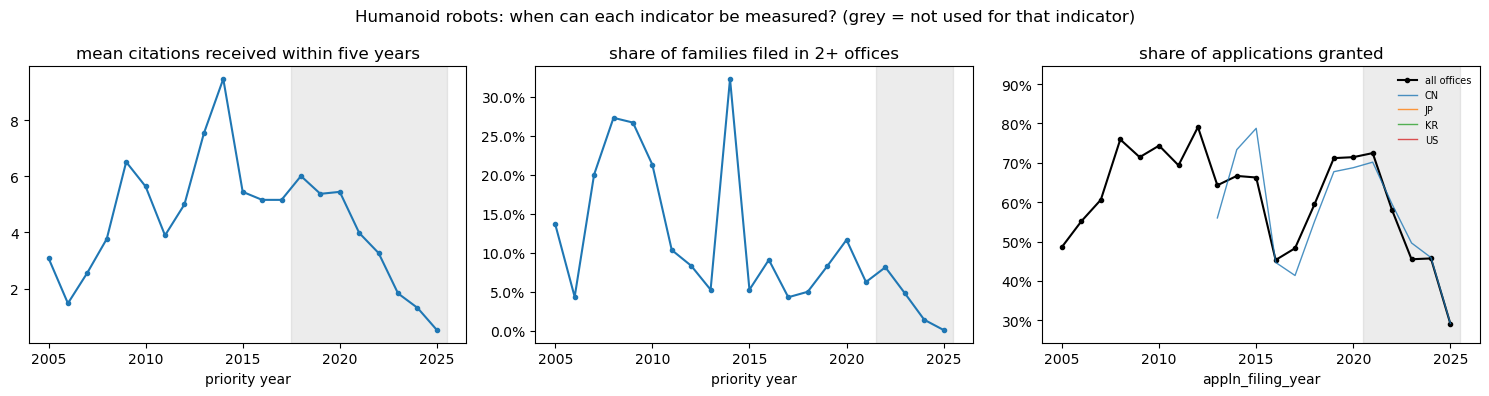

,families,citations_5y,abroad,applications,share_granted
2013,38.0,7.53,0.05,42,0.64
2014,62.0,9.47,0.32,81,0.67
2015,76.0,5.45,0.05,249,0.66
2016,99.0,5.16,0.09,128,0.45
2017,93.0,5.16,0.04,118,0.48
2018,100.0,6.01,0.05,106,0.59
2019,109.0,5.38,0.08,118,0.71
2020,103.0,5.45,0.12,126,0.71
2021,128.0,3.98,0.06,138,0.72
2022,86.0,3.27,0.08,107,0.58


In [20]:
PLOT_FROM = 2005                                      # before this year the sector is too small for a curve to mean anything

# national applications: no PCT requests (WO) and no translations of EP patents (kind T), as in notebook 40
national = applications[(applications["appln_auth"] != "WO") & (applications["appln_kind"].astype(str).str.strip() != "T")].copy()
national["is_granted"] = national["granted"].eq("Y")
families["offices"] = families["docdb_family_id"].map(national.groupby("docdb_family_id")["appln_auth"].nunique()).fillna(1)

by_prio = families.groupby("priority_year").agg(families=("docdb_family_id", "nunique"), citations_5y=("n_fwd_cites_5y", "mean"),
                                                abroad=("offices", lambda s: (s >= 2).mean()))
by_filing = national.groupby("appln_filing_year").agg(applications=("appln_id", "nunique"), share_granted=("is_granted", "mean"))
maturity = by_prio.join(by_filing, how="outer").loc[PLOT_FROM:YEAR_MAX]

# the same share granted, office by office: the offices decide at different speeds; a cell with fewer than 20 applications is not drawn
main_offices = national["appln_auth"].value_counts().index[:4]
by_office = (national[national["appln_auth"].isin(main_offices)].groupby(["appln_filing_year", "appln_auth"])["is_granted"]
             .agg(n="size", share="mean"))
by_office = by_office["share"].where(by_office["n"] >= 20).unstack().loc[PLOT_FROM:YEAR_MAX]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
panels = [("citations_5y", "mean citations received within five years", "priority year", INFLUENCE_LAST_YEAR),
          ("abroad", "share of families filed in 2+ offices", "priority year", GLOBALIZATION_LAST_YEAR),
          ("share_granted", "share of applications granted", "filing year", SUCCESS_LAST_YEAR)]
for ax, (column, title, xlabel, last_year) in zip(axes, panels):
    maturity[column].plot(ax=ax, marker="o", ms=3, color="black" if column == "share_granted" else "tab:blue", label="all offices")
    ax.axvspan(last_year + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15)          # years that we do not use for this indicator
    ax.set(title=title, xlabel=xlabel)
by_office.plot(ax=axes[2], lw=1, alpha=0.8)
axes[2].legend(fontsize=7, frameon=False)
for ax in axes[1:]:
    ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle(f"{SECTOR_NAME}: when can each indicator be measured? (grey = not used for that indicator)")
plt.tight_layout()
plt.show()

maturity.loc[LAST_COMPLETE_YEAR - 9:].round(2)

**Our reading of the limits.** The data support the three limits. The share of applications granted stays between 59% and 72% for the filing years 2018-2021, then falls to 58% in 2022 and 46% in 2023, when many filings are still pending: stopping Success at 2020 leaves one year of margin. The share of families filed in two or more offices shows no clear drop before 2024 (5% in 2023, 1% in 2024), so the limit of Globalization at 2021 is prudent. The mean citations within five years drop from 2021 on (4.0, then 3.3), but they are incomplete already from 2018, since a family of 2018 has had only four complete years by 2022: this is why Influence stops at 2017. Volume uses every year, so it is the only indicator that sees the surge of 2024-2025 (493 and 967 families).

### 5.2 Volume

**Volume** is the number of families of the firm divided by all the families of the sector (Ernst, 1998; notebook 40, Section 4.1). The denominator is all the families of the sector, those of universities, individuals and small firms included: Volume is a share of the whole sector. A family that two firms file together counts fully for each of them, as in Step 2, so the volumes do not add up to 100%.

**Refinement (notebook 40, Section 4.2): who gains and who loses?** One share over 26 years hides the timing. We split the window at 2015, the year of Step 2 that separates incumbents and entrants, and compute the share before and from 2015 on: the change, in percentage points, says whether the firm is gaining or losing weight in the sector.

In [21]:
# one row per family and scored firm: a family with two names of the same firm counts once
firm_fam = fam_firm[fam_firm["firm"].isin(SELECTED)].drop_duplicates(["docdb_family_id", "firm"])[["docdb_family_id", "firm", "priority_year"]]

sector_total = families["docdb_family_id"].nunique()
sector_before = int((families["priority_year"] < SPLIT_YEAR).sum())
sector_since = int((families["priority_year"] >= SPLIT_YEAR).sum())
indicators = pd.DataFrame(index=SELECTED)                          # the table that collects the indicators of the firms
indicators["families"] = firm_fam.groupby("firm")["docdb_family_id"].nunique()
indicators["Volume (%)"] = indicators["families"] / sector_total * 100
before_n = firm_fam[firm_fam["priority_year"] < SPLIT_YEAR].groupby("firm")["docdb_family_id"].nunique().reindex(SELECTED).fillna(0)
since_n = firm_fam[firm_fam["priority_year"] >= SPLIT_YEAR].groupby("firm")["docdb_family_id"].nunique().reindex(SELECTED).fillna(0)
indicators[f"Volume before {SPLIT_YEAR} (%)"] = before_n / sector_before * 100
indicators[f"Volume since {SPLIT_YEAR} (%)"] = since_n / sector_since * 100
indicators["change (points)"] = indicators[f"Volume since {SPLIT_YEAR} (%)"] - indicators[f"Volume before {SPLIT_YEAR} (%)"]

print(f"Sector: {sector_total:,} families in {YEAR_MIN}-{YEAR_MAX}: {sector_before:,} before {SPLIT_YEAR}, {sector_since:,} from {SPLIT_YEAR} on")
indicators[["families", "Volume (%)", f"Volume before {SPLIT_YEAR} (%)", f"Volume since {SPLIT_YEAR} (%)", "change (points)"]].round(2)

Sector: 2,907 families in 2000-2025: 487 before 2015, 2,420 from 2015 on


,families,Volume (%),Volume before 2015 (%),Volume since 2015 (%),change (points)
UBTECH ROBOTICS,94,3.23,0.00,3.88,3.88
HONDA MOTOR,41,1.41,8.21,0.04,-8.17
ALDEBARAN ROBOTICS,31,1.07,4.93,0.29,-4.64
TOYOTA MOTOR,25,0.86,4.93,0.04,-4.89
SAMSUNG ELECT,24,0.83,4.52,0.08,-4.43
KAWADA KOGYO,13,0.45,2.26,0.08,-2.18
TMSUK,13,0.45,2.67,0.00,-2.67
LEJU SHENZHEN ROBOT TECHNOLOGY,14,0.48,0.00,0.58,0.58


**Our reading of Volume.** The sector is fragmented: the largest scored firm, UBTECH, holds 3.2% of all families, Honda 1.4%, Aldebaran 1.1%, the others less than 1%. The split at 2015 shows a complete change of generation. Before 2015 Honda held 8.2% of the families, Aldebaran and Toyota 4.9% each, Samsung 4.5%; from 2015 on they hold between 0.04% and 0.3%. UBTECH and Leju had no family before 2015 and hold 3.9% and 0.6% of the 2,420 families since then. The incumbents did not lose share to one another: they almost stopped filing humanoid patents while the sector filed five times as many families from 2015 as in the fifteen years before.

**Refinement (notebook 40, Section 4.2): shares year by year.** One split at 2015 hides when the change of generation happened. We follow the share of the sector's families of the four largest scored firms and of the three largest firms that we cannot score yet, year by year, smoothed with a three-year moving average (one year is often a handful of families). The years after 2022 are incomplete (grey): a share suffers less than a count, but read them with care.

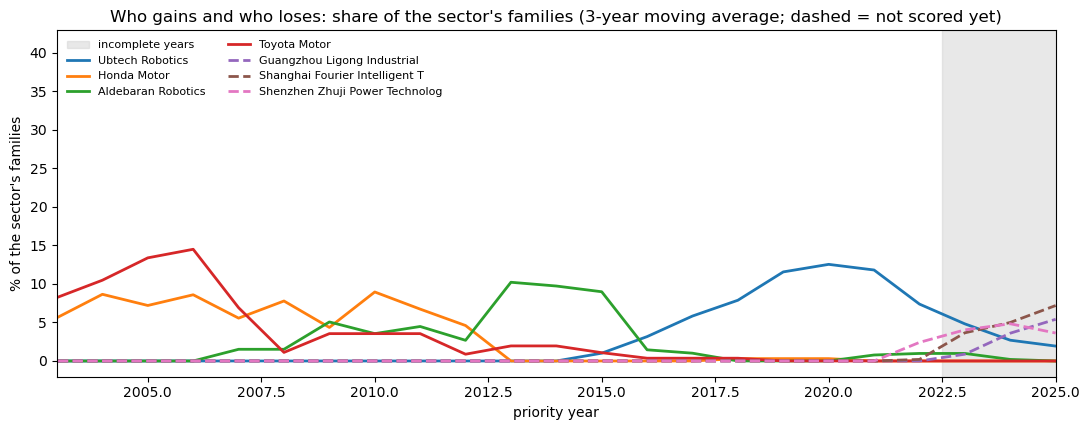

,2000-2009,2010-2016,2017-2022,2023-2025
firm,,,,
UBTECH ROBOTICS,0.0,0.8,10.0,1.8
HONDA MOTOR,12.0,1.8,0.2,0.0
ALDEBARAN ROBOTICS,0.7,6.7,0.3,0.1
TOYOTA MOTOR,5.8,2.1,0.2,0.0
GUANGZHOU LIGONG INDUSTRIAL,0.0,0.0,0.0,5.7
SHANGHAI FOURIER INTELLIGENT TECHNOLOGY,0.0,0.0,0.0,5.6
SHENZHEN ZHUJI POWER TECHNOLOGY,0.0,0.0,0.0,3.6


In [22]:
TOP_YEARLY = SELECTED[:4] + [f for f in recent.index[:3] if f not in SELECTED]
yearly = (fam_firm[fam_firm["firm"].isin(TOP_YEARLY)].drop_duplicates(["docdb_family_id", "firm"])
          .groupby(["priority_year", "firm"])["docdb_family_id"].nunique().unstack(fill_value=0))
total_year = families.groupby("priority_year")["docdb_family_id"].nunique()
share_year = yearly.reindex(index=total_year.index, columns=TOP_YEARLY, fill_value=0).div(total_year, axis=0) * 100
smooth = share_year.rolling(3, center=True, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="lightgrey", alpha=0.5, label="incomplete years")
for k, f in enumerate(TOP_YEARLY):
    ax.plot(smooth.index, smooth[f], lw=2, ls="-" if f in SELECTED else "--", color=plt.cm.tab10(k), label=f.title()[:30])
ax.set(xlabel="priority year", ylabel="% of the sector's families", xlim=(2003, YEAR_MAX),             # before 2003 a year has a handful of families and the shares jump
       title="Who gains and who loses: share of the sector's families (3-year moving average; dashed = not scored yet)")
ax.legend(fontsize=8, frameon=False, ncol=2)
plt.tight_layout()
plt.show()

PERIODS = [(2000, 2009), (2010, 2016), (2017, LAST_COMPLETE_YEAR), (LAST_COMPLETE_YEAR + 1, YEAR_MAX)]
per_period = pd.DataFrame({f"{a}-{b}": yearly.reindex(columns=TOP_YEARLY, fill_value=0).loc[a:b].sum() / total_year.loc[a:b].sum() * 100
                           for a, b in PERIODS})
per_period.round(1)

**Our reading of the shares year by year.** The sector has had three generations of leaders, and a fourth is arriving. Honda held 12.0% of the families in 2000-2009, then 1.8% and 0.2%; Toyota went from 5.8% to 0.2%. Aldebaran had its years in 2010-2016 (6.7%, the time of NAO and Pepper), then 0.3%. UBTECH took over in 2017-2022 (10.0%). In the incomplete years 2023-2025 its share falls to 1.8%, while three Chinese firms with no family before 2023 hold 5.7% (Guangzhou Ligong), 5.6% (Shanghai Fourier) and 3.6% (Shenzhen Zhuji Power). The present score measures the third generation; the fourth is the work of Step 4.

### 5.3 Success

**Success** asks whether the examiners accept the firm's inventions (Guellec and van Pottelsberghe de la Potterie, 2000). In class the professor gave two measures. The simplest is the share of the firm's applications granted at one office, for example the EPO (notebook 40, Section 6.1); the better one is the share granted **inside the family**, over all its offices (notebook 40, Section 6.2), because a grant at one office does not guarantee a grant at another (similar but different patentability rules, local markets, and lawyers who know one office better than the others). The single-office measure fits a firm that works in one market only. Our firms file in several markets, and our sector has 83 EP applications in all (Section 3.1), so the EPO alone is not an option: the cell shows the EP count of each firm anyway, to make this visible.

- **Success** (our main measure, the professor's better one): for each family, the share of its national applications filed up to the limit of Section 5.1 that were granted; for the firm, the mean over its families. An invention granted in China, Japan and the US has passed three examinations.
- **Success by application** (a check): the share of all the firm's national applications that were granted. Offices grant at very different rates, so next to it we compute what the firm would obtain if each of its applications had the average fate of the sector at the same office, and take the ratio (**Success vs same offices**: 1 means as the sector). Section 8 uses it as a variant.

The basic measure of notebook 40 (Section 6.1), the share of the firm's EP applications granted, is in the table too (**EP granted**), but it rests on 3 to 24 applications per firm.

`granted` is a flag of PATSTAT: an application that is not granted can be refused, withdrawn or still pending, and the flag does not say which. The next cell finds out with the legal events.

In [23]:
old_enough = national[national["appln_filing_year"] <= SUCCESS_LAST_YEAR].copy()
print(f"{len(national):,} national applications of the sector; {len(old_enough):,} were filed up to {SUCCESS_LAST_YEAR}")

# offices grant at very different rates: this is what the sector gets at each of them
office_table = (old_enough.groupby("appln_auth").agg(applications=("is_granted", "size"), share_granted=("is_granted", "mean"))
                .sort_values("applications", ascending=False))
display(office_table.head(8).round(2))

office_rate = old_enough.groupby("appln_auth")["is_granted"].mean()
old_enough["expected"] = old_enough["appln_auth"].map(office_rate)
firm_apps = old_enough.merge(firm_fam[["docdb_family_id", "firm"]], on="docdb_family_id")     # an application of a co-owned family counts for each firm
g = firm_apps.groupby("firm")
success = pd.DataFrame({
    "applications (old enough)": g.size(),
    "granted": g["is_granted"].sum(),
    "Success by application (%)": g["is_granted"].mean() * 100,
    "expected at the same offices (%)": g["expected"].mean() * 100,
    "EP applications": firm_apps[firm_apps["appln_auth"] == "EP"].groupby("firm").size(),
    "EP granted (%)": firm_apps[firm_apps["appln_auth"] == "EP"].groupby("firm")["is_granted"].mean() * 100,      # notebook 40, 6.1
}).reindex(SELECTED)
success["Success vs same offices"] = success["Success by application (%)"] / success["expected at the same offices (%)"].replace(0, np.nan)
success["EP applications"] = success["EP applications"].fillna(0).astype(int)

# the main measure (notebook 40, 6.2): success of each invention across its offices, then the mean over the firm's families
family_success = old_enough.groupby("docdb_family_id")["is_granted"].mean().rename("family_success")
fs = firm_fam.merge(family_success, left_on="docdb_family_id", right_index=True)
success["families (old enough)"] = fs.groupby("firm").size().reindex(SELECTED)
success["Success (%)"] = fs.groupby("firm")["family_success"].mean().reindex(SELECTED) * 100
success.loc[success["applications (old enough)"].fillna(0) < MIN_MATURE,
            ["Success (%)", "Success by application (%)", "Success vs same offices"]] = np.nan
SECTOR_SUCCESS = family_success.mean() * 100               # the sector average, for the figures (Section 10)
print(f"sector: {SECTOR_SUCCESS:.1f}% of the national applications of a family granted, on average over {len(family_success):,} families")

indicators = indicators.drop(columns=[c for c in success.columns if c in indicators.columns]).join(success)
indicators["applications (old enough)"] = indicators["applications (old enough)"].fillna(0).astype(int)
indicators[["families (old enough)", "Success (%)", "applications (old enough)", "EP applications", "EP granted (%)", "granted",
            "Success by application (%)", "expected at the same offices (%)", "Success vs same offices"]].round(2)

3,494 national applications of the sector; 1,566 were filed up to 2020


,applications,share_granted
appln_auth,,
CN,702,0.62
JP,250,0.55
KR,163,0.80
US,162,0.85
EP,66,0.73
AU,30,0.70
FR,26,0.77
CA,25,0.88


sector: 60.1% of the national applications of a family granted, on average over 1,056 families


,families (old enough),Success (%),applications (old enough),EP applications,EP granted (%),granted,Success by application (%),expected at the same offices (%),Success vs same offices
UBTECH ROBOTICS,43,87.21,60,0,NaN,54,90.00,68.65,1.31
HONDA MOTOR,41,79.70,100,11,90.91,83,83.00,70.39,1.18
ALDEBARAN ROBOTICS,28,63.39,266,24,79.17,167,62.78,55.45,1.13
TOYOTA MOTOR,25,64.00,29,0,NaN,20,68.97,57.32,1.20
SAMSUNG ELECT,22,72.35,58,4,75.00,42,72.41,75.79,0.96
KAWADA KOGYO,13,61.54,13,0,NaN,8,61.54,54.80,1.12
TMSUK,13,10.26,20,3,0.00,2,10.00,62.97,0.16
LEJU SHENZHEN ROBOT TECHNOLOGY,2,NaN,2,0,NaN,1,NaN,61.54,NaN


**Our reading of Success.** Invention by invention, UBTECH has the highest success: on average 87% of the national applications of its families filed up to 2020 were granted. Honda follows (80%), then Samsung (72%), Toyota (64%), Aldebaran (63%) and Kawada (62%); Tmsuk is the outlier at 10% (2 of its 20 applications granted; the flag does not say whether the others were refused or abandoned). Leju has 2 applications old enough, too few for a rate. Counting applications instead of families gives the same order (UBTECH 90%, Honda 83%, Samsung 72%, Toyota 69%, Aldebaran 63%, Kawada 62%). The offices grant very differently: in our sector 85% of the US applications and 80% of the Korean ones were granted, against 62% of the Chinese and 55% of the Japanese. Against the offices where they file, UBTECH stays first (1.31 times the sector), followed by Toyota (1.20), Honda (1.18), Aldebaran (1.13) and Kawada (1.12); Samsung is at the level of the sector (0.96). The EP column shows why the single-office measure cannot be used here: only Aldebaran (24 EP applications), Honda (11), Samsung (4) and Tmsuk (3) have any.

**Refinement: refused, withdrawn or still pending?** An application that is not granted is either **decided** (refused, withdrawn or deemed withdrawn) or **still pending**, and a pending application is not a failure. The legal events of INPADOC (TLS231) say which: each event code belongs to a category of the WIPO standard ST.27 (TLS803), and one of them is the discontinuation of the application. An application not granted counts as **refused or withdrawn** if it has an event in such a category, otherwise as **pending or unknown** (some offices report few events). **Success, decided only** repeats the main measure on the decided applications alone: granted / (granted + refused or withdrawn), family by family.

In [24]:
try:
    from epo.tipdata.patstat.database.models import TLS803_LEGAL_EVENT_CODE    # the reference table of the event codes
except ImportError:
    TLS803_LEGAL_EVENT_CODE = None
DISCONTINUED = r"DISCONTINU|WITHDRAW|REFUS|REJECT|ABANDON"                   # words of the ST.27 categories of a stopped application
not_granted = old_enough.loc[~old_enough["is_granted"].astype(bool), "appln_id"].astype(int).tolist()
if TLS803_LEGAL_EVENT_CODE is not None and not_granted:
    status_events = in_chunks(not_granted, lambda part: db.query(
        TLS231_INPADOC_LEGAL_EVENT.appln_id, TLS803_LEGAL_EVENT_CODE.event_category_code, TLS803_LEGAL_EVENT_CODE.event_category_title)
        .join(TLS803_LEGAL_EVENT_CODE, and_(TLS803_LEGAL_EVENT_CODE.event_auth == TLS231_INPADOC_LEGAL_EVENT.event_auth,
                                            TLS803_LEGAL_EVENT_CODE.event_code == TLS231_INPADOC_LEGAL_EVENT.event_code))
        .filter(TLS231_INPADOC_LEGAL_EVENT.appln_id.in_(part)).distinct())
else:
    status_events = pd.DataFrame(columns=["appln_id", "event_category_code", "event_category_title"])
    print("TLS803 not available: every application not granted stays 'pending or unknown'")
status_events["title"] = status_events["event_category_title"].fillna("").astype(str).str.strip().str.upper()
print("event categories of the applications not granted (applications with at least one event of the category):")
display(status_events.drop_duplicates(["appln_id", "title"])["title"].value_counts().head(12).to_frame("applications"))

stopped = set(status_events.loc[status_events["title"].str.contains(DISCONTINUED, regex=True), "appln_id"].astype(int))
old_enough["status"] = np.where(old_enough["is_granted"].astype(bool), "granted",
                                np.where(old_enough["appln_id"].astype(int).isin(stopped), "refused or withdrawn", "pending or unknown"))
print("status of the applications filed up to", SUCCESS_LAST_YEAR, "by office (%):")
display((pd.crosstab(old_enough["appln_auth"].values, old_enough["status"].values, rownames=["office"], colnames=["status"],
                     normalize="index") * 100).round(1)
        .reindex(office_table.head(6).index))

decided = old_enough[old_enough["status"] != "pending or unknown"]
family_decided = decided.groupby("docdb_family_id")["is_granted"].mean().rename("s")
fsd = firm_fam.merge(family_decided, left_on="docdb_family_id", right_index=True)
firm_status = old_enough.merge(firm_fam[["docdb_family_id", "firm"]], on="docdb_family_id")
n_decided = decided.merge(firm_fam[["docdb_family_id", "firm"]], on="docdb_family_id").groupby("firm").size().reindex(SELECTED).fillna(0)
status_table = pd.DataFrame({
    "decided applications": n_decided.astype(int),
    "pending or unknown (%)": firm_status.groupby("firm")["status"].apply(lambda s: (s == "pending or unknown").mean() * 100).reindex(SELECTED),
    "Success, decided only (%)": (fsd.groupby("firm")["s"].mean() * 100).reindex(SELECTED).where(n_decided >= MIN_MATURE),
})
indicators = indicators.drop(columns=[c for c in status_table.columns if c in indicators.columns]).join(status_table)
print(f"sector: {(old_enough['status'] == 'pending or unknown').mean():.0%} of the applications filed up to {SUCCESS_LAST_YEAR} "
      f"are still pending or have no event; success on the decided ones {family_decided.mean() * 100:.1f}% (families)")
indicators[["Success (%)", "Success, decided only (%)", "decided applications", "pending or unknown (%)"]].round(1)

event categories of the applications not granted (applications with at least one event of the category):


,applications
title,
APPLICATION DISCONTINUATION,373
SEARCH AND EXAMINATION,364
DOCUMENT PUBLICATION,288
PARTY DATA CHANGE,48
RE-PUBLICATION OF DOCUMENT AFTER MODIFICATION,36
IP RIGHT CESSATION,34
OTHER,25
CLASSIFICATION PENDING,24
ADMINISTRATIVE PROCEDURE ADJUSTMENT,20


status of the applications filed up to 2020 by office (%):


status,granted,pending or unknown,refused or withdrawn
appln_auth,,,
CN,61.5,1.1,37.3
JP,54.8,40.8,4.4
KR,80.4,0.0,19.6
US,84.6,0.0,15.4
EP,72.7,0.0,27.3
AU,70.0,20.0,10.0


sector: 12% of the applications filed up to 2020 are still pending or have no event; success on the decided ones 67.2% (families)


,Success (%),"Success, decided only (%)",decided applications,pending or unknown (%)
UBTECH ROBOTICS,87.2,87.2,60,0.0
HONDA MOTOR,79.7,95.8,85,15.0
ALDEBARAN ROBOTICS,63.4,84.6,200,24.8
TOYOTA MOTOR,64.0,88.9,22,24.1
SAMSUNG ELECT,72.3,75.4,54,6.9
KAWADA KOGYO,61.5,NaN,8,38.5
TMSUK,10.3,14.8,15,25.0
LEJU SHENZHEN ROBOT TECHNOLOGY,NaN,NaN,2,0.0


**Our reading of the legal status.** Among the applications filed up to 2020 and not granted, 373 have an event of "application discontinuation" (refused, withdrawn or deemed withdrawn). In China, Korea, the United States and at the EPO almost every application is decided: 37% of the Chinese ones were refused or withdrawn, 1% are pending or unknown. Japan is the exception: 41% are pending or unknown, because few Japanese legal events reach INPADOC (an application whose examination is never requested lapses without a reported event). In the whole sector 12% of these applications are pending or unknown, and the success of the decided ones is 67%. On the decided applications UBTECH stays at 87% (no pending application), while Honda rises to 96%, Toyota to 89% and Aldebaran to 85%; Samsung is at 75% and Tmsuk at 15%. The firms that file in Japan gain the most because their unknown Japanese applications drop out, so this measure flatters them: we keep the main measure and use this one as a variant (Section 8). The basic measure of notebook 40 (EP granted) gives Honda 91% (11 applications), Aldebaran 79% (24), Samsung 75% (4) and Tmsuk 0% (3).

### 5.4 Globalization

**Globalization** is the mean number of distinct offices in which the families of the firm are filed (Harhoff, Scherer and Vopel, 2003; notebook 40, Section 7.1): protecting an invention in many countries is expensive, so firms do it only for the inventions they expect to be worth it. We count the national applications of Section 5.1 (no `WO`, no kind `T`), and the European Patent Office counts as one office. The median and the share of families filed in two or more offices go next to the mean, because most families of the sector are filed in one office only (Step 1, Section 9.3), so the mean is driven by the few that travel.

**Refinement (notebook 40, Section 7.3): quadrilateral families.** Counting offices treats every office the same: Brazil counts as much as the United States. Clarivate looks instead at the four main markets, China (CN), Europe (EP), Japan (JP) and the United States (US): a **quadrilateral** family is filed at all four, an expensive choice made only for inventions with a global market.

**Refinement (notebook 40, Section 7.2): EP validations.** The professor stressed it in class: a European patent is a bundle of national rights. After the grant, the owner must validate it state by state, paying fees in each (up to 40 states), so a family filed only at the EPO counts as one office but can be protected in many countries. The legal events of TLS231 say where: a state counts as validated if it has an annual fee paid (`PGFP`, or `VSFP` for validation states outside the EPC) or a lapse for non-payment of fees after being valid (`PG25` with "non-payment"); a `PG25` for failure to submit a translation means that the owner never validated there. Our sector has few granted EP patents, so this refinement rests on few patents and stays out of the score, but for Electrolux, a European group, it says which of the firms actually protect their humanoids in Europe.

A caution for the reading: a firm that files only at home has one office per family. For a Chinese firm that sells in China this can be a strategy and not a lack of ambition.

In [25]:
QUAD = {"CN", "EP", "JP", "US"}
quad = national.groupby("docdb_family_id")["appln_auth"].apply(lambda offices: QUAD.issubset(set(offices)))
families["quadrilateral"] = families["docdb_family_id"].isin(quad[quad].index).astype(int)

mature_g = (firm_fam[firm_fam["priority_year"] <= GLOBALIZATION_LAST_YEAR]
            .merge(families[["docdb_family_id", "offices", "quadrilateral"]], on="docdb_family_id"))
g = mature_g.groupby("firm")
globalization = pd.DataFrame({
    "mature families (Globalization)": g.size(),
    "Globalization": g["offices"].mean(),                                         # mean number of distinct offices per family
    "median": g["offices"].median(),
    "in 2+ offices (%)": g["offices"].apply(lambda s: (s >= 2).mean() * 100),
    "quadrilateral (%)": g["quadrilateral"].mean() * 100,
}).reindex(SELECTED)
globalization.loc[globalization["mature families (Globalization)"].fillna(0) < MIN_MATURE,
                  ["Globalization", "median", "in 2+ offices (%)", "quadrilateral (%)"]] = np.nan
indicators = indicators.drop(columns=[c for c in globalization.columns if c in indicators.columns]).join(globalization)
indicators["mature families (Globalization)"] = indicators["mature families (Globalization)"].fillna(0).astype(int)

# refinement 7.2: the European states where the granted EP patents of the sector are validated (TLS231)
ep_granted_ids = [int(a) for a in national.loc[(national["appln_auth"] == "EP") & national["is_granted"], "appln_id"]]
events = in_chunks(ep_granted_ids, lambda part: db.query(
    TLS231_INPADOC_LEGAL_EVENT.appln_id, TLS231_INPADOC_LEGAL_EVENT.event_code, TLS231_INPADOC_LEGAL_EVENT.fee_country,
    TLS231_INPADOC_LEGAL_EVENT.lapse_country, TLS231_INPADOC_LEGAL_EVENT.lapse_text)
    .filter(TLS231_INPADOC_LEGAL_EVENT.appln_id.in_(part),
            TLS231_INPADOC_LEGAL_EVENT.event_code.in_(["PGFP", "VSFP", "PG25"]))) if ep_granted_ids else pd.DataFrame()
if len(events):
    events["event_code"] = events["event_code"].astype(str).str.strip()
    events["lapse_text"] = events["lapse_text"].fillna("").astype(str).str.upper()
    after_valid = (events["event_code"] == "PG25") & events["lapse_text"].str.contains("NON-PAYMENT")
    val = events[events["event_code"].isin(["PGFP", "VSFP"]) | after_valid].copy()
    val["country"] = np.where(val["event_code"] == "PG25", val["lapse_country"], val["fee_country"])
    val["country"] = val["country"].fillna("").astype(str).str.strip()
    val = val[(val["country"] != "") & (val["country"] != "EP")].drop_duplicates(["appln_id", "country"])
    states = pd.Series(ep_granted_ids).map(val.groupby("appln_id")["country"].nunique()).fillna(0)
    ep_states = pd.Series(states.values, index=ep_granted_ids)
    fam_states = national.loc[national["appln_id"].isin(ep_granted_ids)].assign(states=lambda d: d["appln_id"].map(ep_states))
    fam_states = fam_states.groupby("docdb_family_id")["states"].max()          # a family takes its best EP patent
    fs_firm = firm_fam.merge(fam_states.rename("ep_states"), left_on="docdb_family_id", right_index=True)
    globalization["granted EP families"] = fs_firm.groupby("firm").size().reindex(SELECTED).fillna(0).astype(int)
    globalization["EP states validated (mean)"] = fs_firm.groupby("firm")["ep_states"].mean().reindex(SELECTED)
    print(f"granted EP patents of the sector: {len(ep_granted_ids)}; mean validated states: {states.mean():.1f}; "
          f"most frequent states: {val['country'].value_counts().head(6).to_dict()}")
    indicators = indicators.drop(columns=[c for c in ["granted EP families", "EP states validated (mean)"] if c in indicators.columns]).join(
        globalization[["granted EP families", "EP states validated (mean)"]])

mature_sector = families[families["priority_year"] <= GLOBALIZATION_LAST_YEAR]
SECTOR_GLOBALIZATION = mature_sector["offices"].mean()
print(f"sector (priority years up to {GLOBALIZATION_LAST_YEAR}): {SECTOR_GLOBALIZATION:.2f} offices per family, "
      f"{mature_sector['quadrilateral'].mean():.1%} quadrilateral")
indicators[[c for c in ["mature families (Globalization)", "Globalization", "median", "in 2+ offices (%)", "quadrilateral (%)",
                        "granted EP families", "EP states validated (mean)"] if c in indicators.columns]].round(2)

granted EP patents of the sector: 51; mean validated states: 8.1; most frequent states: {'DE': 49, 'GB': 48, 'FR': 47, 'CH': 34, 'LU': 33, 'IE': 31}
sector (priority years up to 2021): 1.41 offices per family, 3.8% quadrilateral


,mature families (Globalization),Globalization,median,in 2+ offices (%),quadrilateral (%),granted EP families,EP states validated (mean)
UBTECH ROBOTICS,59,1.47,1.0,44.07,0.00,0,NaN
HONDA MOTOR,41,2.37,2.0,51.22,14.63,10,3.50
ALDEBARAN ROBOTICS,28,9.18,11.5,85.71,85.71,19,12.47
TOYOTA MOTOR,25,1.16,1.0,8.00,0.00,0,NaN
SAMSUNG ELECT,22,2.64,2.0,81.82,13.64,3,6.33
KAWADA KOGYO,13,1.00,1.0,0.00,0.00,0,NaN
TMSUK,13,1.54,1.0,23.08,7.69,0,NaN
LEJU SHENZHEN ROBOT TECHNOLOGY,10,1.00,1.0,0.00,0.00,0,NaN


**Our reading of Globalization.** Aldebaran, the maker of NAO and Pepper, is far from everybody: 9.2 offices per family (median 11.5), 86% of its families in two or more offices and 86% quadrilateral. Samsung (2.6 offices, 82% in two or more) and Honda (2.4, 51%) come next, with 14-15% quadrilateral families. UBTECH files 44% of its families in two or more offices but none in all four main markets; Toyota, Kawada and Leju file almost only at home (1.0 to 1.2 offices). The sector as a whole averages 1.41 offices per family, and 3.8% of its families are quadrilateral.

**EP validations.** The 51 granted EP patents of the sector are validated on average in 8.1 European states, most often Germany, the United Kingdom and France (49, 48 and 47 patents), then Switzerland, Luxembourg and Ireland. Among the scored firms Aldebaran stands out again: 19 families with a granted EP patent, validated on average in 12.5 states. Honda has 10, validated in 3.5 states on average, and Samsung 3 (6.3 states); UBTECH, Toyota, Kawada, Tmsuk and Leju have no granted European patent in the sector. For Electrolux this means that, among the scored firms, only Aldebaran holds a broad protection in Europe.

### 5.5 Influence

**Influence** is the mean, over the families of the firm, of the citations received within five years divided by the benchmark of the cohort of Section 4 (Hall, Jaffe and Trajtenberg, 2001): 1 means cited as much as the average family of PATSTAT of the same CPC subclass and priority year, 2 twice as much. Cohorts with fewer than `MIN_COHORT` families are not used. Citations are skewed, a few families collect most of them, so next to the mean we show the median and the share of families cited at least once. The last column repeats the indicator with the benchmark of the office of first filing, for the check of Section 8.

**Why five years.** In class the professor said that the window depends on the sector: one to three years in ICT, where technology cycles are short and relevant patents are cited early; about seven years in sectors with long cycles, such as mechanics. Our sector sits in between: 73% of its families are in mechanical engineering (Step 1, Section 8), but the learning and control part moves at the pace of software, and the first EP citation of a family arrives after four to nine years (Section 3.3). Seven years would also leave us only the families up to 2015, and no scored firm born after 2010. We take five years, the window of notebook 40, and show three and seven years as refinements: if the order of the firms does not change, the choice does not matter.

The citations come from the table between families: they include the ones added by the examiner and the self-citations of the firm, which are not flows of knowledge (notebook 30). The refinements of the next cell look at this.

In [26]:
mature = (families[families["fwd5_complete"] & (families["priority_year"] <= INFLUENCE_LAST_YEAR)]
          [["docdb_family_id", "priority_year", "main_cpc_subclass", "n_fwd_cites_5y"]].copy())

# 1. the main benchmark: the cohort of the family's main CPC subclass and priority year, all offices together
valid = cohort[cohort["valid"] & (cohort["benchmark"] > 0)][["year", "subclass", "benchmark"]]
mature = mature.merge(valid.rename(columns={"year": "priority_year", "subclass": "main_cpc_subclass"}),
                      on=["priority_year", "main_cpc_subclass"], how="left")
mature["influence"] = mature["n_fwd_cites_5y"] / mature["benchmark"]               # 1 = as cited as the average family of the cohort

# 2. the same, with the cohort restricted to the office of first filing of the family (earliest filing date, WO excluded, as in the query)
dated = applications[applications["appln_auth"] != "WO"].copy()
dated["filing_date"] = pd.to_datetime(dated["appln_filing_date"], errors="coerce")
dated["filing_date"] = dated["filing_date"].where(dated["filing_date"].dt.year < 9000)         # 9999-12-31 is a placeholder
first_office = (dated.dropna(subset=["filing_date"]).sort_values(["docdb_family_id", "filing_date", "appln_id"])
                .drop_duplicates("docdb_family_id")[["docdb_family_id", "appln_auth"]].rename(columns={"appln_auth": "office"}))
office_cohort = bench.groupby(["year", "subclass", "office"], as_index=False)[["n_families", "n_cites"]].sum()
office_cohort = office_cohort[office_cohort["n_families"] >= MIN_COHORT].copy()
office_cohort["benchmark_office"] = office_cohort["n_cites"] / office_cohort["n_families"]
office_cohort = office_cohort[office_cohort["benchmark_office"] > 0]
mature = (mature.merge(first_office, on="docdb_family_id", how="left")
          .merge(office_cohort[["year", "subclass", "office", "benchmark_office"]]
                 .rename(columns={"year": "priority_year", "subclass": "main_cpc_subclass"}),
                 on=["priority_year", "main_cpc_subclass", "office"], how="left"))
mature["influence_office"] = mature["n_fwd_cites_5y"] / mature["benchmark_office"]

SECTOR_INFLUENCE = mature["influence"].mean()            # the sector average, for the figures (Section 10)
print(f"{len(mature):,} families of the sector are old enough for Influence; "
      f"{mature['influence'].notna().sum():,} have a benchmark and {mature['influence_office'].notna().sum():,} have a benchmark of their own office")

firm_mature = mature.merge(firm_fam[["docdb_family_id", "firm"]], on="docdb_family_id")
g = firm_mature.dropna(subset=["influence"]).groupby("firm")
influence = pd.DataFrame({
    "mature families (Influence)": g.size(),
    "Influence": g["influence"].mean(),                                          # the indicator: mean over the families of the firm
    "Influence, median": g["influence"].median(),                                # the distribution is very skewed: the median too
    "Influence, families cited (%)": g["n_fwd_cites_5y"].apply(lambda s: (s > 0).mean() * 100),
}).reindex(SELECTED)
influence["Influence, same office"] = firm_mature.dropna(subset=["influence_office"]).groupby("firm")["influence_office"].mean().reindex(SELECTED)
influence.loc[influence["mature families (Influence)"].fillna(0) < MIN_MATURE,
              ["Influence", "Influence, median", "Influence, families cited (%)", "Influence, same office"]] = np.nan
indicators = indicators.drop(columns=[c for c in influence.columns if c in indicators.columns]).join(influence)
indicators["mature families (Influence)"] = indicators["mature families (Influence)"].fillna(0).astype(int)
indicators[["mature families (Influence)", "Influence", "Influence, median", "Influence, families cited (%)", "Influence, same office"]].round(2)

755 families of the sector are old enough for Influence; 753 have a benchmark and 701 have a benchmark of their own office


,mature families (Influence),Influence,"Influence, median","Influence, families cited (%)","Influence, same office"
UBTECH ROBOTICS,9,NaN,NaN,NaN,NaN
HONDA MOTOR,40,1.07,0.61,90.00,0.66
ALDEBARAN ROBOTICS,28,0.94,0.77,85.71,1.62
TOYOTA MOTOR,25,0.53,0.19,64.00,0.36
SAMSUNG ELECT,22,1.38,1.17,90.91,3.75
KAWADA KOGYO,12,0.14,0.15,58.33,0.11
TMSUK,13,0.54,0.55,84.62,0.32
LEJU SHENZHEN ROBOT TECHNOLOGY,1,NaN,NaN,NaN,NaN


**Our reading of Influence.** Six firms can be measured: UBTECH has 9 families old enough (priority year up to 2017) and Leju 1, below the minimum of 10. Samsung is the most cited, 1.38 times the average family of PATSTAT of the same subclass and year, with a median of 1.17: the whole portfolio is cited. Honda is at the average (1.07), but its median is 0.61: a few families carry the mean. Aldebaran is slightly below (0.94). Toyota (0.53), Tmsuk (0.54) and Kawada (0.14) are cited much less than comparable patents. The benchmark of the office of first filing changes the values a lot (Samsung 3.75, Aldebaran 1.62, Honda 0.66): Section 8 checks what it does to the ranking.

**Refinements of Influence (notebook 40, Sections 5.2 to 5.4, and the lecture).**

1. **A shorter or a longer window: 3 and 7 years.** Here we normalise as notebook 40 does: each family against the mean of the families of the sector with the same priority year. If the order of the firms is the same in the three columns, the window does not matter much.
2. **Reach in the sector.** The figure the professor showed in class: the share of the sector's families that cite at least one family of the firm (in her coffee-capsule example, 45% for the leader). It says how much of the sector builds on the firm, whatever the field benchmark.
3. **Who cites the firm: competitors or examiners?** On the EP publications that cite the firm (Section 3.3), the share of the citations added by the **applicant**: a competitor knew the patent when it filed, a real knowledge flow. An examiner citation only says that the patent is relevant prior art.
4. **Blocking patents.** A family often cited as **X or I** in search reports stood in the way of later applications: competitors had to narrow their claims or give up. The professor called it the strongest form of influence, because the purpose of a patent is to keep competitors out of a technological space, and she suggested looking for small firms with a large share of blocking patents. As in notebook 40, a family is **blocking** if it is in the top 10% of its priority year by number of families citing it as X or I, with at least one. Two numbers per firm: the **blocking share** (blocking families over the firm's families: the quality of the portfolio) and the **share of the sector's blocking** (the firm's blocking families over all the blocking families of the sector: its power). We take the categories from the search reports of every office (Section 3.3).

Refinement 3 rests on the EP citations, which are few: each column comes with the number of citations it is based on.

In [27]:
# 1. other windows, normalised by the mean of the sector's families of the same priority year (notebook 40, 5.2)
def window_influence(w):
    within_w = fwd_pairs[fwd_pairs["citing_year"] <= fwd_pairs["priority_year"] + w]
    counts = families["docdb_family_id"].map(within_w.groupby("docdb_family_id")["citing_family"].nunique()).fillna(0)
    counts = counts.where(families["priority_year"] + w <= LAST_COMPLETE_YEAR)          # missing if the window is not complete
    year_mean = counts.groupby(families["priority_year"]).transform("mean")
    norm = (counts / year_mean).where(year_mean > 0, 0.0).where(counts.notna())
    per = firm_fam.merge(pd.DataFrame({"docdb_family_id": families["docdb_family_id"], "v": norm}), on="docdb_family_id").dropna()
    n = per.groupby("firm").size()
    return per.groupby("firm")["v"].mean().where(n >= MIN_MATURE).reindex(SELECTED)

by_window = pd.DataFrame({f"{w} years": window_influence(w) for w in (3, 5, 7)})
print("rank correlation with the 5-year ranking (same normalisation):",
      by_window.corr(method="spearman")["5 years"].drop("5 years").round(2).to_dict())
print("rank correlation between the 5-year ranking normalised inside the sector and with the PATSTAT benchmark:",
      round(by_window["5 years"].corr(indicators["Influence"], method="spearman"), 2))
display(by_window.round(2))

# 2. reach: the share of the sector's families that cite at least one family of the firm (citations between families, Step 0)
if "family_citations" not in globals():
    family_citations = load_table("family_citations")
inside = family_citations[family_citations["citing"].isin(SECTOR_IDS) & family_citations["cited"].isin(SECTOR_IDS)
                          & (family_citations["citing"] != family_citations["cited"])][["citing", "cited"]].drop_duplicates()
reach_pairs = inside.merge(firm_fam[["docdb_family_id", "firm"]], left_on="cited", right_on="docdb_family_id")
own = reach_pairs["citing"].map(main_firm) == reach_pairs["firm"]                       # the firm citing itself does not count

# 3. who adds the EP citations received by the firm
ep_fwd = fwd[fwd["citing_office"] == "EP"].drop_duplicates(["citing_family", "cited_family", "who"])
ep_firm = ep_fwd.merge(firm_fam[["docdb_family_id", "firm"]], left_on="cited_family", right_on="docdb_family_id")

# 4. blocking families: cited as X or I by search reports of any office (top 10% of the priority year, at least one)
xi = fwd[fwd["x_or_i"]]
families["xi"] = families["docdb_family_id"].map(xi.groupby("cited_family")["citing_family"].nunique()).fillna(0)
threshold = families.groupby("priority_year")["xi"].transform(lambda s: s.quantile(0.9))
families["blocking"] = ((families["xi"] >= threshold) & (families["xi"] > 0)).astype(int)
blk = firm_fam.merge(families[["docdb_family_id", "blocking", "xi"]], on="docdb_family_id")
refinements = pd.DataFrame({
    "reach in the sector (%)": reach_pairs[~own].groupby("firm")["citing"].nunique() / len(families) * 100,
    "EP citing pairs": ep_firm.groupby("firm").size(),
    "added by an applicant (%)": ep_firm.groupby("firm")["who"].apply(lambda s: (s == "applicant").mean() * 100),
    "X or I citations received": blk.groupby("firm")["xi"].sum(),
    "blocking families": blk.groupby("firm")["blocking"].sum(),
    "blocking share (%)": blk.groupby("firm")["blocking"].mean() * 100,
    "share of the sector's blocking (%)": blk.groupby("firm")["blocking"].sum() / max(families["blocking"].sum(), 1) * 100,
}).reindex(SELECTED).fillna({"reach in the sector (%)": 0, "EP citing pairs": 0, "blocking families": 0})
print(f"sector: {len(ep_fwd):,} EP citing pairs, {(ep_fwd['who'] == 'applicant').mean():.0%} added by an applicant; "
      f"{int(xi['citing_family'].nunique()):,} families cite the sector as X or I; {int(families['blocking'].sum())} blocking families")
refinements.round(1)

rank correlation with the 5-year ranking (same normalisation): {'3 years': 1.0, '7 years': 0.83}
rank correlation between the 5-year ranking normalised inside the sector and with the PATSTAT benchmark: 1.0


,3 years,5 years,7 years
firm,,,
UBTECH ROBOTICS,1.53,NaN,NaN
HONDA MOTOR,1.54,1.72,1.66
ALDEBARAN ROBOTICS,1.42,1.45,1.78
TOYOTA MOTOR,0.77,0.71,0.58
SAMSUNG ELECT,1.86,1.88,1.76
KAWADA KOGYO,0.29,0.32,0.31
TMSUK,1.37,1.22,1.09
LEJU SHENZHEN ROBOT TECHNOLOGY,NaN,NaN,NaN


sector: 323 EP citing pairs, 11% added by an applicant; 534 families cite the sector as X or I; 315 blocking families


,reach in the sector (%),EP citing pairs,added by an applicant (%),X or I citations received,blocking families,blocking share (%),share of the sector's blocking (%)
firm,,,,,,,
UBTECH ROBOTICS,3.4,8,0.0,24.0,15,16.0,4.8
HONDA MOTOR,2.2,40,7.5,22.0,13,31.7,4.1
ALDEBARAN ROBOTICS,1.3,50,24.0,37.0,11,35.5,3.5
TOYOTA MOTOR,0.9,2,0.0,7.0,4,16.0,1.3
SAMSUNG ELECT,2.5,23,8.7,16.0,6,25.0,1.9
KAWADA KOGYO,0.2,9,33.3,4.0,4,30.8,1.3
TMSUK,0.5,13,7.7,10.0,8,61.5,2.5
LEJU SHENZHEN ROBOT TECHNOLOGY,0.4,1,0.0,1.0,1,7.1,0.3


**Our reading of the refinements of Influence.**

1. **Windows.** The order of the firms does not depend on the window. With three years it is the same as with five (rank correlation 1.0); with seven it is close (0.83): Aldebaran moves to the first place (1.78), just ahead of Samsung (1.76) and Honda (1.66). Normalising inside the sector instead of against PATSTAT also gives the same order (1.0). Four of the six firms are above 1 inside the sector: the scored incumbents are cited more than the typical family of the sector of their year. The shorter window adds one piece of information: UBTECH, not measurable with five years, has enough families for three (priority year up to 2019) and is cited 1.53 times the average family of the sector of the same year, at the level of Honda (1.54) and below Samsung (1.86). Its missing Influence does not hide a weakness; Section 9 puts this value in the score.
2. **Reach in the sector.** UBTECH has the largest reach: 3.4% of the sector's families cite at least one of its families (its own citations excluded), then Samsung (2.5%) and Honda (2.2%), Aldebaran (1.3%), the others below 1%. We are far from the 45% of the leader in the professor's coffee-capsule example: in humanoid robots no firm is the reference that everybody builds on, which fits a young and fragmented sector (Section 5.2). UBTECH's reach shows that the sector builds on it, even if its families are too recent for the five-year Influence.
3. **Who cites.** Applicants added 11% of the 323 EP citations of the sector, the examiners the rest. Aldebaran is the exception: 24% of the 50 EP citations it receives come from applicants, so its competitors knew its patents when they filed. For Honda (7.5% of 40) and Samsung (8.7% of 23) almost all come from the examiners. The other firms have fewer than 15 EP citations, too few to read (Kawada's 33% is 3 of 9).
4. **Blocking patents.** 534 families of the sector cite another family of the sector as X or I, and 315 families are blocking. In the recent years few families are cited as X or I, so one such citation is enough to be in the top 10%: the threshold is low there. By share of the sector's blocking UBTECH holds the most (4.8%, 15 families), then Honda (4.1%) and Aldebaran (3.5%). By blocking share, the quality of the portfolio, the first is **Tmsuk**: 8 of its 13 families (62%) are blocking, against 31 to 36% for Honda, Kawada and Aldebaran, 25% for Samsung and 16% for UBTECH and Toyota. Tmsuk is the case that the professor described, a small firm (0.45% of the families) whose few patents stood in the way of later applications. But an X citation means that the document was prior art against a later application, granted or not, and only 2 of Tmsuk's 20 applications were granted (Section 5.3). Its patents limited what others could claim, but they give Tmsuk little protection that it can enforce: a signal to check, not a strength. UBTECH's low share comes partly from its many recent families, which have had little time to be cited.

**Reach, as a figure, and self-citations.** The professor showed the reach of each firm as a bar chart, with the average of the firms: we draw it. Then we remove the **self-citations** from Influence. The citations between families do not say who owns the citing family, so we ask PATSTAT for the applicants of every family that cites a scored firm within five years, and count a citation as a self-citation when the citing applicants include the cited firm (the same name pattern, which also catches the research institutes of the group, such as Honda Research Institute). **Influence without self-citations** keeps the benchmark of Section 4, which includes self-citations as the OECD indicators do, so it is a slightly conservative value.

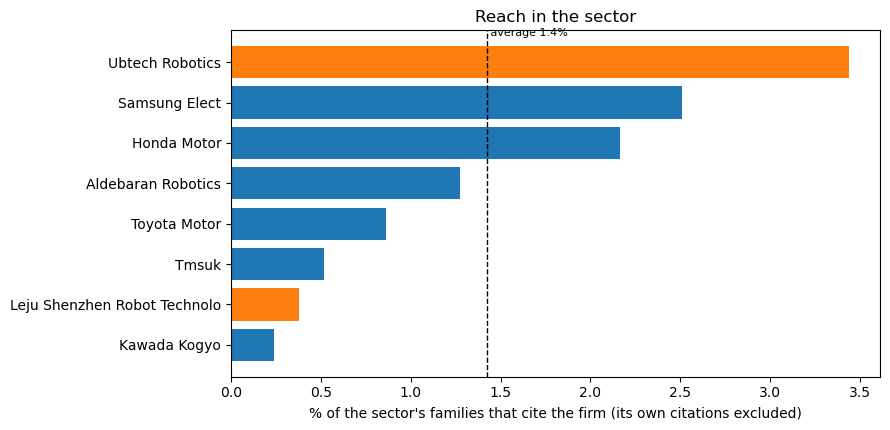

families citing the scored firms within 5 years: 1,213; with applicant names: 100% of the pairs


,Influence,Influence without self-citations,self-citations (%)
UBTECH ROBOTICS,NaN,NaN,23.30
HONDA MOTOR,1.07,0.82,23.64
ALDEBARAN ROBOTICS,0.94,0.88,5.35
TOYOTA MOTOR,0.53,0.41,21.33
SAMSUNG ELECT,1.38,1.29,6.04
KAWADA KOGYO,0.14,0.12,15.38
TMSUK,0.54,0.45,17.65
LEJU SHENZHEN ROBOT TECHNOLOGY,NaN,NaN,23.91


In [28]:
# 1. reach in the sector, as the professor drew it
reach = refinements["reach in the sector (%)"].sort_values()
fig, ax = plt.subplots(figsize=(9, 0.4 * len(reach) + 1.2))
ax.barh([f.title()[:28] for f in reach.index], reach.values, color=[{"incumbent": "tab:blue", "entrant": "tab:orange"}[firms_only.loc[f, "status"]] for f in reach.index])
ax.axvline(reach.mean(), color="black", ls="--", lw=1)
ax.text(reach.mean(), len(reach) - 0.4, f" average {reach.mean():.1f}%", fontsize=8, va="bottom")
ax.set(xlabel="% of the sector's families that cite the firm (its own citations excluded)", title="Reach in the sector")
plt.tight_layout()
plt.show()

# 2. self-citations: the applicants of the families that cite the scored firms within five years
FIRM_PATTERNS = {"UBTECH ROBOTICS": r"\bUBTECH\b|YOUBIXUAN", "HONDA MOTOR": r"\bHONDA\b", "ALDEBARAN ROBOTICS": r"ALDEBARAN|SOFTBANK ROBOTICS",
                 "TOYOTA MOTOR": r"\bTOYOTA\b", "SAMSUNG ELECT": r"\bSAMSUNG\b", "KAWADA KOGYO": r"\bKAWADA\b", "TMSUK": r"\bTMSUK\b",
                 "LEJU SHENZHEN ROBOT TECHNOLOGY": r"\bLEJU\b"}
pattern_of = {f: FIRM_PATTERNS.get(f, r"\b" + re.escape(f.split()[0]) + r"\b") for f in SELECTED}   # other firms: their first word
within5 = fwd_pairs[fwd_pairs["citing_year"] <= fwd_pairs["priority_year"] + HORIZON]               # the rule of n_fwd_cites_5y
firm_cites = within5.merge(firm_fam[["docdb_family_id", "firm"]], on="docdb_family_id")
citers = firm_cites["citing_family"].drop_duplicates().astype(int).tolist()
citer_names = in_chunks(citers, lambda part: db.query(TLS201_APPLN.docdb_family_id, TLS206_PERSON.psn_name)
                        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
                        .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
                        .filter(TLS207_PERS_APPLN.applt_seq_nr > 0, TLS201_APPLN.docdb_family_id.in_(part)).distinct()) if citers else \
              pd.DataFrame(columns=["docdb_family_id", "psn_name"])
names_of = citer_names.assign(psn_name=citer_names["psn_name"].fillna("").astype(str).str.upper()).groupby("docdb_family_id")["psn_name"].agg(" | ".join)
firm_cites["citing_names"] = firm_cites["citing_family"].map(names_of).fillna("")
firm_cites["self"] = [bool(re.search(pattern_of[f], n)) for f, n in zip(firm_cites["firm"], firm_cites["citing_names"])]
print(f"families citing the scored firms within {HORIZON} years: {len(citers):,}; with applicant names: {firm_cites['citing_names'].ne('').mean():.0%} of the pairs")

self5 = firm_cites[firm_cites["self"]].groupby(["firm", "docdb_family_id"])["citing_family"].nunique().rename("self5").reset_index()
fm = firm_mature.dropna(subset=["influence"]).merge(self5, on=["firm", "docdb_family_id"], how="left").fillna({"self5": 0})
fm["influence_noself"] = (fm["n_fwd_cites_5y"] - fm["self5"]).clip(lower=0) / fm["benchmark"]
selfcit = pd.DataFrame({
    "self-citations (%)": firm_cites.groupby("firm")["self"].mean() * 100,
    "Influence without self-citations": fm.groupby("firm")["influence_noself"].mean(),
}).reindex(SELECTED)
selfcit.loc[indicators["mature families (Influence)"] < MIN_MATURE, "Influence without self-citations"] = np.nan
indicators = indicators.drop(columns=[c for c in selfcit.columns if c in indicators.columns]).join(selfcit)
indicators[["Influence", "Influence without self-citations", "self-citations (%)"]].round(2)

**Our reading of reach and self-citations.** UBTECH has the largest reach (3.4% of the sector's families cite it), well above the other firms; Samsung, Honda and Aldebaran follow. The applicants of all 1,213 families that cite the scored firms within five years were found. Self-citations weigh very differently: about a quarter of the citations of UBTECH (23%), Honda (24%) and Toyota (21%) are their own, against 5% for Aldebaran and 6% for Samsung. Without them Samsung stays first (1.29), Aldebaran (0.88) passes Honda (0.82), and Tmsuk (0.45), Toyota (0.41) and Kawada (0.12) stay behind. Samsung's and Aldebaran's influence comes from other firms; part of Honda's comes from its own later work.

In [29]:
# The four basic indicators side by side, with what they rest on: the input of Section 7
BASE = {"Volume": "Volume (%)", "Influence": "Influence", "Success": "Success (%)", "Globalization": "Globalization"}
REST_ON = {"Volume": "families", "Influence": "mature families (Influence)", "Success": "applications (old enough)",
           "Globalization": "mature families (Globalization)"}
summary = pd.concat({**{k: indicators[v] for k, v in BASE.items()},
                     **{f"n {k}": indicators[v] for k, v in REST_ON.items()}}, axis=1)
summary.insert(0, "status", firms_only.loc[SELECTED, "status"])
summary.round(2)

,status,Volume,Influence,Success,Globalization,n Volume,n Influence,n Success,n Globalization
UBTECH ROBOTICS,entrant,3.23,NaN,87.21,1.47,94,9,60,59
HONDA MOTOR,incumbent,1.41,1.07,79.70,2.37,41,40,100,41
ALDEBARAN ROBOTICS,incumbent,1.07,0.94,63.39,9.18,31,28,266,28
TOYOTA MOTOR,incumbent,0.86,0.53,64.00,1.16,25,25,29,25
SAMSUNG ELECT,incumbent,0.83,1.38,72.35,2.64,24,22,58,22
KAWADA KOGYO,incumbent,0.45,0.14,61.54,1.00,13,12,13,13
TMSUK,incumbent,0.45,0.54,10.26,1.54,13,13,20,13
LEJU SHENZHEN ROBOT TECHNOLOGY,entrant,0.48,NaN,NaN,1.00,14,1,2,10


## 6. Where the top firms invent (Tutorial 3, notebook 31)

Notebook 31 asks where the inventors of a sector live, and whether knowledge travels more easily between inventors who live close to each other (knowledge spillovers). It works with the European regions (NUTS) of the inventors, read from their addresses. Our sector invents mostly in China, Japan and Korea (Step 1, Section 9), where PATSTAT gives no NUTS region, so we follow the advice of notebook 31 (its Section 9) and work at the level of the **country**, with the European regions only where there are European inventors.

1. **Owners and inventors (6.1).** For each firm, the country of the applicant and the countries of its inventors: does it invent where it is registered, or does it run research centres abroad?
2. **The European regions (6.2).** For the families with inventors in Europe, the NUTS 2 regions where they live, and the firms behind them.
3. **Are the citations of the sector more local than chance? (6.3)** For each citation between two families of the sector, are the citing and the cited inventors in the same country? We compare the observed share with the share expected **by chance** (Jaffe, Trajtenberg and Henderson, 1993; notebook 31, Section 7): if the citation had been made by a random family of the sector of the same year, how likely would it be to come from the cited country? With most families invented in China (65% are first filed there), many citations would link two Chinese inventors even if knowledge travelled freely: only a share well above chance says that knowledge stays at home.

**The country of a family** is the country of most of its inventors (Step 0 saved one row per family and inventor country, with the share of the inventors). PATSTAT often leaves the inventor's country empty, above all in Chinese and Japanese records, and Step 0 wrote it as `??`: an unknown country, not a country. For these families we follow de Rassenfosse, Kozak and Seliger (2019), who fill the gap in two steps: the country of the applicants of the family, and if that is unknown too, the office of first filing (an inventor files first at home in most cases). The test of 6.3 is run twice: on the families whose inventor country is known (the strict test of notebook 31), and with the filled countries (a check, because a country taken from the office pushes towards "same country").

In [30]:
family_inventors = load_table("family_inventors")          # one row per family and inventor country, with the share of the inventors
fi = family_inventors.assign(inventor_country=family_inventors["inventor_country"].fillna("").astype(str).str.strip())
fi = fi[~fi["inventor_country"].isin(["", "??"])]          # Step 0 writes "??" for an inventor without a country


def main_country(table, column):
    "The country with the largest weight in each family (ties: alphabetical order)."
    return (table.groupby(["docdb_family_id", column])["weight"].sum().reset_index()
            .sort_values(["docdb_family_id", "weight", column], ascending=[True, False, True])
            .drop_duplicates("docdb_family_id").set_index("docdb_family_id")[column])


families["inventor_country"] = families["docdb_family_id"].map(main_country(fi, "inventor_country"))

# the gaps, filled as de Rassenfosse et al. (2019): first the applicants' country, then the office of first filing
fa = family_applicants.assign(country=family_applicants["country"].fillna("").astype(str).str.strip())
fa["firm"] = fa["applicant"].map(name_to_firm).fillna(fa["applicant"])
from_applicants = families["docdb_family_id"].map(main_country(fa[~fa["country"].isin(["", "??"])], "country"))
REGIONAL = {"EP", "WO", "EA", "AP", "OA", "GC"}                # regional offices are not countries
office_of = first_office[~first_office["office"].isin(REGIONAL)].set_index("docdb_family_id")["office"]
from_office = families["docdb_family_id"].map(office_of)
families["country"] = families["inventor_country"].fillna(from_applicants).fillna(from_office)
families["country_source"] = np.select([families["inventor_country"].notna(), from_applicants.notna(), from_office.notna()],
                                       ["inventors", "applicants", "office of first filing"], "unknown")
print(f"families of the sector: {len(families):,}; where their country comes from:")
display(families["country_source"].value_counts().to_frame("families")
        .assign(share=lambda d: (d["families"] / len(families) * 100).round(1)))
print("inventors known, by office of first filing (%):",
      (families.assign(office=families["docdb_family_id"].map(first_office.set_index("docdb_family_id")["office"]))
       .groupby("office")["inventor_country"].apply(lambda s: round(s.notna().mean() * 100))
       .loc[lambda x: x.index.isin(["CN", "JP", "KR", "US", "EP"])].to_dict()))

# the country of each firm: its most frequent known applicant country in PATSTAT, else the office where it files first
applicant_country = fa[~fa["country"].isin(["", "??"])].groupby("firm")["country"].agg(lambda c: c.value_counts().index[0])
firm_first_office = (fam_firm.assign(office=fam_firm["docdb_family_id"].map(office_of)).dropna(subset=["office"])
                     .groupby("firm")["office"].agg(lambda c: c.value_counts().index[0]))

SHOWN = list(dict.fromkeys(SELECTED + net_firms))          # the scored firms, then the largest firms of Section 3.2
rows = []
for firm in SHOWN:
    ids = fam_firm.loc[fam_firm["firm"] == firm, "docdb_family_id"]
    own = families.loc[families["docdb_family_id"].isin(ids)]
    countries = own["inventor_country"].dropna()
    home = applicant_country.get(firm, "") or firm_first_office.get(firm, "")
    source = "applicants" if firm in applicant_country.index else ("first office" if home else "")
    shares = countries.value_counts(normalize=True)
    rows.append({"firm": firm, "scored": firm in SELECTED, "home country": home or "(unknown)", "home from": source,
                 "families": len(own), "inventor country known (%)": len(countries) / len(own) * 100 if len(own) else np.nan,
                 "inventor countries (known)": ", ".join(f"{c} {s:.0%}" for c, s in shares.head(3).items()) or "-",
                 "invented abroad (%)": (countries != home).mean() * 100 if home and len(countries) >= 5 else np.nan})
owners = pd.DataFrame(rows).set_index("firm")
owners.round(1)

families of the sector: 2,907; where their country comes from:


,families,share
country_source,,
office of first filing,2422,83.3
inventors,455,15.7
applicants,30,1.0


inventors known, by office of first filing (%): {'CN': 4, 'EP': 100, 'JP': 19, 'KR': 81, 'US': 100}


,scored,home country,home from,families,inventor country known (%),inventor countries (known),invented abroad (%)
firm,,,,,,,
UBTECH ROBOTICS,True,CN,applicants,94,40.4,CN 100%,0.0
HONDA MOTOR,True,JP,applicants,41,65.9,"JP 67%, US 26%, KR 7%",33.3
ALDEBARAN ROBOTICS,True,FR,applicants,31,90.3,"FR 93%, JP 7%",7.1
TOYOTA MOTOR,True,JP,applicants,25,8.0,JP 100%,NaN
SAMSUNG ELECT,True,KR,applicants,24,95.8,KR 100%,0.0
KAWADA KOGYO,True,JP,first office,13,0.0,-,NaN
TMSUK,True,JP,applicants,13,30.8,JP 100%,NaN
LEJU SHENZHEN ROBOT TECHNOLOGY,True,CN,first office,14,0.0,-,NaN
GUANGZHOU LIGONG INDUSTRIAL,False,CN,first office,92,0.0,-,NaN


**Our reading of owners and inventors.** PATSTAT gives the inventor's country for only 16% of the families of the sector (455 of 2,907): for all the families first filed at the EPO or in the US, 81% of those first filed in Korea, 19% in Japan and 4% in China. For 83% of the families the country therefore comes from the office of first filing, so any statement on where the sector invents is mostly a statement on where it files first (Step 1, Section 9.2, found the same gap).

On the families where the country is known, humanoid research stays at home. UBTECH invents only in China, Samsung only in Korea, Toyota and Tmsuk only in Japan, Figure AI only in the United States, and Aldebaran in France (93%, the rest in Japan). Honda is the only scored firm with research abroad: a third of its families with known inventors were invented outside Japan, mostly in the United States (26%). For UBTECH (40% known), Toyota (8%) and Tmsuk (31%) these shares rest on few families; for Kawada, Leju and most Chinese entrants no inventor country is known at all. For Electrolux this means that working with any of these firms means working with research done in its home country: none of them has a research base in Europe, apart from Aldebaran in Paris (Section 6.2).

In [31]:
# 6.2 The European regions: the NUTS code of the inventors who live in Europe (TLS206), for all the applications of the sector
EUROPE = {"AT", "BE", "BG", "CH", "CY", "CZ", "DE", "DK", "EE", "ES", "FI", "FR", "GB", "GR", "HR", "HU", "IE", "IS", "IT",
          "LI", "LT", "LU", "LV", "MT", "NL", "NO", "PL", "PT", "RO", "SE", "SI", "SK", "TR"}
inv_nuts = in_chunks(applications["appln_id"], lambda part: db.query(
    TLS201_APPLN.docdb_family_id, TLS206_PERSON.person_id, TLS206_PERSON.person_ctry_code, TLS206_PERSON.nuts)
    .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
    .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
    .filter(TLS207_PERS_APPLN.invt_seq_nr > 0, TLS201_APPLN.appln_id.in_(part)))
inv_nuts["ctry"] = inv_nuts["person_ctry_code"].fillna("").astype(str).str.strip()
inv_nuts["nuts2"] = inv_nuts["nuts"].fillna("").astype(str).str.strip().str[:4]
europe = inv_nuts[inv_nuts["ctry"].isin(EUROPE)]
located = europe[europe["nuts2"].str.len() == 4]
print(f"inventors of the sector: {inv_nuts['person_id'].nunique():,}; living in Europe: {europe['person_id'].nunique():,} "
      f"({europe['docdb_family_id'].nunique():,} families); with a NUTS 2 region: {located['person_id'].nunique():,}")
print("European inventor countries (families):", europe.drop_duplicates(["docdb_family_id", "ctry"])["ctry"].value_counts().head(8).to_dict())
regions = (located.drop_duplicates(["docdb_family_id", "nuts2"]).assign(firm=lambda d: d["docdb_family_id"].map(main_firm))
           .groupby("nuts2").agg(families=("docdb_family_id", "nunique"),
                                 main_applicants=("firm", lambda s: ", ".join(f"{f} ({n})" for f, n in s.value_counts().head(2).items())))
           .sort_values("families", ascending=False))
regions.head(10)

inventors of the sector: 7,445; living in Europe: 432 (59 families); with a NUTS 2 region: 62
European inventor countries (families): {'FR': 32, 'DE': 11, 'IT': 5, 'CH': 3, 'PL': 3, 'GB': 3, 'HU': 2, 'RO': 2}


,families,main_applicants
nuts2,,
FR10,28,"ALDEBARAN ROBOTICS (24), ALFAYAD SAMER (4)"
FR51,2,ALDEBARAN ROBOTICS (2)
FR71,2,ALDEBARAN ROBOTICS (2)
DE13,1,UNIVERSITAETSKLINIKUM FREIBURG (1)
DE71,1,DUNN MARK (1)
FR62,1,ALDEBARAN ROBOTICS (1)


**Our reading of the European regions.** Only 59 families of the sector (2%) have an inventor living in Europe. France leads (32 families), then Germany (11) and Italy (5). The regions give a clear picture: Île-de-France (FR10) has 28 families, 24 of them Aldebaran's and 4 of an individual inventor, Samer Alfayad, and the other French regions appear only through Aldebaran. Europe invents humanoid robots in one cluster, Paris, around one firm. For Electrolux, the European know-how in this sector sits in that cluster. The counts of inventors are rough: PATSTAT can give the same inventor several person ids, and only 62 inventors have a NUTS code.

In [32]:
# 6.3 Are the citations inside the sector more local than chance? (country level, notebook 31, Section 7)
if "family_citations" not in globals():
    family_citations = load_table("family_citations")
pairs = (family_citations[family_citations["citing"].isin(SECTOR_IDS) & family_citations["cited"].isin(SECTOR_IDS)
                          & (family_citations["citing"] != family_citations["cited"])][["citing", "cited"]].drop_duplicates())
year_of = families.set_index("docdb_family_id")["priority_year"]
pairs = pairs.assign(citing_year=pairs["citing"].map(year_of),
                     same_firm=pairs["citing"].map(main_firm) == pairs["cited"].map(main_firm))


def localisation(p, year_shares):
    "Observed share of citations between families of the same country, and the share expected by chance."
    key = pd.MultiIndex.from_arrays([p["citing_year"], p["cited_country"]])
    chance = year_shares.reindex(key).fillna(0).to_numpy()
    return pd.Series({"citations": len(p), "same country (%)": (p["citing_country"] == p["cited_country"]).mean() * 100,
                      "by chance (%)": chance.mean() * 100})


def localisation_table(column):
    "The test with the country of the families in `column`: only the pairs where both countries are known."
    country_of = families.set_index("docdb_family_id")[column]
    p = pairs.assign(citing_country=pairs["citing"].map(country_of), cited_country=pairs["cited"].map(country_of))
    p = p.dropna(subset=["citing_country", "cited_country"])
    # by chance: the share of the sector's families of the citing year that are in the cited country (same families as the test)
    year_shares = families.dropna(subset=[column]).groupby("priority_year")[column].value_counts(normalize=True)
    groups = {"all citations inside the sector": p, "without self-citations (same firm)": p[~p["same_firm"]]}
    for c in ["CN", "JP", "KR", "US"]:
        groups[f"cited family in {c}, no self-citations"] = p[~p["same_firm"] & (p["cited_country"] == c)]
    t = pd.DataFrame({name: localisation(g, year_shares) for name, g in groups.items() if len(g)}).T
    t["citations"] = t["citations"].astype(int)
    t["observed / chance"] = t["same country (%)"] / t["by chance (%)"]
    return t


print(f"citations between two families of the sector: {len(pairs):,}")
local = pd.concat({"inventor country known (strict)": localisation_table("inventor_country"),
                   "with the filled countries (check)": localisation_table("country")})
local.round(2)

citations between two families of the sector: 2,750


citations  \
inventor country known (strict)   all citations inside the sector              429   
                                  without self-citations (same firm)           346   
                                  cited family in CN, no self-citations         42   
                                  cited family in JP, no self-citations         82   
                                  cited family in KR, no self-citations         68   
                                  cited family in US, no self-citations        112   
with the filled countries (check) all citations inside the sector             2750   
                                  without self-citations (same firm)          2329   
                                  cited family in CN, no self-citations       1655   
                                  cited family in JP, no self-citations        251   
                                  cited family in KR, no self-citations        179   
                                  cited family in US, no self-citations        160   

                                                                         same country (%)  \
inventor country known (strict)   all citations inside the sector                   56.18   
                                  without self-citations (same firm)                46.24   
                                  cited family in CN, no self-citations             90.48   
                                  cited family in JP, no self-citations             19.51   
                                  cited family in KR, no self-citations             23.53   
                                  cited family in US, no self-citations             79.46   
with the filled countries (check) all citations inside the sector                   79.85   
                                  without self-citations (same firm)                76.30   
                                  cited family in CN, no self-citations             97.34   
                                  cited family in JP, no self-citations             21.51   
                                  cited family in KR, no self-citations             12.29   
                                  cited family in US, no self-citations             55.62   

                                                                         by chance (%)  \
inventor country known (strict)   all citations inside the sector                34.51   
                                  without self-citations (same firm)             29.57   
                                  cited family in CN, no self-citations          52.36   
                                  cited family in JP, no self-citations          13.48   
                                  cited family in KR, no self-citations          26.62   
                                  cited family in US, no self-citations          44.52   
with the filled countries (check) all citations inside the sector                67.46   
                                  without self-citations (same firm)             65.73   
                                  cited family in CN, no self-citations          89.06   
                                  cited family in JP, no self-citations          12.43   
                                  cited family in KR, no self-citations           8.51   
                                  cited family in US, no self-citations           6.06   

                                                                         observed / chance  
inventor country known (strict)   all citations inside the sector                     1.63  
                                  without self-citations (same firm)                  1.56  
                                  cited family in CN, no self-citations               1.73  
                                  cited family in JP, no self-citations               1.45  
                                  cited family in KR, no self-citations               0.88  
               

**Our reading of the localisation test.** The sector has 2,750 citations between two of its families. With the strict test (inventor country known on both sides) 429 remain, 346 without self-citations. Of these, 46% link two families of the same country, against 30% expected by chance: knowledge stays in the country 1.6 times more than chance, the result of Jaffe, Trajtenberg and Henderson (1993) at the level of countries. The effect holds for the families invented in China (90% of their citations come from Chinese families, against 52% by chance, 1.7 times), the United States (79% against 45%, 1.8 times) and Japan (20% against 13%, 1.5 times). Korea is the exception: its families are cited from abroad as much as chance predicts (0.88), which fits Samsung being the most cited portfolio of the sector (Section 5.5).

With the filled countries the test covers all 2,329 citations without self-citations and the effect is weaker (1.16): when the country comes from the office of first filing, almost every family is Chinese, so chance alone already gives 66%. The US value of the check (9.2) is not comparable: the filled countries leave very few US families in the sector, so the chance share is small.

Three cautions. The strict test rests on 42 to 112 citations per country and on the families with a known inventor, which are mostly those filed at the EPO or in the US. The citations include those added by examiners, which are noise for this question (notebook 31, Section 7). And a local citation is a flow of knowledge, not necessarily a spillover (notebook 31, Section 10). For Electrolux the message is that the humanoid knowledge of the sector is built mostly inside China, the United States and Japan, and reaches a European firm mainly through its patents filed abroad.

**Three more views of the same citations** (notebook 31, Sections 6, 7 and 8), all with the strict countries (inventor country known on both sides) and without self-citations:

1. **Who cites whom** (Section 6, the "map" of flows, here at the level of countries): a table with the country of the cited family in the rows (where the knowledge comes from) and the country of the citing family in the columns (where it goes).
2. **Applicants or examiners?** (Section 7) The citations between families (TLS228) do not keep their origin, but the publication-level citations of Section 3.3 do. The applicant's citations are the closest trace of a flow between people; if knowledge travels through people, they should be the more local ones.
3. **Does knowledge fade with distance?** (Section 8) Notebook 31 measures kilometres between NUTS 3 regions; our sector has 59 families with an inventor in Europe, so we measure the distance between the capitals of the two countries and compare each distance band with chance, as in Section 6.3.

In [33]:
strict = pairs.assign(citing_country=pairs["citing"].map(families.set_index("docdb_family_id")["inventor_country"]),
                      cited_country=pairs["cited"].map(families.set_index("docdb_family_id")["inventor_country"]))
strict = strict.dropna(subset=["citing_country", "cited_country"])
strict = strict[~strict["same_firm"]]
MAIN_C = ["CN", "JP", "KR", "US", "FR"]
group = lambda c: c.where(c.isin(MAIN_C), "other")
flows = pd.crosstab(group(strict["cited_country"]).rename("cited (from)"), group(strict["citing_country"]).rename("citing (to)"), margins=True, margins_name="all")
print(f"1. who cites whom: {len(strict):,} citations between families with a known inventor country, self-citations excluded")
display(flows)

# 2. the same test split by the origin of the citation (publication-level citations of Section 3.3)
inv_c = families.set_index("docdb_family_id")["inventor_country"]
by_origin = (fwd[fwd["citing_family"].isin(SECTOR_IDS) & fwd["cited_family"].isin(SECTOR_IDS)]
             .drop_duplicates(["citing_family", "cited_family", "who"])
             .rename(columns={"citing_family": "citing", "cited_family": "cited"}))
by_origin = by_origin.assign(citing_year=by_origin["citing"].map(year_of), citing_country=by_origin["citing"].map(inv_c),
                             cited_country=by_origin["cited"].map(inv_c),
                             same_firm=by_origin["citing"].map(main_firm) == by_origin["cited"].map(main_firm))
by_origin = by_origin.dropna(subset=["citing_country", "cited_country"])
by_origin = by_origin[~by_origin["same_firm"]]
year_shares_strict = families.dropna(subset=["inventor_country"]).groupby("priority_year")["inventor_country"].value_counts(normalize=True)
origin_test = pd.DataFrame({who: localisation(p, year_shares_strict) for who, p in by_origin.groupby("who")}).T if len(by_origin) else pd.DataFrame()
if len(origin_test):
    origin_test["citations"] = origin_test["citations"].astype(int)
    origin_test["observed / chance"] = origin_test["same country (%)"] / origin_test["by chance (%)"]
print("2. applicant or examiner citations (publication level, strict countries, no self-citations):")
display(origin_test.round(2))

# 3. distance between the capitals of the two countries, in bands, observed against chance
CAPITALS = {"CN": (39.90, 116.41), "JP": (35.68, 139.69), "KR": (37.57, 126.98), "US": (38.90, -77.04), "FR": (48.86, 2.35),
            "DE": (52.52, 13.40), "IT": (41.90, 12.50), "GB": (51.51, -0.13), "CH": (46.95, 7.45), "TW": (25.03, 121.57),
            "CA": (45.42, -75.70), "ES": (40.42, -3.70), "NL": (52.37, 4.90), "SE": (59.33, 18.07), "RU": (55.76, 37.62),
            "IN": (28.61, 77.21), "IL": (31.77, 35.21), "AU": (-35.28, 149.13), "BE": (50.85, 4.35), "AT": (48.21, 16.37),
            "DK": (55.68, 12.57), "FI": (60.17, 24.94), "NO": (59.91, 10.75), "PL": (52.23, 21.01), "SG": (1.35, 103.82),
            "HK": (22.32, 114.17), "HU": (47.50, 19.04), "RO": (44.43, 26.10), "CZ": (50.08, 14.44), "IE": (53.35, -6.26),
            "PT": (38.72, -9.14), "GR": (37.98, 23.73), "TR": (39.93, 32.86), "BR": (-15.79, -47.88), "MX": (19.43, -99.13),
            "UA": (50.45, 30.52), "NZ": (-41.29, 174.78), "MY": (3.14, 101.69), "TH": (13.76, 100.50), "SA": (24.71, 46.68),
            "AE": (24.45, 54.38), "IR": (35.69, 51.39), "VN": (21.03, 105.85), "LU": (49.61, 6.13), "SI": (46.06, 14.51)}


def km(a, b):
    "Great-circle distance between the capitals of two countries (km); NaN when a country is not in CAPITALS."
    if a not in CAPITALS or b not in CAPITALS:
        return np.nan
    (la1, lo1), (la2, lo2) = np.radians(CAPITALS[a]), np.radians(CAPITALS[b])
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(h))


BANDS = [-1, 0, 2500, 9000, 21000]
BAND_NAMES = ["same country", "up to 2,500 km", "2,500-9,000 km", "more than 9,000 km"]
band_of = lambda d: pd.cut(pd.Series(d, dtype=float), BANDS, labels=BAND_NAMES)
strict = strict.assign(km=[km(a, b) for a, b in zip(strict["citing_country"], strict["cited_country"])]).dropna(subset=["km"])
observed = band_of(strict["km"].values).value_counts(normalize=True).reindex(BAND_NAMES) * 100
chance = np.zeros(len(BAND_NAMES))
for (yr, cited_c), n in strict.groupby(["citing_year", "cited_country"]).size().items():
    shares = year_shares_strict.loc[yr] if yr in year_shares_strict.index.get_level_values(0) else pd.Series(dtype=float)
    d = pd.Series({c: km(c, cited_c) for c in shares.index}).dropna()
    w = shares.reindex(d.index)
    if w.sum() > 0:
        chance += n * (w / w.sum()).groupby(band_of(d.values).values, observed=False).sum().reindex(BAND_NAMES).fillna(0).values
decay = pd.DataFrame({"observed (%)": observed, "by chance (%)": chance / max(len(strict), 1) * 100})
decay["observed / chance"] = decay["observed (%)"] / decay["by chance (%)"].replace(0, np.nan)
print(f"3. distance between the two countries ({len(strict):,} citations with both capitals known):")
decay.round(2)

1. who cites whom: 346 citations between families with a known inventor country, self-citations excluded


citing (to),CN,FR,JP,KR,US,other,all
cited (from),,,,,,,
CN,38,0,0,0,4,0,42
FR,7,1,0,2,17,1,28
JP,14,3,16,16,27,6,82
KR,22,9,4,16,17,0,68
US,16,5,0,2,89,0,112
other,3,0,0,1,10,0,14
all,100,18,20,37,164,7,346


2. applicant or examiner citations (publication level, strict countries, no self-citations):


,citations,same country (%),by chance (%),observed / chance
applicant,144,54.17,32.32,1.68
examiner or other,231,40.69,27.93,1.46


3. distance between the two countries (346 citations with both capitals known):


,observed (%),by chance (%),observed / chance
same country,46.24,29.74,1.56
"up to 2,500 km",19.08,23.97,0.80
"2,500-9,000 km",12.43,16.96,0.73
"more than 9,000 km",22.25,29.33,0.76


**Our reading of the three views.**

1. **Who cites whom.** Of the 346 citations with known countries, US families make 164 (47%): US applicants cite a lot (they must disclose the prior art they know). Chinese families are cited almost only by Chinese ones (38 of 42), while they cite Korea (22), the US (16), Japan (14) and France (7): China learns from abroad, but in these data the rest of the world does not yet build on Chinese patents. Korean knowledge spreads most widely (cited by China 22, the US 17, Korea 16, France 9), and Japanese knowledge goes mainly to the US (27).
2. **Applicants or examiners.** The applicant's citations stay in the country more than chance predicts (54% against 32%, 1.7 times; 144 citations), the examiner's less (41% against 28%, 1.5 times; 231). This is what notebook 31 expects if knowledge travels through people: inventors know their national colleagues' patents better.
3. **Distance.** A citation is 1.6 times more likely than chance to stay in the same country, but beyond the border the distance hardly matters: every band is below chance and about at the same level (0.80 up to 2,500 km, 0.73 from 2,500 to 9,000 km, 0.76 beyond). A Japanese family is not more likely to cite a Korean neighbour than an American one. In this sector the border counts more than the kilometres; the distances are between capitals and rest on 346 citations.

## 7. One score from four indicators (notebook 40, Section 8)

Each firm has four numbers in different units (a share, a ratio, a percentage, a count of offices). Notebook 40 turns them into one ranking in three steps: make the indicators **comparable**, choose the **weights**, **combine**. It offers two ways to make them comparable, and we compute both:

- **A · ratio to the mean**: each value divided by the average of the scored firms (1.4 = 40% above the average firm); it keeps the size of the gaps, and it is combined with a weighted mean (100 = average firm);
- **B · ranks**: the position of the firm on each indicator; it keeps only the order, and it is combined with the **Reciprocal Rank Fusion** (Cormack et al., 2009): each position is worth $(c+1)/(c+\text{position})$ points, with $c$ equal to the number of firms (100 = first on every indicator).

**Missing indicators.** Notebook 40 scores firms that have all four indicators. In our sector the young firms do not, because their families are too recent (Section 5.1). Our rule: a firm needs at least `MIN_INDICATORS` = 3 of the 4 indicators to be scored, and its weights are rescaled over the indicators it has, so that a missing indicator is neither a zero nor a bonus. Section 8 checks the ranking of the firms with all four.

scored: 7 firms (Ubtech, Honda, Aldebaran, Toyota, Samsung, Kawada Kogyo, Tmsuk); not scored (fewer than 3 indicators): LEJU SHENZHEN ROBOT TECHNOLOGY
indicators available: {'UBTECH ROBOTICS': 3, 'HONDA MOTOR': 4, 'ALDEBARAN ROBOTICS': 4, 'TOYOTA MOTOR': 4, 'SAMSUNG ELECT': 4, 'KAWADA KOGYO': 4, 'TMSUK': 4}


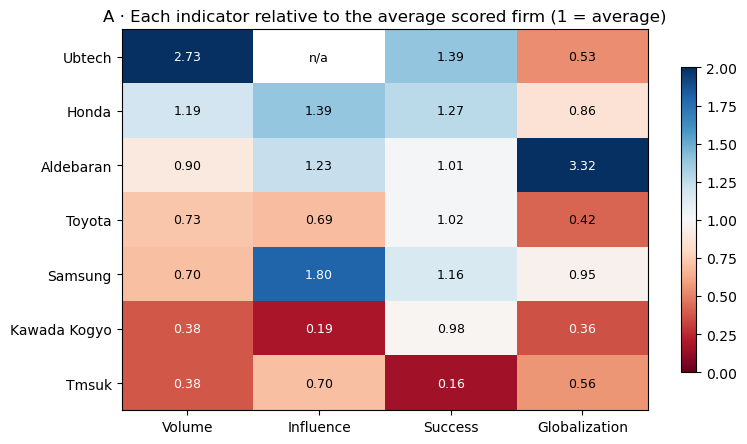

In [34]:
INDICATORS = ["Volume", "Influence", "Success", "Globalization"]
MIN_INDICATORS = 3
firms = summary[INDICATORS].astype(float)
n_available = firms.notna().sum(axis=1)
SCORED = n_available[n_available >= MIN_INDICATORS].index.tolist()
NOT_SCORED = n_available[n_available < MIN_INDICATORS].index.tolist()
firms = firms.loc[SCORED]
SHORT = {f: f.title().replace(" Robotics", "").replace(" Motor", "").replace(" Elect", "")[:18] for f in SCORED}
print(f"scored: {len(SCORED)} firms ({', '.join(SHORT[f] for f in SCORED)}); "
      f"not scored (fewer than {MIN_INDICATORS} indicators): {', '.join(NOT_SCORED) or 'none'}")
print("indicators available:", n_available.loc[SCORED].to_dict())

# A · ratio to the mean: 1 = average scored firm (a missing value stays missing)
relative = firms / firms.mean()
fig, ax = plt.subplots(figsize=(8, 0.45 * len(relative) + 1.4))
im = ax.imshow(relative.values, cmap="RdBu", vmin=0, vmax=2, aspect="auto")
ax.set_xticks(range(len(INDICATORS)), INDICATORS)
ax.set_yticks(range(len(relative)), [SHORT[f] for f in relative.index])
for i in range(relative.shape[0]):
    for j in range(relative.shape[1]):
        v = relative.iat[i, j]
        ax.text(j, i, "n/a" if pd.isna(v) else f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if pd.notna(v) and abs(v - 1) > 0.6 else "black")
ax.set_title("A · Each indicator relative to the average scored firm (1 = average)")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

**What the data say about the weights.** In class the professor asked us to look in the data for the dimensions that matter in our sector: if every firm files a lot, Volume cannot tell them apart and should weigh little. Two checks on the scored firms: how much each indicator **separates** them (the coefficient of variation, and the ratio between the best and the median firm), and how much the indicators **repeat each other** (rank correlation between them): two indicators that give the same order count twice if both weigh a lot.

In [35]:
spread = pd.DataFrame({
    "coefficient of variation": firms.std() / firms.mean(),
    "best / median firm": firms.max() / firms.median(),
    "firms measured": firms.notna().sum(),
})
display(spread.round(2))
firms.corr(method="spearman").round(2)

,coefficient of variation,best / median firm,firms measured
Volume,0.81,3.76,7
Influence,0.58,1.87,6
Success,0.40,1.36,7
Globalization,1.05,5.97,7


,Volume,Influence,Success,Globalization
Volume,1.00,0.49,0.85,0.27
Influence,0.49,1.00,0.66,0.83
Success,0.85,0.66,1.00,0.14
Globalization,0.27,0.83,0.14,1.00


**Our reading of the data check.** Globalization separates the firms the most (coefficient of variation 1.05, the best firm six times the median), but almost all of the spread is Aldebaran. Volume follows (0.81, UBTECH 3.8 times the median). Influence (0.58) separates the firms in a more even way. Success separates them the least (0.40): six firms are between 62% and 87%, and Tmsuk alone is at 10%. Two pairs of indicators give almost the same order: Volume and Success (0.85), and Influence and Globalization (0.83). So the data support a low weight for Success, which separates little and repeats Volume. They also warn that Influence and Globalization, together 60% of our weights, partly count the same thing. Section 8 tests both, without Success and without Globalization. With seven firms these correlations are fragile: one firm that changes place moves them a lot.

**The weights for humanoid robots.** There is no universal set of weights (notebook 40, Section 8.4): ours come from how patents are used in this sector and from the question of our client.

- **Influence 0.35**, the largest weight. The sector is young and its technology is still being settled: whose patents the others build on (Section 3.2) is the best sign of a portfolio that matters today. It also separates the firms without resting on one outlier, unlike Globalization (check above).
- **Globalization 0.25.** Electrolux is a European group that sells worldwide: a portfolio protected only in one country is worth less to it, and filing in several offices is a costly choice that firms make only for inventions they value.
- **Success 0.20.** A granted patent can be enforced; but grant rates depend on the office, so we keep it below the first two.
- **Volume 0.20.** The sector is fragmented and many applicants file a few families; part of the Chinese volume is also driven by public support for patenting (Step 2, PEST). Size matters for a target, but alone it is a weak signal of value.

The two checks above say whether the data agree with this reasoning (an indicator that hardly separates the firms, or that repeats another one, should not get a large weight). Section 8 repeats the ranking with equal weights, with size first, and without each indicator.

In [36]:
WEIGHTS = {"Influence": 0.35, "Globalization": 0.25, "Success": 0.20, "Volume": 0.20}
RRF_C = len(SCORED)                      # the constant c of RRF: the number of scored firms (notebook 40, Section 8.5)
print("Sum of the weights:", round(sum(WEIGHTS.values()), 3), "| points of each position in RRF (1st = 100):",
      [int(round(100 * (RRF_C + 1) / (RRF_C + p))) for p in range(1, RRF_C + 1)])


def combine(table, weights, method):
    """One score per firm, higher = better. 'mean': 100 = average firm; 'rrf': 100 = first on every indicator;
    'minmax': 0-100 scale of each indicator (the scale of our first draft). The weights of a firm are rescaled
    over the indicators it has."""
    w = pd.Series(weights, dtype=float)
    t = table[w.index].astype(float)
    w_firm = t.notna().mul(w, axis=1)
    w_firm = w_firm.div(w_firm.sum(axis=1), axis=0)
    if method == "mean":
        parts = t / t.mean()
    elif method == "rrf":
        parts = (RRF_C + 1) / (RRF_C + t.rank(ascending=False, method="min"))
    elif method == "minmax":
        parts = (t - t.min()) / (t.max() - t.min())
    else:
        raise ValueError("method must be 'mean', 'rrf' or 'minmax'")
    return 100 * (parts * w_firm).sum(axis=1, min_count=1)


def final_rank(scores):
    "From scores to the ranking: 1 = best firm."
    return scores.rank(ascending=False, method="min").astype("Int64")


positions = firms.rank(ascending=False, method="min").astype("Int64").add_prefix("pos. ")
both = pd.DataFrame({"A · mean": combine(firms, WEIGHTS, "mean"), "B · RRF": combine(firms, WEIGHTS, "rrf")})
both["rank A"] = final_rank(both["A · mean"])
both["rank B"] = final_rank(both["B · RRF"])
positions.join(both.round(1)).sort_values("rank B").rename(index=SHORT)

Sum of the weights: 1.0 | points of each position in RRF (1st = 100): [100, 89, 80, 73, 67, 62, 57]


,pos. Volume,pos. Influence,pos. Success,pos. Globalization,A · mean,B · RRF,rank A,rank B
Ubtech,1,<NA>,1,5,147.4,87.2,2,1
Honda,2,2,2,3,119.3,86.7,4,2
Samsung,5,1,3,2,123.9,86.6,3,3
Aldebaran,3,3,5,1,164.3,82.3,1,4
Toyota,4,5,4,6,69.7,67.8,5,5
Tmsuk,6,4,7,4,49.2,67.4,6,6
Kawada Kogyo,6,6,6,7,42.8,60.4,7,7


**Our reading of the two methods.** With ranks (B) the first four firms are within 5 points: UBTECH 87.2, Honda 86.7, Samsung 86.6, Aldebaran 82.3. Then a gap of 14 points separates them from Toyota (67.8), Tmsuk (67.4) and Kawada (60.4). With the mean (A), Aldebaran is first (164) because its Globalization is 3.3 times the average firm; UBTECH is second (147) on Volume, and Samsung (124) and Honda (119) follow. The two methods agree on the same four firms at the top and the same three at the bottom, and disagree on the order inside the four.

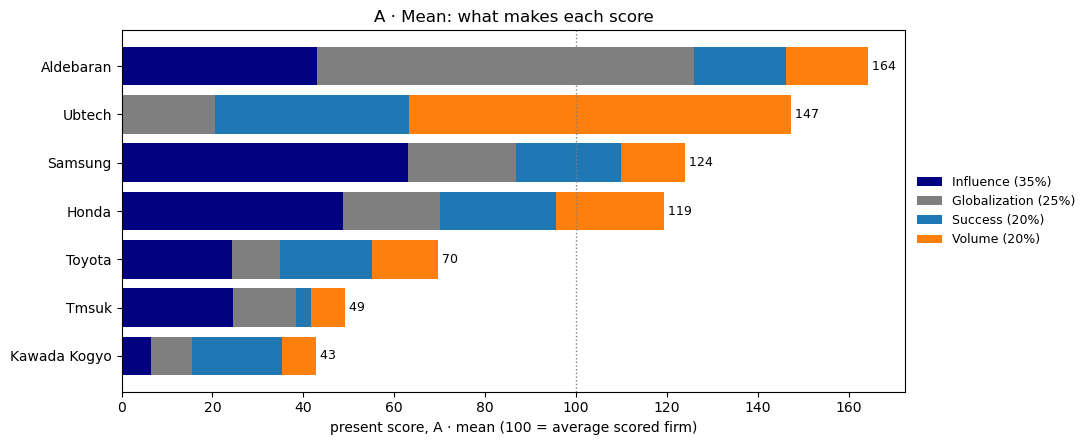

In [37]:
# A · mean: what makes each score (the contribution of each indicator, with the weights rescaled for the firms with a missing one)
w = pd.Series(WEIGHTS)
w_firm = firms[w.index].notna().mul(w, axis=1)
w_firm = w_firm.div(w_firm.sum(axis=1), axis=0)
contrib = 100 * (firms[w.index] / firms[w.index].mean()) * w_firm
order = combine(firms, WEIGHTS, "mean").sort_values().index
fig, ax = plt.subplots(figsize=(11, 0.45 * len(order) + 1.4))
left = np.zeros(len(order))
for k, colour in zip(w.index, ["navy", "tab:gray", "tab:blue", "tab:orange"]):
    vals = contrib.loc[order, k].fillna(0).values
    ax.barh([SHORT[f] for f in order], vals, left=left, color=colour, label=f"{k} ({w[k]:.0%})")
    left += vals
for y, x in enumerate(left):
    ax.text(x, y, f" {x:.0f}", va="center", fontsize=9)
ax.axvline(100, color="grey", ls=":", lw=1)
ax.set_xlabel("present score, A · mean (100 = average scored firm)")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)
ax.set_title("A · Mean: what makes each score")
plt.tight_layout()
plt.show()

**Ratio to the mean or ranks?** Notebook 40 (Section 8.3) chooses ranks when an indicator is very skewed, or when the values are noisy and the order is more reliable than the exact numbers. Both are true here: on Globalization one firm, Aldebaran, is more than three times the average of the scored firms, and on Volume UBTECH is close to three times; and our firms rest on 10 to 60 mature families, so a few families more or less move the values. With the mean, Globalization alone would put Aldebaran first. We therefore choose **B · RRF** as the present score, and report the mean in Section 8.

In [38]:
METHOD = "rrf"
present = pd.DataFrame({
    "status": summary.loc[SCORED, "status"],
    "score": combine(firms, WEIGHTS, METHOD),
    "indicators used": n_available.loc[SCORED],
}).join(firms)
present["rank"] = final_rank(present["score"])
present = present.sort_values("rank")
present.round(2)

,status,score,indicators used,Volume,Influence,Success,Globalization,rank
UBTECH ROBOTICS,entrant,87.18,3,3.23,NaN,87.21,1.47,1
HONDA MOTOR,incumbent,86.67,4,1.41,1.07,79.70,2.37,2
SAMSUNG ELECT,incumbent,86.56,4,0.83,1.38,72.35,2.64,3
ALDEBARAN ROBOTICS,incumbent,82.33,4,1.07,0.94,63.39,9.18,4
TOYOTA MOTOR,incumbent,67.81,4,0.86,0.53,64.00,1.16,5
TMSUK,incumbent,67.37,4,0.45,0.54,10.26,1.54,6
KAWADA KOGYO,incumbent,60.44,4,0.45,0.14,61.54,1.00,7


**Our reading of the present score.** UBTECH is first, but by half a point. It is first on Volume and Success and fifth on Globalization; it has no Influence (too few families old enough), so its weights are rescaled over three indicators. Honda, second on Volume, Influence and Success and third on Globalization, is a fraction of a point behind, and so is Samsung, first on Influence and second on Globalization. Aldebaran, first on Globalization but fifth on Success, follows at 82. The differences inside the first four are smaller than what a single choice of ours can move (Section 8). We therefore read the result as a top group of four, with the three other incumbents, Toyota, Tmsuk and Kawada, clearly behind. UBTECH is the only entrant in the group and the only firm whose portfolio is still growing: Honda, Samsung and Aldebaran owe their score to families filed mostly before 2015 (Section 5.2).

## 8. Is the ranking robust? (notebook 40, Section 9)

The method, the weights and some measures are our choices, and a ranking that changes completely with small changes of the choices tells us little. We keep everything else fixed and change one choice at a time:

- **the weights** (notebook 40): equal weights, size first, and leaving out one indicator at a time;
- **the method**: the ratio to the mean (A), and the 0-100 scale of each indicator of our first draft;
- **the measures**: Volume since 2015 instead of all years; Influence and Success against the same office instead of all offices (Sections 5.3 and 5.5); Success on the decided applications only (Section 5.3); Influence without self-citations (Section 5.5); only the firms with all four indicators.

These are the changes that matter in our sector: the office mix (65% of the families are first filed in China, where citations and grants follow other practices), the change of generation around 2015 (Volume over all years or since 2015), the young firms with a missing indicator, and our own weights. For each variant, the Kendall tau with our ranking (1 = same order) and the largest change of position: the professor asked for a proof that small changes do not overturn the ranking.

In [39]:
def ranking(table=None, weights=WEIGHTS, method=METHOD):
    return final_rank(combine(firms if table is None else table, weights, method))


swap = lambda **cols: firms.assign(**{k: summary.loc[SCORED, v] if isinstance(v, str) else v for k, v in cols.items()})
variants = {
    "ours (RRF, our weights)": ranking(),
    "equal weights": ranking(weights={k: 1 for k in INDICATORS}),
    "size first": ranking(weights={"Volume": 0.40, "Globalization": 0.25, "Success": 0.20, "Influence": 0.15}),
    **{f"without {k}": ranking(weights={j: WEIGHTS[j] for j in INDICATORS if j != k}) for k in INDICATORS},
    "A · ratio to the mean": ranking(method="mean"),
    "0-100 scale (first draft)": ranking(method="minmax"),
    f"Volume since {SPLIT_YEAR}": ranking(firms.assign(Volume=indicators.loc[SCORED, f"Volume since {SPLIT_YEAR} (%)"])),
    "same-office Influence and Success": ranking(firms.assign(Influence=indicators.loc[SCORED, "Influence, same office"],
                                                              Success=indicators.loc[SCORED, "Success vs same offices"])),
    "Success by application": ranking(firms.assign(Success=indicators.loc[SCORED, "Success by application (%)"])),
    "Success, decided only": ranking(firms.assign(Success=indicators.loc[SCORED, "Success, decided only (%)"])),
    "Influence without self-citations": ranking(firms.assign(Influence=indicators.loc[SCORED, "Influence without self-citations"])),
    "only firms with all four": ranking(firms.dropna()),
}
ranks = pd.DataFrame(variants)
base = ranks["ours (RRF, our weights)"]
rows = {}
for name, r in ranks.items():
    both_r = pd.concat([base, r], axis=1).dropna().astype(float)
    rows[name] = {"firms": int(r.notna().sum()),
                  "Kendall tau with ours": stats.kendalltau(both_r.iloc[:, 0], both_r.iloc[:, 1])[0] if name != base.name else 1.0,
                  "largest change of position": (both_r.iloc[:, 0] - both_r.iloc[:, 1]).abs().max()}
robust = pd.DataFrame(rows).T

# the top group: the firms above the largest gap between two consecutive scores of our ranking
gaps = present["score"].diff(-1).iloc[:-1]
N_TOP = int(np.argmax(gaps.values)) + 1
TOP_GROUP = set(present.index[:N_TOP])


def same_top_group(r):
    "Are the firms of our top group (those measured in the variant) still the first ones?"
    r = r.dropna()
    expected = TOP_GROUP & set(r.index)
    return set(r.sort_values().index[:len(expected)]) == expected


robust["same top group"] = [same_top_group(r) for _, r in ranks.items()]
print(f"top group: {', '.join(SHORT[f] for f in present.index[:N_TOP])} (largest gap of the scores: "
      f"{gaps.max():.1f} points, between position {N_TOP} and {N_TOP + 1})")
print("Position of each firm (1 = best) in each variant")
display(ranks.loc[present.index].rename(index=SHORT).T)
robust.round(2)

top group: Ubtech, Honda, Samsung, Aldebaran (largest gap of the scores: 14.5 points, between position 4 and 5)
Position of each firm (1 = best) in each variant


,Ubtech,Honda,Samsung,Aldebaran,Toyota,Tmsuk,Kawada Kogyo
"ours (RRF, our weights)",1,2,3,4,5,6,7
equal weights,1,2,3,4,5,6,7
size first,1,2,4,3,5,6,7
without Volume,4,2,1,3,6,5,7
without Influence,1,2,4,3,5,6,7
without Success,4,3,1,2,6,5,7
without Globalization,1,2,3,4,5,6,7
A · ratio to the mean,2,4,3,1,5,6,7
0-100 scale (first draft),2,4,3,1,5,7,6
Volume since 2015,2,4,1,3,5,6,7


,firms,Kendall tau with ours,largest change of position,same top group
"ours (RRF, our weights)",7.0,1.00,0.0,True
equal weights,7.0,1.00,0.0,True
size first,7.0,0.90,1.0,True
without Volume,7.0,0.52,3.0,True
without Influence,7.0,0.90,1.0,True
without Success,7.0,0.43,3.0,True
without Globalization,7.0,1.00,0.0,True
A · ratio to the mean,7.0,0.62,3.0,True
0-100 scale (first draft),7.0,0.52,3.0,True
Volume since 2015,7.0,0.71,2.0,True


**Our reading of the robustness.** The variants change the order of the firms, not the groups. In all fourteen variants the same four firms (UBTECH, Honda, Samsung, Aldebaran) are the first four, and Toyota, Tmsuk and Kawada the last three (column *same top group*). Equal weights, Success by application and dropping Globalization give exactly our ranking (so the overlap of Influence and Globalization seen in Section 7 does not change it). Size first and dropping Influence only swap Samsung and Aldebaran. The larger changes come from six choices:

- without Volume or without Success, UBTECH falls from first to fourth (tau 0.52 and 0.43): these are the two indicators on which it is first;
- with the ratio to the mean or the 0-100 scale, Aldebaran becomes first on its Globalization (tau 0.62 and 0.52);
- with Volume since 2015, Samsung is first and Honda fourth, since the incumbents almost stopped filing;
- against the same office, Honda falls to fourth: its patents are cited less than other patents first filed in Japan (Section 5.5);
- with Success on the decided applications only, Honda is first and UBTECH fourth (tau 0.71): the unknown Japanese applications drop out (Section 5.3);
- without self-citations, Honda falls to fourth and Samsung rises to second (tau 0.81): a quarter of Honda's citations are its own.

With only the firms that have all four indicators, the order is Honda, Samsung, Aldebaran, Toyota, Tmsuk, Kawada: our ranking without UBTECH. The proof that the professor asked for holds for the groups, not for the podium. The message for Electrolux is a group of four firms with a strong present position, each strong for a different reason (Section 10).

## 9. A refinement in the score (notebook 40, Section 10)

### 9.1 Refinements of our indicators

A refinement can **replace** a basic indicator when it measures the same thing better, or be **added** as a fifth one. The ones that fit our sector:

- **quadrilateral families instead of offices** (Section 5.4): the Clarivate measure, closer to the question of a group that sells in the main world markets;
- **Influence normalised inside the sector** (Section 5.5, as notebook 40 does) instead of the PATSTAT benchmark;
- **Influence in 3 years** inside the sector: the shorter window measures UBTECH too (Section 5.5), so we see what its missing Influence does to the ranking;
- **plus blocking patents** (Section 5.5): the weights of notebook 40, Section 10 (Influence 0.30, blocking share 0.15, Globalization 0.25, Success 0.15, Volume 0.15). The professor called blocking patents the strongest sign of value; the cell prints how many X or I citations the firms' shares rest on.

The refinements that rest on the EP citations alone (who cites, EP validations) stay out: they rest on very few documents (Sections 5.4 and 5.5).

In [40]:
refined = {
    "basic (ours)": ranking(),
    "quadrilateral instead of offices": ranking(firms.assign(Globalization=indicators.loc[SCORED, "quadrilateral (%)"])),
    "Influence inside the sector": ranking(firms.assign(Influence=by_window.loc[SCORED, "5 years"])),
    "Influence in 3 years (UBTECH measured)": ranking(firms.assign(Influence=by_window.loc[SCORED, "3 years"])),
    "plus blocking patents": ranking(firms.assign(Blocking=refinements.loc[SCORED, "blocking share (%)"]),
                                     weights={"Influence": 0.30, "Blocking": 0.15, "Globalization": 0.25, "Success": 0.15, "Volume": 0.15}),
}
print("X or I citations behind the blocking shares:", refinements.loc[SCORED, "X or I citations received"].astype(int).to_dict())
print("same top group:", {name: same_top_group(r) for name, r in refined.items()})
print("score with Influence in 3 years:", combine(firms.assign(Influence=by_window.loc[SCORED, "3 years"]), WEIGHTS, METHOD)
      .rename(index=SHORT).sort_values(ascending=False).round(1).to_dict())
pd.DataFrame(refined).rename(index=SHORT).sort_values("basic (ours)")

X or I citations behind the blocking shares: {'UBTECH ROBOTICS': 24, 'HONDA MOTOR': 22, 'ALDEBARAN ROBOTICS': 37, 'TOYOTA MOTOR': 7, 'SAMSUNG ELECT': 16, 'KAWADA KOGYO': 4, 'TMSUK': 10}
same top group: {'basic (ours)': True, 'quadrilateral instead of offices': True, 'Influence inside the sector': True, 'Influence in 3 years (UBTECH measured)': True, 'plus blocking patents': True}
score with Influence in 3 years: {'Honda': 86.7, 'Samsung': 86.6, 'Ubtech': 84.7, 'Aldebaran': 79.8, 'Toyota': 66.0, 'Tmsuk': 65.3, 'Kawada Kogyo': 58.9}


,basic (ours),quadrilateral instead of offices,Influence inside the sector,Influence in 3 years (UBTECH measured),plus blocking patents
Ubtech,1,2,1,3,4
Honda,2,1,2,1,1
Samsung,3,3,3,2,3
Aldebaran,4,4,4,4,2
Toyota,5,5,5,5,6
Tmsuk,6,6,6,6,5
Kawada Kogyo,7,7,7,7,7


**Our reading of the refinements in the score.** No refinement changes the top group.

- **Quadrilateral families** instead of offices put Honda first and UBTECH second, because UBTECH has no quadrilateral family.
- **Influence normalised inside the sector** gives exactly our ranking.
- **Influence in three years** measures UBTECH on all four indicators. UBTECH is third on Influence (1.53, after Samsung and Honda), and its score falls from 87.2 to 84.7, now third behind Honda (86.7) and Samsung (86.6). The missing indicator was worth about one place to UBTECH, not its place in the group.
- **Blocking patents** put Honda first and Aldebaran second, and UBTECH fourth, because its blocking share is among the lowest (16%); Tmsuk passes Toyota.

The blocking shares rest on 4 to 37 X or I citations per firm, so we keep them as a refinement, not in the basic score.

### 9.2 A ready-made check: the OECD Patent Quality Indicators

The course material asks us to start from the ready-made indicators of the **OECD Patent Quality Indicators** (Squicciarini, Dernis and Criscuolo, 2013; notebook 30, Section 10.2), which the professor made available for the course. The OECD computes them from PATSTAT for every EP and every US patent, with the same rules for all, and some of them we do not compute ourselves: **generality** and **originality** (how spread across fields are the patents that cite it and that it cites), **radicalness**, **breakthrough** (in the top 1% of forward citations of its field and year), **renewals** (EP only) and a composite **quality index** (`quality_index_4`: forward citations, family size, claims and generality, each scaled inside its field and year). The raw counts (forward citations, breakthrough, renewals) are truncated for recent patents, so we read them only for the patents filed up to 2017, as for our Influence; the quality index is scaled inside its cohort and is read for all years.

Their limit for our sector is **coverage**: they exist only for EP and US patents, and most of our families are filed only in China or Japan (Section 5.4). A firm that files only at home has no OECD indicator at all, so they cannot replace our four indicators, which must measure every firm in the same way. We use them as an **independent check**: on the families the OECD covers, do they order the firms as our present score does? The files are downloaded from the OECD STI Micro-data Lab (on request; we cite them as "OECD Patent Quality Indicators database, August 2026") and are not in our repository. The EP and the US files are kept apart, because the OECD computes them separately; the US one covers more of our firms. A firm needs at least `MIN_PQI` patents in a file to be compared: we take 5, half of our usual minimum, because the coverage is small, and we say so next to every number.

In [41]:
OECD_FILES = {"EP": "OECD_PATENT_QUALITY_EPO", "US": "OECD_PATENT_QUALITY_USPTO"}     # names of the files (with the release in front, e.g. 202608_)
OECD_DIRS = [Path("../data/OECD"), Path("data/OECD"), Path("../tutorial_0/data/OECD"), Path("../OECD"), Path.home()]
MIN_PQI = 5
PQI_COLUMNS = ["quality_index_4", "fwd_cits5", "breakthrough", "generality", "originality", "radicalness", "claims", "family_size", "renewal"]


def find_oecd(name):
    "The first file whose name contains `name` in the folders of OECD_DIRS (the home folder is searched two levels deep)."
    for folder in OECD_DIRS:
        if not folder.exists():
            continue
        pattern = ["*", "*/*", "*/*/*"] if folder == Path.home() else ["*", "*/*"]
        for p in pattern:
            found = [f for f in folder.glob(p) if name in f.name.upper() and "COHORT" not in f.name.upper() and f.is_file()]   # the archive also has a file of cohort statistics
            hits = sorted(f for f in found if f.suffix.lower() != ".7z")      # pandas cannot read 7-Zip archives
            if hits:
                return hits[-1]                              # the most recent release, if there are several
            if found:
                print(f"{found[0]} is a 7-Zip archive: extract it first (in a terminal: pip install py7zr, then py7zr x <file>.7z)")
    return None


def read_oecd(path, ids):
    "Read only the rows of our applications, in chunks (the files have millions of rows); the separator is guessed."
    first = path.open(encoding="utf-8", errors="ignore").readline()
    sep = max(["|", ";", ",", "\t"], key=first.count)
    parts = []
    for chunk in pd.read_csv(path, sep=sep, chunksize=500_000, low_memory=False, compression="infer"):
        chunk.columns = chunk.columns.str.strip().str.lower()
        id_col = "appln_id" if "appln_id" in chunk.columns else next(c for c in chunk.columns if c.endswith("appln_id"))   # e.g. EP_appln_id
        parts.append(chunk[pd.to_numeric(chunk[id_col], errors="coerce").isin(ids)].rename(columns={id_col: "appln_id"}))
    return pd.concat(parts, ignore_index=True)


pqi_parts = []
for office, name in OECD_FILES.items():
    path = find_oecd(name)
    if path is None:
        print(f"{name}: not found in {[str(d) for d in OECD_DIRS]}. Put the file in one of these folders (or add its folder to OECD_DIRS).")
        continue
    ids = set(applications.loc[applications["appln_auth"].astype(str).str.strip() == office, "appln_id"].astype(int))
    part = read_oecd(path, ids)
    part["office"] = office
    pqi_parts.append(part)
    print(f"{path.name}: {len(part):,} rows for the {len(ids):,} {office} applications of the sector; columns: {list(part.columns)}")

if pqi_parts:
    pqi = pd.concat(pqi_parts, ignore_index=True)
    pqi["appln_id"] = pd.to_numeric(pqi["appln_id"], errors="coerce").astype("Int64")
    pqi = pqi.merge(applications[["appln_id", "docdb_family_id"]].astype({"appln_id": "Int64"}), on="appln_id", how="left")
    cols = [c for c in PQI_COLUMNS if c in pqi.columns]
    pqi[cols] = pqi[cols].apply(pd.to_numeric, errors="coerce")
    # breakthrough is 1 or empty in the files: empty means "not in the top 1%" when the citations are counted
    if "breakthrough" in cols and "fwd_cits5" in cols:
        pqi["breakthrough"] = pqi["breakthrough"].fillna(0).where(pqi["fwd_cits5"].notna())
    # the raw counts are truncated for recent patents (the OECD fills them for every year): we keep them only for the
    # patents filed up to the limit of Influence; the quality index and generality are scaled inside their cohort
    if "filing" in pqi.columns:
        young = pd.to_numeric(pqi["filing"], errors="coerce") > INFLUENCE_LAST_YEAR
        pqi.loc[young, [c for c in ["fwd_cits5", "breakthrough", "renewal"] if c in cols]] = np.nan
    covered = pqi["docdb_family_id"].nunique()
    print(f"\nfamilies of the sector with an OECD indicator: {covered:,} of {len(families):,} ({covered / len(families):.1%})")

    # one row per firm and office: how many of its patents the OECD covers, and the mean of each indicator
    per = pqi.merge(firm_fam[["docdb_family_id", "firm"]], on="docdb_family_id")
    per = per[per["firm"].isin(SELECTED)]
    oecd_firms = per.groupby(["office", "firm"]).agg(patents=("appln_id", "nunique"), **{c: (c, "mean") for c in cols})
    oecd_firms["families covered (%)"] = (per.groupby(["office", "firm"])["docdb_family_id"].nunique()
                                          / oecd_firms.index.get_level_values("firm").map(firm_fam.groupby("firm").size()).values * 100)
    display(oecd_firms.round(2))

    # the check: on each office, the order of the firms by the OECD quality index against our present score
    if "quality_index_4" in cols:
        for office in oecd_firms.index.get_level_values("office").unique():
            t = oecd_firms.loc[office]
            t = t[(t["patents"] >= MIN_PQI) & t["quality_index_4"].notna()].join(present[["rank"]], how="inner")
            if len(t) >= 3:
                tau = stats.kendalltau(t["rank"].astype(float), -t["quality_index_4"])[0]
                order = ", ".join(SHORT.get(f, f) for f in t["quality_index_4"].sort_values(ascending=False).index)
                print(f"{office}: {len(t)} scored firms with at least {MIN_PQI} patents; by OECD quality index: {order}; "
                      f"Kendall tau with our present ranking: {tau:.2f}")
            else:
                print(f"{office}: only {len(t)} scored firms with at least {MIN_PQI} patents, too few to compare the orders")
else:
    pqi = None
    print("No OECD file found: the check is skipped, nothing else in the notebook depends on it.")

202608_OECD_PATENT_QUALITY_EPO_INDIC.txt: 78 rows for the 83 EP applications of the sector; columns: ['appln_id', 'app_nbr', 'filing', 'tech_field', 'many_field', 'patent_scope', 'family_size', 'grant_lag', 'bwd_cits', 'npl_cits', 'claims', 'claims_bwd', 'fwd_cits5', 'fwd_cits5_xy', 'fwd_cits7', 'fwd_cits7_xy', 'breakthrough', 'breakthrough_xy', 'generality', 'originality', 'radicalness', 'renewal', 'quality_index_4', 'quality_index_6', 'office']
202608_OECD_PATENT_QUALITY_USPTO_INDIC.txt: 227 rows for the 276 US applications of the sector; columns: ['appln_id', 'pub_nbr', 'filing', 'tech_field', 'many_field', 'patent_scope', 'family_size', 'grant_lag', 'bwd_cits', 'npl_cits', 'claims', 'claims_bwd', 'fwd_cits5', 'fwd_cits7', 'breakthrough', 'generality', 'originality', 'radicalness', 'renewal', 'quality_index_4', 'quality_index_6', 'office']

families of the sector with an OECD indicator: 210 of 2,907 (7.2%)


patents  quality_index_4  fwd_cits5  breakthrough  \
office firm                                                                    
EP     ALDEBARAN ROBOTICS       25             0.41       1.29           0.0   
       HONDA MOTOR              11             0.21       0.82           0.0   
       SAMSUNG ELECT             4             0.26       0.25           0.0   
       TMSUK                     3              NaN       0.00           0.0   
US     ALDEBARAN ROBOTICS       25             0.44      10.83           0.0   
       HONDA MOTOR              25             0.32       6.20           0.0   
       SAMSUNG ELECT            19             0.31       4.94           0.0   
       TMSUK                     3             0.30       5.00           0.0   
       TOYOTA MOTOR              2             0.31      21.50           0.0   
       UBTECH ROBOTICS          33             0.24       2.67           0.0   

                           generality  originality  radicalness  claims  \
office firm                                                               
EP     ALDEBARAN ROBOTICS        0.40         0.78         0.51   12.65   
       HONDA MOTOR               0.41         0.76         0.24    6.27   
       SAMSUNG ELECT             0.56         0.77         0.14   13.50   
       TMSUK                      NaN         0.76         0.60    6.67   
US     ALDEBARAN ROBOTICS        0.60         0.87         0.56   13.59   
       HONDA MOTOR               0.69         0.85         0.52   12.62   
       SAMSUNG ELECT             0.61         0.86         0.51   16.67   
       TMSUK                     0.47         0.83         0.82    6.00   
       TOYOTA MOTOR              0.76         0.85         0.31    8.50   
       UBTECH ROBOTICS           0.41         0.79         0.49   17.20   

                           family_size  renewal  families covered (%)  
office firm                                                            
EP     ALDEBARAN ROBOTICS        11.12     8.43                 80.65  
       HONDA MOTOR                6.00    13.73                 26.83  
       SAMSUNG ELECT              4.75    10.75                 16.67  
       TMSUK                      3.33     3.00                 23.08  
US     ALDEBARAN ROBOTICS        11.52     6.73                 77.42  
       HONDA MOTOR                3.76    11.00                 58.54  
       SAMSUNG ELECT              3.00     7.20                 79.17  
       TMSUK                      3.33    13.00                 23.08  
       TOYOTA MOTOR               3.00     7.00                  8.00  
       UBTECH ROBOTICS            1.91     1.67                 35.11

EP: only 2 scored firms with at least 5 patents, too few to compare the orders
US: 4 scored firms with at least 5 patents; by OECD quality index: Aldebaran, Honda, Samsung, Ubtech; Kendall tau with our present ranking: -0.67


**Our reading of the OECD check.** The OECD indicators exist for 78 of the 83 EP applications of the sector and 227 of its 276 US applications, which together cover 210 families: 7% of the sector. Among the scored firms they reach Aldebaran and Samsung well (about 80% of their families have a US patent), Honda for 59%, UBTECH for 35%, and Toyota, Tmsuk and Kawada hardly or not at all. So the check can compare only the four firms of our top group, on their US patents (the EP file has only two firms with at least five patents).

On these four the OECD quality index gives another order: **Aldebaran** (0.44) first, then Honda (0.32) and Samsung (0.31) together, and **UBTECH** (0.24) last, the opposite of our order inside the group (Kendall tau −0.67, on four firms only). The reason is in the components. The index rewards large families and forward citations: Aldebaran's US patents belong to families of 11.5 offices and were cited 10.8 times in five years, UBTECH's to families of 1.9 offices and cited 2.7 times. This is what our Globalization measures, and it is why the ratio to the mean (Section 8) also puts Aldebaran first. No firm has a breakthrough patent (top 1% of its field and year).

The ready-made indicators therefore confirm the finding of Section 8: the four firms of the top group are clearly ahead of the others, but which of them is first depends on what one values. If what counts is a portfolio protected and cited worldwide, the first is Aldebaran; if it is the size and the grant rate of the recent portfolio, the first is UBTECH. For Electrolux, which sells in Europe and in the United States, the OECD check is a reason to read Aldebaran's position as stronger than its fourth place.

### 9.3 The OECD method on every family of the sector

The OECD files stop at EP and US patents, but their method does not: Squicciarini, Dernis and Criscuolo (2013) compute each indicator from PATSTAT, and the course table of indicators gives the PATSTAT source of each one. So we compute the four components of the OECD quality index (`quality_index_4`) for **all** our families with a priority year up to 2021, in every office:

- **forward citations**: citing families within five years (Section 2.1);
- **family size**: offices of the family (Section 5.1);
- **claims**: the largest number of claims among the publications of the family (TLS211; not every office reports it);
- **generality**: 1 minus the Herfindahl index of the IPC subclasses of the families that cite it, each citing family split over its subclasses (OECD: IPC at four characters); it needs at least two citing families.

Each component is scaled to 0-1 by its maximum among the sector's families of the same priority year (the OECD scales inside its cohort of field and year: our cohort is the sector), and the index is their mean when at least three are known. Two checks: on the families that the OECD covers, does our index order them as the OECD index does? And on all families, which firms come first?

In [42]:
q = families.loc[families["priority_year"] <= GLOBALIZATION_LAST_YEAR, ["docdb_family_id", "priority_year", "offices"]].copy()
five = fwd_pairs[fwd_pairs["citing_year"] <= fwd_pairs["priority_year"] + HORIZON][["docdb_family_id", "citing_family"]].drop_duplicates()
five = five[five["docdb_family_id"].isin(q["docdb_family_id"])]
q["fwd5"] = q["docdb_family_id"].map(five.groupby("docdb_family_id")["citing_family"].nunique()).fillna(0)

# claims: the largest number among the publications of the family
claims = in_chunks(applications["appln_id"], lambda part: db.query(TLS211_PAT_PUBLN.appln_id, TLS211_PAT_PUBLN.publn_claims)
                   .filter(TLS211_PAT_PUBLN.appln_id.in_(part)))
claims["publn_claims"] = pd.to_numeric(claims["publn_claims"], errors="coerce").where(lambda x: x > 0)
claims["docdb_family_id"] = claims["appln_id"].map(applications.set_index("appln_id")["docdb_family_id"])
claims["office"] = claims["appln_id"].map(applications.set_index("appln_id")["appln_auth"])
q["claims"] = q["docdb_family_id"].map(claims.groupby("docdb_family_id")["publn_claims"].max())
print("publications with a number of claims, by office (%):",
      claims.groupby("office")["publn_claims"].apply(lambda s: round(s.notna().mean() * 100)).loc[lambda x: x.index.isin(["CN", "JP", "KR", "US", "EP", "WO"])].to_dict())

# generality: the IPC subclasses of the citing families
citing_ipc = in_chunks(five["citing_family"].drop_duplicates().astype(int).tolist(), lambda part: db.query(
    TLS201_APPLN.docdb_family_id, TLS209_APPLN_IPC.ipc_class_symbol)
    .join(TLS209_APPLN_IPC, TLS209_APPLN_IPC.appln_id == TLS201_APPLN.appln_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(part)).distinct())
citing_ipc["sub"] = citing_ipc["ipc_class_symbol"].astype(str).str.replace(" ", "").str[:4]
citing_ipc = citing_ipc[citing_ipc["sub"].str.len() == 4].drop_duplicates(["docdb_family_id", "sub"])
citing_ipc["w"] = 1 / citing_ipc.groupby("docdb_family_id")["sub"].transform("size")          # a citing family counts once in all
split = five.merge(citing_ipc.rename(columns={"docdb_family_id": "citing_family"})[["citing_family", "sub", "w"]], on="citing_family")
shares = split.groupby(["docdb_family_id", "sub"])["w"].sum()
shares = shares / shares.groupby(level=0).transform("sum")
q["generality"] = q["docdb_family_id"].map(1 - (shares ** 2).groupby(level=0).sum())
q.loc[q["fwd5"] < 2, "generality"] = np.nan

COMPONENTS = ["fwd5", "offices", "claims", "generality"]
for c in COMPONENTS:
    top = q.groupby("priority_year")[c].transform("max")
    q[c + " (0-1)"] = (q[c] / top).where(top > 0)
scaled = [c + " (0-1)" for c in COMPONENTS]
q["quality index"] = q[scaled].mean(axis=1).where(q[scaled].notna().sum(axis=1) >= 3)
print(f"families up to {GLOBALIZATION_LAST_YEAR}: {len(q):,}; with the index: {q['quality index'].notna().sum():,} "
      f"(the OECD files covered {pqi['docdb_family_id'].nunique() if pqi is not None else 0:,})")
print("components known (% of the families):", (q[COMPONENTS].notna().mean() * 100).round(0).to_dict())

# check 1: on the families that the OECD covers, the same order?
if pqi is not None and "quality_index_4" in pqi.columns:
    oecd_family = pqi.groupby("docdb_family_id")["quality_index_4"].mean()
    both = q.set_index("docdb_family_id")[["quality index"]].join(oecd_family, how="inner").dropna()
    if len(both) >= 10:
        rho = stats.spearmanr(both["quality index"], both["quality_index_4"])[0]
        print(f"check on {len(both)} families with both indices: Spearman rank correlation {rho:.2f}")

# check 2: the firms, on all their families
qf = q.merge(firm_fam[["docdb_family_id", "firm"]], on="docdb_family_id").dropna(subset=["quality index"])
gq = qf.groupby("firm")
firm_quality = pd.DataFrame({"families with the index": gq.size(), "quality index (PATSTAT)": gq["quality index"].mean(),
                             **{c: gq[c].mean() for c in COMPONENTS}}).reindex(SELECTED)
firm_quality.loc[firm_quality["families with the index"].fillna(0) < MIN_MATURE, "quality index (PATSTAT)"] = np.nan
r_q = final_rank(firm_quality.loc[SCORED, "quality index (PATSTAT)"].dropna())
both_r = pd.concat([present["rank"], r_q], axis=1).dropna().astype(float)
print("order by the quality index:", ", ".join(SHORT[f] for f in r_q.sort_values().index),
      f"| Kendall tau with our present ranking: {stats.kendalltau(both_r.iloc[:, 0], both_r.iloc[:, 1])[0]:.2f}"
      f" | same top group: {same_top_group(r_q)}")
firm_quality.round(2)

publications with a number of claims, by office (%): {'CN': 0, 'EP': 64, 'JP': 0, 'KR': 0, 'US': 41, 'WO': 0}
families up to 2021: 1,195; with the index: 781 (the OECD files covered 210)
components known (% of the families): {'fwd5': 100.0, 'offices': 100.0, 'claims': 13.0, 'generality': 64.0}
check on 150 families with both indices: Spearman rank correlation 0.48
order by the quality index: Aldebaran, Honda, Samsung, Ubtech, Tmsuk, Toyota | Kendall tau with our present ranking: 0.20 | same top group: True


,families with the index,quality index (PATSTAT),fwd5,offices,claims,generality
firm,,,,,,
UBTECH ROBOTICS,49,0.56,9.82,1.57,17.10,0.63
HONDA MOTOR,31,0.59,8.13,2.81,13.74,0.71
ALDEBARAN ROBOTICS,24,0.66,13.25,10.54,14.04,0.69
TOYOTA MOTOR,11,0.37,6.36,1.36,8.50,0.54
SAMSUNG ELECT,18,0.58,9.94,2.89,16.93,0.62
KAWADA KOGYO,3,NaN,2.67,1.00,NaN,0.59
TMSUK,10,0.44,3.30,1.70,6.67,0.52
LEJU SHENZHEN ROBOT TECHNOLOGY,8,NaN,4.62,1.00,NaN,0.55


**Our reading of the OECD method on all families.** The index reaches 781 of the 1,195 families up to 2021, almost four times the 210 of the OECD files, and every scored firm except Kawada (3 families with the index). Claims are the weak component: PATSTAT reports them for 64% of the EP publications and 41% of the US ones, and for none of the Chinese, Japanese or Korean ones, so for most families the index rests on citations, offices and generality. On the 150 families that both indices cover, the two orders agree only moderately (Spearman 0.48): the method is the same, but our cohort is the sector, not the OECD's field and year, and our claims are often missing.

The firms: Aldebaran first (0.66), then Honda (0.59), Samsung (0.58) and UBTECH (0.56) close together, Tmsuk (0.44) and Toyota (0.37) behind. The top group is again ours; the order inside it changes (Kendall tau 0.20 on the full order). Seen on all its families, and not only on its US patents, UBTECH is no longer far behind the other three: it has the most claims (17 on average) and is cited as much as Samsung, but files in fewer offices. Like the OECD files and the ratio to the mean, the index puts Aldebaran first.

## 10. Answer for the deck, and the files for Step 5

The first figure shows the four indicators (blue = incumbent, orange = entrant); the second the present score. Step 5 reads `present_score.csv`: it is one axis of the Magic Quadrant, with the future score of Step 4 on the other. The firms that we could not score are saved too, so that Step 4 starts from them.

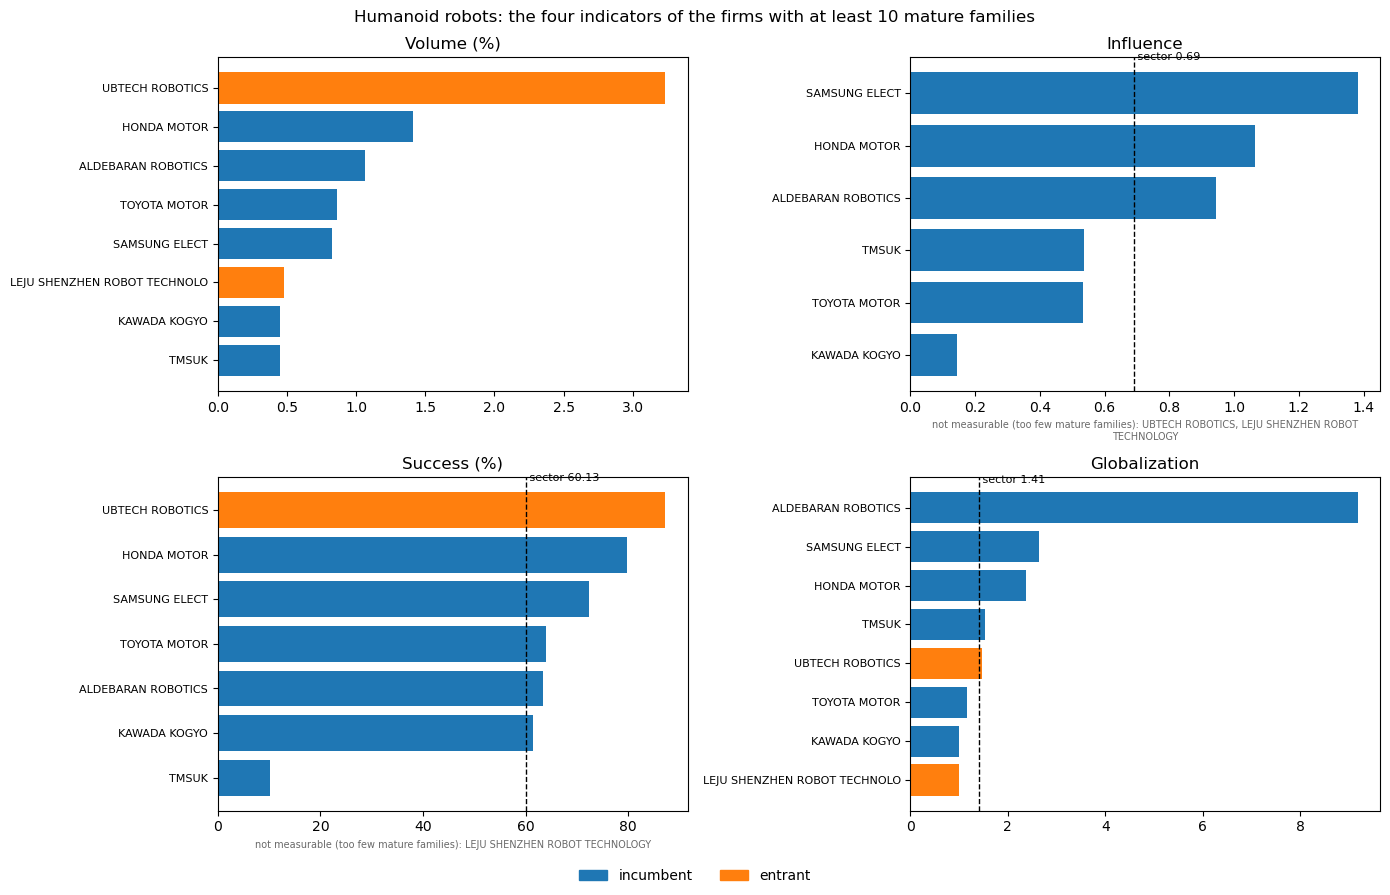

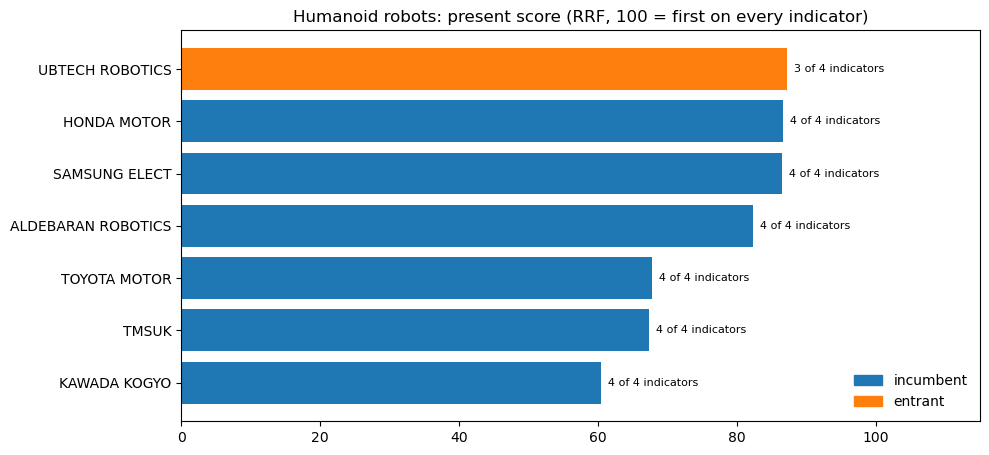

In [43]:
colors = {"incumbent": "tab:blue", "entrant": "tab:orange"}
status = firms_only["status"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, name in zip(axes.ravel(), INDICATORS):
    values = summary.loc[SELECTED, name].astype(float)
    shown = values.dropna().sort_values()
    ax.barh([f[:28] for f in shown.index], shown.values, color=[colors[status[f]] for f in shown.index])
    sector_avg = {"Influence": SECTOR_INFLUENCE, "Success": SECTOR_SUCCESS, "Globalization": SECTOR_GLOBALIZATION}.get(name)
    if sector_avg is not None:                         # the average of the sector, as in the professor's figures
        ax.axvline(sector_avg, color="black", ls="--", lw=1)
        ax.text(sector_avg, len(shown) - 0.4, f" sector {sector_avg:.2f}", fontsize=8, va="bottom")
    ax.set_title(BASE[name])
    ax.tick_params(axis="y", labelsize=8)
    missing = values.index[values.isna()].tolist()
    if missing:
        ax.set_xlabel(textwrap.fill("not measurable (too few mature families): " + ", ".join(missing), width=80), fontsize=7, color="dimgrey")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
fig.legend(handles, list(colors), loc="lower center", ncol=2, frameon=False)
fig.suptitle(f"{SECTOR_NAME}: the four indicators of the firms with at least {MIN_FAMILIES} mature families")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

scored_sorted = present.sort_values("score")
fig, ax = plt.subplots(figsize=(10, 0.45 * len(scored_sorted) + 1.5))
ax.barh([f[:28] for f in scored_sorted.index], scored_sorted["score"], color=[colors[s] for s in scored_sorted["status"]])
for y, (firm, row) in enumerate(scored_sorted.iterrows()):
    ax.text(row["score"] + 1, y, f"{int(row['indicators used'])} of 4 indicators", va="center", fontsize=8)
ax.set(title=f"{SECTOR_NAME}: present score (RRF, 100 = first on every indicator)", xlim=(0, 115))
ax.legend(handles, list(colors), loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

In [44]:
stable = robust.drop(index=base.name)["Kendall tau with ours"]
all_variants = list(ranks.drop(columns=base.name).items()) + list(refined.items())[1:]
top_kept = sum(same_top_group(r) for _, r in all_variants)
top = present.head(N_TOP)
rest = present.iloc[N_TOP:]
recent_share = (families["priority_year"] > GLOBALIZATION_LAST_YEAR).mean()
waiting = NOT_SCORED + recent.head(6).index.tolist()
answer_box(
    "How strong is the present position of the top firms?",
    f"A top group of {N_TOP}: " + ", ".join(f"{SHORT[f]} ({s:.0f})" for f, s in top["score"].items())
    + f", clearly above " + ", ".join(f"{SHORT[f]} ({s:.0f})" for f, s in rest["score"].items())
    + f". The group is the same in {top_kept} of the {len(all_variants)} variants of Sections 8 and 9; the order inside it is not "
    f"(Kendall tau with ours from {stable.min():.2f} to {stable.max():.2f}), so we read it as a group, not as a podium.",
    f"Only {len(SELECTED)} firms of the sector have at least {MIN_FAMILIES} mature families: {recent_share:.0%} of the families have "
    f"a priority year after {GLOBALIZATION_LAST_YEAR}. Not scored yet, and passed to Step 4: {', '.join(f.title() for f in waiting)}.",
)

# the firms that wait for Step 4, with the signals that exist already for young families
wait_tab = pd.DataFrame(index=[f for f in waiting if f in firms_only.index])
wait_fam = fam_firm[fam_firm["firm"].isin(wait_tab.index)].drop_duplicates(["docdb_family_id", "firm"]).merge(
    families[["docdb_family_id", "has_pct", "offices"]], on="docdb_family_id")
wait_tab["families"] = wait_fam.groupby("firm").size()
wait_tab[f"since {LAST_COMPLETE_YEAR + 1}"] = wait_fam[wait_fam["priority_year"] > LAST_COMPLETE_YEAR].groupby("firm").size()
wait_tab["with a PCT application (%)"] = wait_fam.groupby("firm")["has_pct"].mean() * 100     # filed within 12 months: an early sign of reach
wait_tab["offices per family"] = wait_fam.groupby("firm")["offices"].mean()
wait_tab["status"] = firms_only.loc[wait_tab.index, "status"]
print(f"the firms passed to Step 4 (sector: {families['has_pct'].mean():.0%} of the families with a PCT application):")
display(wait_tab.fillna(0).round(1))

present.reset_index(names="firm").to_csv(OUTPUT_DIR / "present_score.csv", index=False)             # read by Step 5
indicators.reset_index(names="firm").to_csv(OUTPUT_DIR / "indicators.csv", index=False)
(firms_only.loc[[f for f in waiting if f in firms_only.index]].reset_index(names="firm")
 .to_csv(OUTPUT_DIR / "firms_for_step4.csv", index=False))
print(f"saved in {OUTPUT_DIR}: present_score.csv, indicators.csv, firms_for_step4.csv")

--------------------------------------------------------------------------------
ANSWER · How strong is the present position of the top firms?
A top group of 4: Ubtech (87), Honda (87), Samsung (87), Aldebaran (82), clearly
above Toyota (68), Tmsuk (67), Kawada Kogyo (60). The group is the same in 18 of
the 18 variants of Sections 8 and 9; the order inside it is not (Kendall tau
with ours from 0.43 to 1.00), so we read it as a group, not as a podium.
Only 8 firms of the sector have at least 10 mature families: 59% of the families
have a priority year after 2021. Not scored yet, and passed to Step 4: Leju
Shenzhen Robot Technology, Guangzhou Ligong Industrial, Shanghai Fourier
Intelligent Technology, Shenzhen Zhuji Power Technology, Figure Ai, Renxing
Robot Shanghai, Jiangsu Yunmu Zhizao Technology.
--------------------------------------------------------------------------------
the firms passed to Step 4 (sector: 6% of the families with a PCT application):


,families,since 2023,with a PCT application (%),offices per family,status
LEJU SHENZHEN ROBOT TECHNOLOGY,14,4,0.0,1.0,entrant
GUANGZHOU LIGONG INDUSTRIAL,92,92,0.0,1.0,entrant
SHANGHAI FOURIER INTELLIGENT TECHNOLOGY,91,91,3.3,1.0,entrant
SHENZHEN ZHUJI POWER TECHNOLOGY,59,59,0.0,1.0,entrant
FIGURE AI,44,44,18.2,1.0,entrant
RENXING ROBOT SHANGHAI,31,31,3.2,1.0,entrant
JIANGSU YUNMU ZHIZAO TECHNOLOGY,26,26,0.0,1.0,entrant


saved in outputs/step3: present_score.csv, indicators.csv, firms_for_step4.csv


**Our answer.** Four firms have a strong present position in humanoid-robot patents, each for a different reason:

- **UBTECH**, the entrant: the largest portfolio (3.2% of the sector's families, 3.9% since 2015), the highest grant rate (87%) and the largest reach in the sector (3.4%), but filed mostly in China and never in all four main markets;
- **Honda**, the pioneer: second on Volume, Influence and Success, but its families date from before 2015 (8.2% of the sector then, almost none since), and a quarter of its citations are its own;
- **Samsung**: the most cited portfolio (1.38 times comparable patents, with a median above 1, and still 1.29 without its own citations), filed in two or more offices for 82% of its families;
- **Aldebaran** (NAO, Pepper): the only global portfolio (9.2 offices per family, 86% quadrilateral) and the only one with a broad European protection (EP patents validated in 12.5 states on average), and the highest share of citations added by competitors rather than examiners.

The OECD Patent Quality Indicators, available for the US patents of these four firms, rank Aldebaran first and UBTECH last (Section 9.2); computed with the OECD method on all their families, the index keeps Aldebaran first and puts UBTECH next to Honda and Samsung (Section 9.3). The order inside the group depends on what one values.

Toyota, Tmsuk and Kawada are far behind; Tmsuk is worth a look only for its share of blocking patents.

For Electrolux, a European group, two points follow. Only Aldebaran is well protected in Europe: the others protect their humanoids mainly in Asia and the United States. And the strength of the Japanese and Korean incumbents is a past one, because their families stop around 2015. The firms that file today, the Chinese entrants and Figure AI, are not in this score: Step 4 measures them.

**The firms that wait for Step 4.** Six of the seven firms passed to Step 4 filed all their families from 2023 on (Guangzhou Ligong 92, Shanghai Fourier 91, Shenzhen Zhuji Power 59, Figure AI 44, Renxing 31, Jiangsu Yunmu 26); Leju has 14. None of their families has reached a second office yet (1.0 office per family), as expected for families this young. The one early signal of reach is the PCT application, filed within twelve months: Figure AI has one for 18% of its families, the Chinese entrants for 0 to 3% (sector 6%). Figure AI is the only one of them already preparing protection abroad.

**Limits that we declare, and what we did about them.**

- **The present score covers the generation that is old enough to be measured.** Only 8 firms have at least 10 mature families (priority year up to 2021); the firms whose families arrived later, among them the largest Chinese entrants and Figure AI, cannot be measured on citations, grants or offices yet. We do not score them on Volume alone: the cell above lists them with the signals that already exist for young families (PCT applications, offices), and Step 4 scores them with forward-looking indicators.
- **The sector is defined by titles** (Step 0, precision 92.5%): firms that title their humanoid patents "legged robot" or only "robot" are under-represented (Section 2.4 counts their patents outside the sector). Widening the rule was tested in Step 0 and lowered the precision below 70%.
- **Citations: offices, origins and self-citations.** Influence counts the citations between families of all offices, as notebook 40 and the OECD do. We checked the two biases: without the firm's own citations (Section 5.5, a variant in Section 8), and with the benchmark of the office of first filing. The origin of a citation (applicant or examiner) exists only at the level of publications, so we use it where it matters: the localisation test (Section 6) and the share of applicant citations (Section 5.5).
- **`granted`** mixes refused, withdrawn and pending applications: the legal events separate them (Section 5.3), and Success on the decided applications alone is a variant in Section 8. Offices report legal events unevenly, so part of "pending or unknown" is unknown.
- **Ready-made indicators.** The OECD Patent Quality Indicators files cover only EP and US patents, 7% of our families: we use them as a check (Section 9.2). To reach the other families we computed the OECD quality index with the OECD method from PATSTAT for every family up to 2021 (Section 9.3); it reaches 781 families against 210, but it is scaled inside the sector, not inside the OECD's cohorts of field and year, and PATSTAT reports the number of claims only for EP and US publications (13% of the families), so it rests mostly on three components.
- **Geography.** The inventor's country is known for 16% of the families; the other countries are filled from the applicants and the first office (Section 6.1), and every test is shown both ways. Distances are measured between countries, not regions: notebook 31's distance in kilometres needs NUTS 3 regions, and our sector has 59 families with an inventor in Europe.
- **Readings that could go either way** (as the course asks, we say which one we take): backward citations describe the prior art and are not used as a quality indicator (Section 3.1); grant lag is not used, because a long examination can mean strength or weakness; a family owned by two firms counts in full for each of them (co-applicants).